# 0. Introduction

In this mini‑project, we aim to predict what a mouse perceives and does from its brain activity. Each trial in the dataset is a 3‑second window where the mouse hears a tone, may receive a whisker deflection, and can choose to lick for a reward. The trial label `TRIAL_TYPE` encodes which stimuli were present and whether the mouse licked or not, and the input features are average spike counts in 100 ms bins for different neuron types and cortical areas.


The main questions we try to answer are:  
- How much of the variability in the neural data comes from behaviour versus mouse or session identity?  
- Which preprocessing steps (normalization, handling of missing values, feature selection) are necessary to obtain robust performance across sessions?  
- Is a linear model already sufficient for good accuracy, or do we clearly benefit from using non‑linear models on this dataset?


## 0.1 Core libraries and basic setup

Before inspecting the data, we import the core scientific Python libraries and scikit‑learn tools that we will use throughout the notebook. We also switch off non‑critical warnings so that the output is easier to read.


In [42]:
# =========================
# Core libraries
# =========================
from pathlib import Path
from collections import Counter
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# =========================
# scikit-learn: configuration / experimental enablers
# =========================
from sklearn import set_config
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.experimental import enable_halving_search_cv  # noqa: F401

# =========================
# scikit-learn: model selection
# =========================
from sklearn.model_selection import (
    StratifiedKFold,
    GroupKFold,
    LeaveOneGroupOut,
    HalvingGridSearchCV,
)

# =========================
# scikit-learn: preprocessing & decomposition
# =========================
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

# =========================
# scikit-learn: imputation
# =========================
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer

# =========================
# scikit-learn: feature selection
# =========================
from sklearn.feature_selection import SelectKBest, f_classif

# =========================
# scikit-learn: models
# =========================
from sklearn.linear_model import LogisticRegression, BayesianRidge
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier

# =========================
# scikit-learn: pipeline
# =========================
from sklearn.pipeline import Pipeline

# =========================
# scikit-learn: metrics
# =========================
from sklearn.metrics import (
    accuracy_score,
    mean_squared_error,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# =========================
# XGBoost
# =========================
from xgboost import XGBClassifier


## 0.2 Reproducibility and plotting style

We fix a random seed for NumPy and scikit‑learn to make our experiments reproducible, and we set a basic plotting style (white grid and a default figure size) for all figures in the notebook.


In [32]:
# Set random seed for reproducibility
SEED = 0

# Plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Setup complete! Random seed:", SEED)

Setup complete! Random seed: 0


# 1. Data inspection



## 1.1 Loading the data and basic structure

In this first step we load the Kaggle training and test sets, together with the sample submission file, and check that their shapes and columns match the description of the challenge. We also identify the target column (`TRIAL_TYPE`) and derive a simple `mouse_id` from the `session_id`, which we will reuse later for grouping and visualization.



In [23]:
# Load the data
DATA_DIR = Path('../data/raw')

train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
sample_sub = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print("Data loaded!")
print(f"Training set: {train_df.shape[0]} samples, {train_df.shape[1]} columns")
print(f"Test set: {test_df.shape[0]} samples, {test_df.shape[1]} columns")
print("Submission template columns:", list(sample_sub.columns))

Data loaded!
Training set: 4407 samples, 1383 columns
Test set: 2292 samples, 1382 columns
Submission template columns: ['ID', 'TRIAL_TYPE']


### 1.1 Results and short conclusion

- The training set contains 4 407 trials with 1 383 columns, and the test set contains 2 292 trials with 1 382 columns, so the only extra column in train is the label.  
- The submission template expects `ID` and `TRIAL_TYPE`, confirming that this is a multiclass trial‑level classification problem.

Conclusion. The data load correctly and the basic structure matches the competition description. Next, we look at how labels and trials are distributed across mice and sessions to understand potential class imbalance and recording biases.

## 1.2 Behavioural labels, class imbalance and dataset structure


Here we inspect how `TRIAL_TYPE` labels are distributed and how trials are split across mice and sessions. We want to see whether some behavioural classes are much more frequent than others and whether certain mice or sessions dominate the dataset, since this could bias training and cross‑validation.



Target column: TRIAL_TYPE
Number of classes: 10


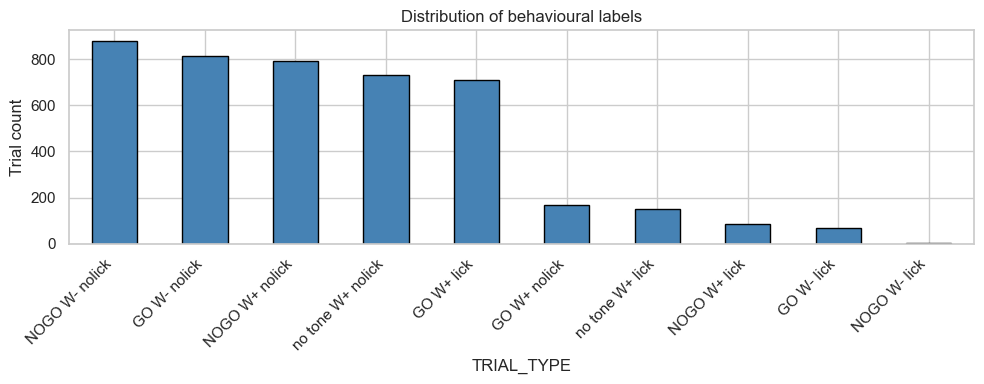


Trials per mouse:


,trial_count
mouse_id,
PG084,1260
PG083,1089
PG085,1089
PG082,969



Trials per session (top 10):


,trial_count
session_id,
PG084_20221207,752
PG082_20221113,662
PG083_20221125,636
PG085_20221214,556
PG085_20221213,533
PG084_20221206,508
PG083_20221129,453
PG082_20221114,307


Total sessions in train: 8


In [11]:
# Identify target column and basic label statistics
target_col = list(sorted(set(train_df.columns) - set(test_df.columns)))[0]
print(f"Target column: {target_col}")
print(f"Number of classes: {train_df[target_col].nunique()}")

plt.figure(figsize=(10, 4))
train_df[target_col].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Distribution of behavioural labels')
plt.xlabel('TRIAL_TYPE')
plt.ylabel('Trial count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Helper metadata columns
train_df['mouse_id'] = train_df['session_id'].str.split('_').str[0]
test_df['mouse_id'] = test_df['session_id'].str.split('_').str[0]

print('\nTrials per mouse:')
display(train_df['mouse_id'].value_counts().rename('trial_count').to_frame())

session_counts = train_df['session_id'].value_counts().rename('trial_count')
print('\nTrials per session (top 10):')
display(session_counts.head(10).to_frame())
print(f"Total sessions in train: {session_counts.shape[0]}")

### 1.2 Commentary on label and session statistics

The label histogram shows that a few trial types dominate the dataset: no‑lick conditions with or without whisker stimulation have several hundred trials each, whereas many lick conditions are much rarer. This means that a classifier can already reach a non‑trivial accuracy by focusing on the majority classes, so later we need to keep class imbalance in mind when interpreting results.

The tables below the plot confirm that trials are not evenly split across mice and sessions. Mouse PG084 contributes more than 1 200 trials, while the other three mice contribute around 1 000 each, and a small number of sessions (for example `PG084_20221207` or `PG082_20221113`) account for a large fraction of all trials.

Overall, already at this stage we see that both class frequencies and recording sessions are heterogeneous. In the next steps we will look at the structure of the neural features and at session‑level activity patterns to understand how these imbalances might affect preprocessing and evaluation.


## 1.3 Feature structure: areas, layers and time bins

 
Here we try to understand what each feature column corresponds to in terms of brain area, cortical layer, cell type and time bin. This makes later plots and model results easier to interpret, because we can talk about specific regions and layers instead of anonymous column names.



In [13]:
# First, let's parse the column structure
import re

# Get feature columns (excluding metadata)
feature_cols = [col for col in train_df.columns if col not in [target_col, 'session_id', 'trial_number', 'mouse_id']]

# Parse column names to extract brain area, layer, cell type, and time
parsed_columns = []
for col in feature_cols:
    match = re.match(r'(.+?)_(L\d+[a-b]?(?:/\d+)?)_(\w+)_time_(\d+)', col)
    if match:
        parsed_columns.append({
            'column': col,
            'area': match.group(1),
            'layer': match.group(2),
            'cell_type': match.group(3),
            'time': int(match.group(4))
        })

column_df = pd.DataFrame(parsed_columns)
brain_areas = sorted(column_df['area'].unique())
cell_types = sorted(column_df['cell_type'].unique())
mice = train_df['mouse_id'].unique()

print(f"Data structure: {len(column_df)} features across {len(brain_areas)} brain areas")
print(f"Mice in dataset: {mice}")
print(f"Cell types in dataset: {cell_types}")
print(f"Layers in dataset: {column_df['layer'].unique()}")

Data structure: 1380 features across 5 brain areas
Mice in dataset: ['PG082' 'PG083' 'PG084' 'PG085']
Cell types in dataset: ['EXC', 'INH']
Layers in dataset: ['L1' 'L6b' 'L6a' 'L5' 'L4' 'L2/3']


In [14]:
# Display parsed feature metadata as a summary table

# Ensure column_df is available (parsed in a previous cell)
meta_summary = (
    column_df.groupby(['area', 'layer', 'cell_type'])
    .size()
    .reset_index(name='n_features')
    .sort_values(['area', 'layer', 'cell_type'])
)

display(meta_summary)

,area,layer,cell_type,n_features
0,A1,L1,EXC,30
1,A1,L1,INH,30
2,A1,L4,EXC,30
3,A1,L4,INH,30
4,A1,L5,EXC,30
5,A1,L5,INH,30
6,A1,L6a,EXC,30
7,A1,L6a,INH,30
8,A1,L6b,EXC,30
9,A1,L6b,INH,30


### 1.3 Commentary and short conclusion

The summary table shows a very regular structure: for each cortical area (A1, ALM, wM2, wS1, wS2), each layer–cell‑type pair (for example L2/3‑EXC or L5‑INH) contributes exactly 30 features, corresponding to the 30 time bins from −1 s to +2 s around trial start. In total, this gives 1 380 neural features spread across 5 areas, multiple layers and two main cell types (EXC and INH).

Conclusion. The feature matrix is highly structured and symmetric across areas, layers and time, which will be useful when we later average activity over specific regions or time windows and when we interpret which parts of the circuit contribute most to decoding. In the next sections, we use this structure to examine how activity evolves over time and how it varies across sessions.


## 1.4 Task-related dynamics across cortical areas


Here we look at how average activity evolves over time in different cortical areas for key behavioural contrasts: GO vs NOGO vs no‑tone in auditory cortex, whisker+ vs whisker− in somatosensory cortex, and lick vs no‑lick in motor areas. This should reveal whether neural responses are aligned to tone and whisker events and whether motor areas already separate lick from no‑lick trials.



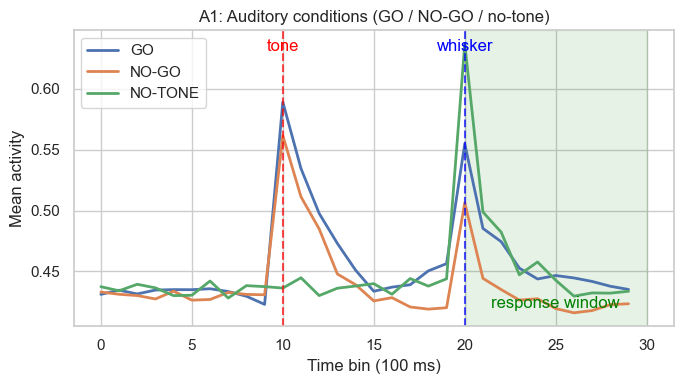

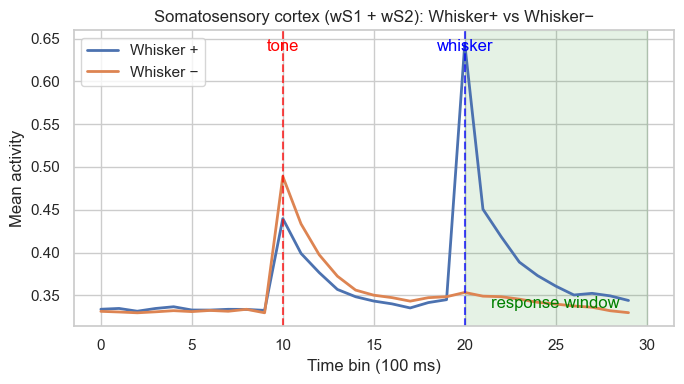

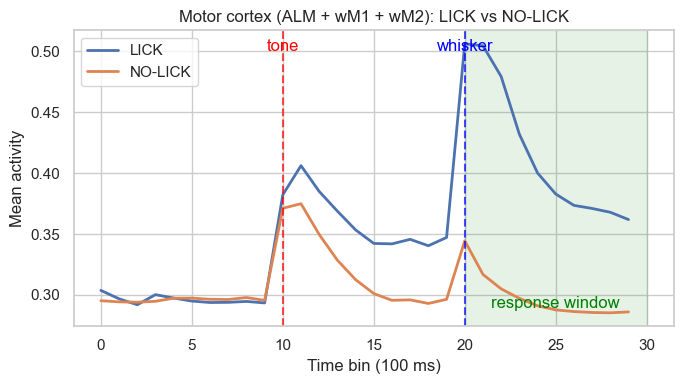

In [110]:
TIME_BINS = np.arange(30)

# -----------------------------
# Helper: plot one condition set
# -----------------------------
def plot_area_conditions(area_cols, condition_masks, title):
    plt.figure(figsize=(7, 4))
    
    for label, mask in condition_masks.items():
        trace = []
        for t in TIME_BINS:
            cols_t = area_cols[area_cols["time"] == t]["column"].tolist()
            if len(cols_t) == 0:
                trace.append(np.nan)
                continue
            vals = train_df.loc[mask, cols_t].mean(axis=1)
            trace.append(vals.mean())
        plt.plot(TIME_BINS, trace, label=label, linewidth=2)

    # task events
    plt.axvline(10, color="red", linestyle="--", alpha=0.7)   # tone
    plt.axvline(20, color="blue", linestyle="--", alpha=0.7)  # whisker
    plt.axvspan(20, 30, color="green", alpha=0.1)             # response window

    # get axis limits once, then place labels slightly below the top
    ymin, ymax = plt.ylim()
    y_tone = ymax - 0.03 * (ymax - ymin)
    y_whisker = ymax - 0.03 * (ymax - ymin)
    y_resp = ymin + 0.05 * (ymax - ymin)

    # labels centered on the corresponding x positions
    plt.text(10, y_tone, "tone", color="red", ha="center", va="top")
    plt.text(20, y_whisker, "whisker", color="blue", ha="center", va="top")
    plt.text(25, y_resp, "response window", color="green", ha="center", va="bottom")

    plt.title(title)
    plt.xlabel("Time bin (100 ms)")
    plt.ylabel("Mean activity")
    plt.legend()
    plt.tight_layout()
    plt.show()

# =========================================================
# 1) A1 — GO vs NO-GO vs NO-TONE (auditory cortex)
# =========================================================
a1_cols = column_df[column_df["area"] == "A1"]

a1_conditions = {
    "GO":       train_df[target_col].str.startswith("GO"),
    "NO-GO":    train_df[target_col].str.startswith("NOGO"),
    "NO-TONE":  train_df[target_col].str.startswith("no tone"),
}

plot_area_conditions(
    area_cols=a1_cols,
    condition_masks=a1_conditions,
    title="A1: Auditory conditions (GO / NO-GO / no-tone)"
)

# =========================================================
# 2) Somatosensory cortex — Whisker+ vs Whisker− (wS1 + wS2)
# =========================================================
somato_cols = column_df[column_df["area"].isin(["wS1", "wS2"])]

somato_conditions = {
    "Whisker +": train_df[target_col].str.contains("W\\+"),
    "Whisker −": train_df[target_col].str.contains("W\\-"),
}

plot_area_conditions(
    area_cols=somato_cols,
    condition_masks=somato_conditions,
    title="Somatosensory cortex (wS1 + wS2): Whisker+ vs Whisker−"
)

# =========================================================
# 3) Motor cortex — LICK vs NO-LICK (ALM + wM1 + wM2)
# =========================================================
motor_cols = column_df[column_df["area"].isin(["ALM", "wM1", "wM2"])]

motor_conditions = {
    "LICK":    train_df[target_col].str.contains("lick") & ~train_df[target_col].str.contains("nolick"),
    "NO-LICK": train_df[target_col].str.contains("nolick"),
}

plot_area_conditions(
    area_cols=motor_cols,
    condition_masks=motor_conditions,
    title="Motor cortex (ALM + wM1 + wM2): LICK vs NO-LICK"
)


### 1.4 Commentary and short conclusion

Across areas, neural activity follows the task timeline: there is an early peak around tone onset, a later peak around whisker stimulation, and sustained activity into the response window. In auditory cortex (A1), GO and NOGO trials already differ from no‑tone trials shortly after the tone, while in somatosensory areas (wS1 + wS2) the main separation appears around the whisker onset.

In motor areas (ALM + wM1 + wM2), lick and no‑lick trials diverge clearly even before the formal response window, suggesting that the mouse prepares the lick rather than only reacting at the moment of licking. The differences between conditions mostly look like shifts in mean activity over time rather than completely different response shapes, which suggests that a linear model on time‑binned features could already capture a substantial part of the signal.



## 1.5 Baseline-subtracted activity across layers and sessions


Here we compare how baseline‑corrected activity evolves over time across cortical layers and recording sessions. For each trial, we subtract its own pre‑stimulus baseline so that we can see task‑evoked changes relative to that trial’s baseline rather than absolute firing rates, and then average per layer and session.



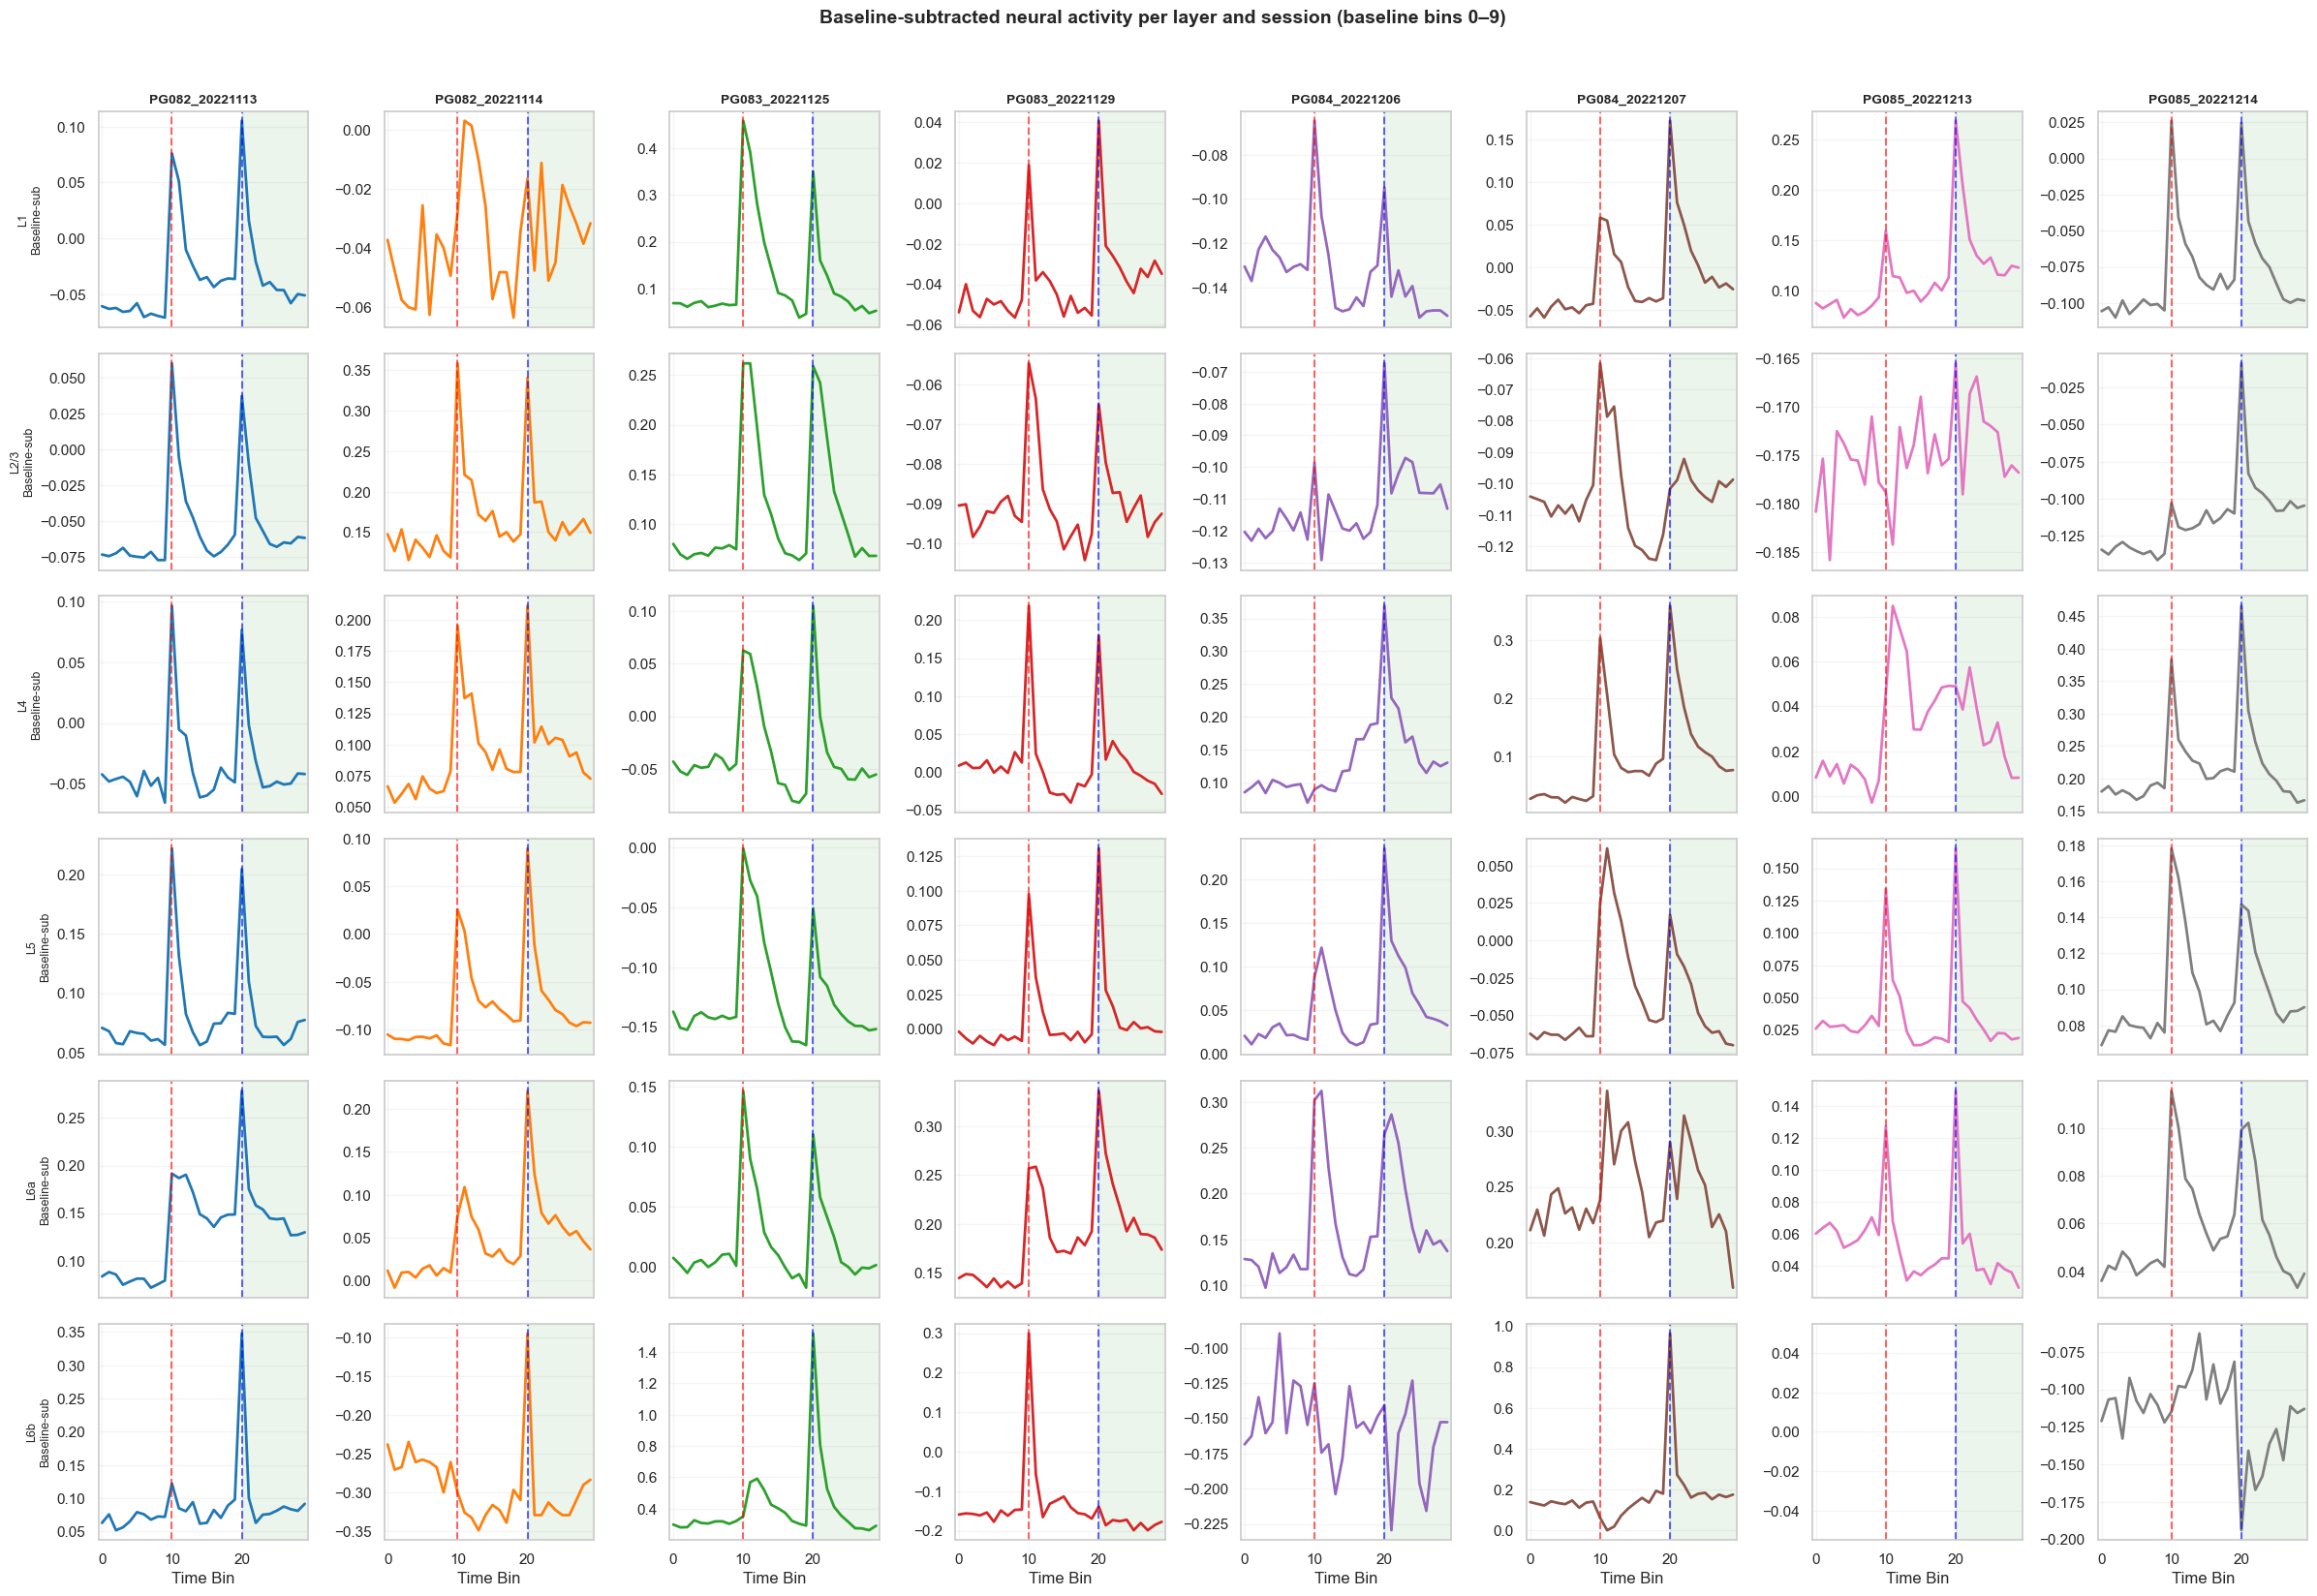

In [52]:
# Baseline-normalized (per trial) activity per cortical layer, per session
layers = ['L1', 'L2/3', 'L4', 'L5', 'L6a', 'L6b']
sessions = sorted(train_df['session_id'].unique())

# Map feature -> time bin
col_time = column_df.set_index('column')['time']
baseline_bins = list(range(0, 10))
baseline_cols = [c for c in feature_cols if col_time[c] in baseline_bins]

def baseline_normalize_trials(df, features, baseline_cols):
    df = df.copy()
    # per-trial baseline mean over baseline time bins
    baseline_mean = df[baseline_cols].mean(axis=1)
    df[features] = df[features].sub(baseline_mean, axis=0)
    return df

bn_df = baseline_normalize_trials(train_df, feature_cols, baseline_cols)

fig, axes = plt.subplots(len(layers), len(sessions), figsize=(3 * len(sessions), 2.8 * len(layers)), sharex=True)
session_colors = sns.color_palette("tab10", n_colors=len(sessions))

for row_idx, layer in enumerate(layers):
    layer_cols = column_df[column_df['layer'] == layer]
    for col_idx, session in enumerate(sessions):
        ax = axes[row_idx, col_idx]
        sess_mask = bn_df['session_id'] == session
        X_sess = bn_df.loc[sess_mask, feature_cols]

        time_activity = []
        for t in range(30):
            time_cols = layer_cols[layer_cols['time'] == t]['column'].tolist()
            if time_cols:
                mean_act = X_sess[time_cols].mean(axis=1).mean()  # mean over neurons (layer/time), then trials
                time_activity.append(mean_act)
            else:
                time_activity.append(np.nan)

        ax.plot(range(30), time_activity, color=session_colors[col_idx % len(session_colors)], linewidth=2)
        ax.axvline(x=10, color='red', linestyle='--', alpha=0.6)
        ax.axvline(x=20, color='blue', linestyle='--', alpha=0.6)
        ax.axvspan(20, 30, color='green', alpha=0.08)

        if row_idx == 0:
            ax.set_title(session, fontsize=10, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(f'{layer}\nBaseline-sub', fontsize=9)
        if row_idx == len(layers) - 1:
            ax.set_xlabel('Time Bin')

        ax.set_xlim(-0.5, 29.5)
        ax.grid(True, alpha=0.2)

plt.suptitle('Baseline-subtracted neural activity per layer and session (baseline bins 0–9)', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 1.5 Commentary and short conclusion


After subtracting each trial’s own pre‑tone baseline (bins 0–9), we still recover the main task‑locked structure in almost all panels: a first peak around the tone and a second around the whisker and response window. This suggests that baseline subtraction mainly recenters activity without destroying the overall temporal profile seen in the previous area‑specific plots.

At the same time, the grid reveals clear variability across both layers and sessions. One layer–session combination is essentially empty, indicating that these signals were not recorded in that session at all, whereas others show unusual dynamics; for instance, in the last session, layer L6b displays a much weaker and noisier response than in earlier sessions, suggesting atypical recording quality. These differences are important to keep in mind later when we handle missing values and when we choose an appropriate cross‑validation strategy.

# 2. Preprocessing



## 2.1 Batch effects: PCA by mouse and session


Here we check how strongly mouse and session identity structure the neural activity before any advanced preprocessing. We first look at PCA colored by `mouse_id`, then by `session_id`.



### 2.1.1 Low-dimensional batch structure by mouse



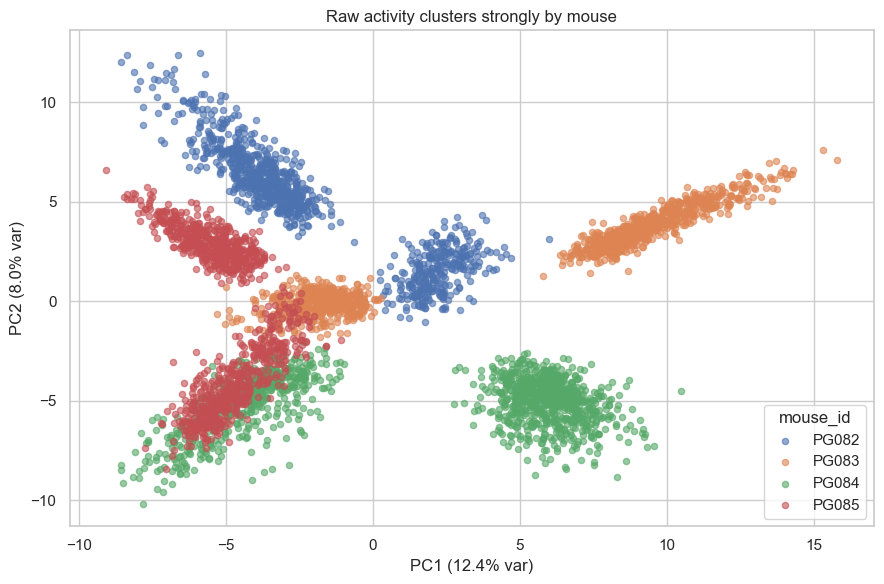

In [9]:
# PCA on raw activity (simple zero-fill for visualization)
X_raw_matrix = train_df[feature_cols].fillna(0)
pca_raw = PCA(n_components=2, random_state=SEED)
X_pca_raw = pca_raw.fit_transform(X_raw_matrix)

plt.figure(figsize=(9, 6))
for mouse in train_df['mouse_id'].unique():
    mask = train_df['mouse_id'] == mouse
    plt.scatter(X_pca_raw[mask, 0], X_pca_raw[mask, 1], label=mouse, alpha=0.6, s=20)
plt.xlabel(f"PC1 ({pca_raw.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PC2 ({pca_raw.explained_variance_ratio_[1]*100:.1f}% var)")
plt.title("Raw activity clusters strongly by mouse")
plt.legend(title='mouse_id')
plt.tight_layout()
plt.show()

The PCA on the raw activity already shows a strong batch structure: trials cluster very clearly by mouse, with almost no overlap between animals in the PC1–PC2 space. Within each mouse, the points further split into roughly two sub‑clusters, suggesting additional structure at the session level.


#### 2.1.2 Low-dimensional batch structure by session


,n_sessions
mouse_id,
PG082,2
PG083,2
PG084,2
PG085,2


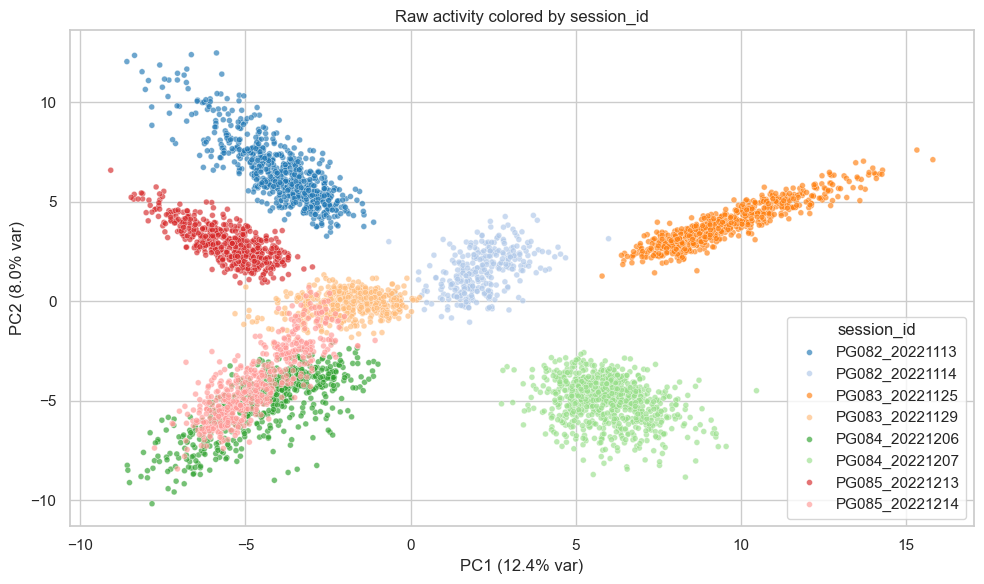

In [10]:

session_counts = (
    train_df.groupby('mouse_id')['session_id']
    .nunique()
    .sort_values(ascending=False)
)
display(session_counts.to_frame(name='n_sessions'))

X_raw_matrix = train_df[feature_cols].fillna(0)
pca_session = PCA(n_components=2, random_state=SEED)
X_pca_session = pca_session.fit_transform(X_raw_matrix)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_pca_session[:, 0],
    y=X_pca_session[:, 1],
    hue=train_df['session_id'],
    palette='tab20',
    s=18,
    alpha=0.65,
    legend='full'
)
plt.xlabel(f"PC1 ({pca_session.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PC2 ({pca_session.explained_variance_ratio_[1]*100:.1f}% var)")
plt.title("Raw activity colored by session_id")
plt.tight_layout()
plt.show()


Coloring the same embedding by `session_id` confirms that the sub‑clusters seen within each mouse correspond to individual recording sessions. Each session forms a compact cloud in PC space, and mice with more sessions are split into several well‑separated groups. This shows that a large part of the variance in the raw features is driven by session‑specific offsets rather than purely by behaviour.


## 2.2 Effect of different normalizations


Here we compare how different normalization schemes change the clustering of trials by session and mouse in a low‑dimensional space. We test raw features, global z‑score, per‑mouse z‑score, per‑session z‑score and per‑session centering, and visualize each representation with PCA to see which one best reduces session‑specific offsets without destroying task‑related structure.


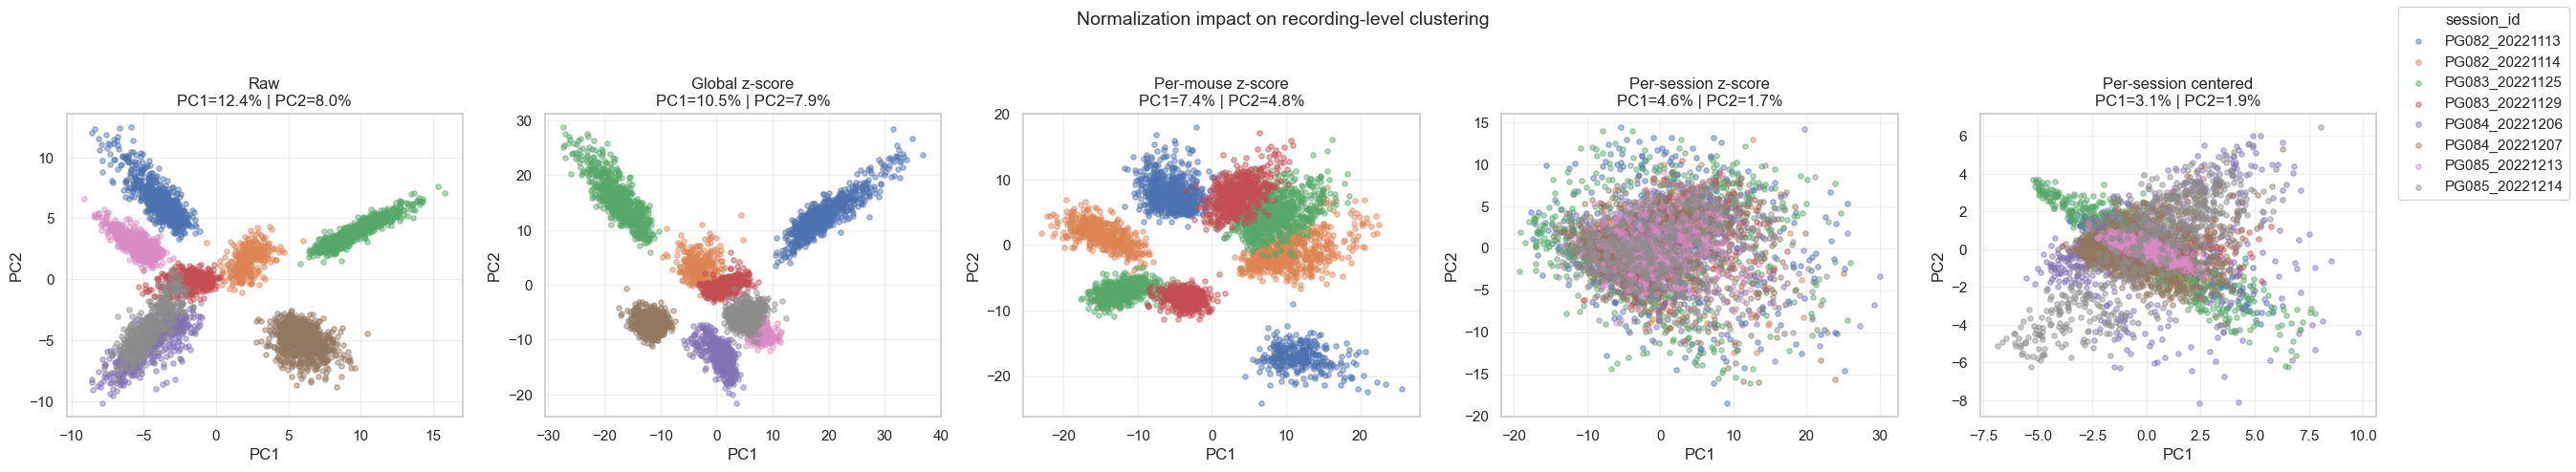

In [48]:
def global_zscore(df: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    scaler = StandardScaler()
    transformed = scaler.fit_transform(df[features].fillna(0))
    return pd.DataFrame(transformed, index=df.index, columns=features)

def _per_group_zscore(df: pd.DataFrame, features: list[str], group_col: str) -> pd.DataFrame:
    zscored = pd.DataFrame(index=df.index, columns=features, dtype=float)
    for group, block in df.groupby(group_col):
        scaler = StandardScaler()
        transformed = scaler.fit_transform(block[features].fillna(0))
        zscored.loc[block.index, features] = transformed
    return zscored

def per_session_center(df: pd.DataFrame, features: list[str], session_col: str) -> pd.DataFrame:
    centered = pd.DataFrame(index=df.index, columns=features, dtype=float)
    for sid, block in df.groupby(session_col):
        mat = block[features].fillna(0)
        centered.loc[block.index, features] = mat - mat.mean()
    return centered



def per_mouse_zscore(df: pd.DataFrame, features: list[str], mouse_col: str) -> pd.DataFrame:
    return _per_group_zscore(df, features, mouse_col)

def per_session_zscore(df: pd.DataFrame, features: list[str], session_col: str) -> pd.DataFrame:
    return _per_group_zscore(df, features, session_col)

def project_pca(matrix: pd.DataFrame, *, n_components: int = 2) -> tuple[np.ndarray, np.ndarray]:
    pca = PCA(n_components=n_components, random_state=SEED)
    embedding = pca.fit_transform(matrix.fillna(0))
    return embedding, pca.explained_variance_ratio_

X_raw_frame = train_df[feature_cols]
X_global_z = global_zscore(train_df, feature_cols)
X_mouse_z = per_mouse_zscore(train_df, feature_cols, 'mouse_id')
X_session_z = per_session_zscore(train_df, feature_cols, 'session_id')
X_per_session_center = per_session_center(train_df, feature_cols, 'session_id')

representations = [
    ("Raw", X_raw_frame, train_df['session_id']),
    ("Global z-score", X_global_z, train_df['session_id']),
    ("Per-mouse z-score", X_mouse_z, train_df['mouse_id']),
    ("Per-session z-score", X_session_z, train_df['session_id']),
    ("Per-session centered", X_per_session_center, train_df['session_id']),
]

fig, axes = plt.subplots(1, 5, figsize=(27, 5))
for ax, (title, matrix, hue_series) in zip(axes, representations):
    embedding, variance = project_pca(matrix)
    labels = hue_series.astype(str)
    for label in labels.unique():
        mask = labels == label
        ax.scatter(embedding[mask, 0], embedding[mask, 1], label=label, alpha=0.45, s=15)
    ax.set_title(f"{title}\nPC1={variance[0]*100:.1f}% | PC2={variance[1]*100:.1f}%")
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.grid(alpha=0.3)

handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title=hue_series.name)
fig.suptitle('Normalization impact on recording-level clustering', fontsize=14)
plt.tight_layout(rect=[0, 0, 0.93, 0.95])
plt.show()

### 2.2 Commentary and short conclusion

In the raw representation, trials form compact, well‑separated clusters by session, and the first two principal components explain about 12.4% and 8.0% of the variance, respectively. After applying a global z‑score, the overall scale changes slightly and the explained variance of PC1/PC2 drops to about 10.5% and 7.9%, but the session clusters remain clearly visible. Per‑mouse z‑scoring distributes the sessions of each mouse more evenly in the embedding and further reduces the variance captured by PC1/PC2 (around 7.4% and 4.2%).

Per‑session z‑score and per‑session centering both substantially blur the original session clusters and lead to a tighter overlap between recordings in PC space. In these two normalizations, the first two principal components explain less variance (around 4.6%/1.7% for per‑session z‑score and 3.1%/1.9% for per‑session centering), which means more of the variance now lives in higher‑order components instead of the first two.

These PCA plots also suggest how we should evaluate models: because whole sessions form tight clusters, mixing trials from the same session between train and validation would make the task artificially easy and could hide overfitting to session‑specific patterns. To get a more realistic estimate of generalization, it therefore makes sense to use a scheme where entire sessions are held out at once (leave‑one‑session‑out), and to apply the chosen normalization separately within the training data of each fold.

## 2.3 Missing values and session differences


Here we quantify how many values are missing in the feature matrix and how this missingness is distributed across sessions and mice. The baseline‑subtracted plots already suggested that some layer–session combinations might be absent or unusual; here we make this more explicit with a heatmap and summary statistics.



Missing values across feature matrix: 1,172,310 (19.3%)


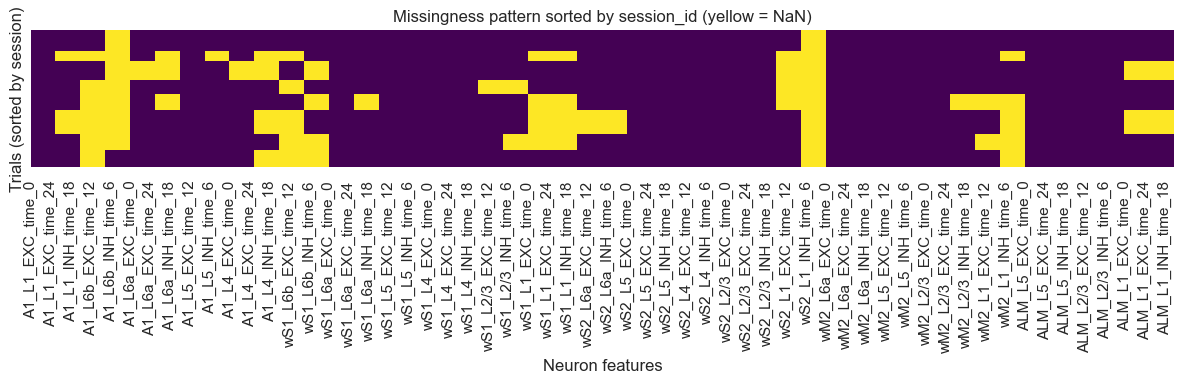

,missing_%,mean_activity,std_activity,mouse_id
session_id,,,,
PG082_20221114,26.087,0.408,0.329,PG082
PG083_20221125,21.739,0.394,0.319,PG083
PG082_20221113,4.348,0.385,0.296,PG082
PG084_20221207,28.261,0.376,0.341,PG084
PG085_20221214,13.043,0.376,0.281,PG085
PG085_20221213,21.739,0.361,0.261,PG085
PG083_20221129,15.217,0.315,0.261,PG083
PG084_20221206,26.087,0.314,0.317,PG084


Summary by mouse (for comparison):


,missing_%
mouse_id,
PG082,11.235249
PG083,19.026231
PG084,27.384403
PG085,17.299477


In [111]:
# Feature columns (exclude metadata and target)
metadata_cols = ['session_id', 'trial_number', 'mouse_id', target_col]
feature_cols = [col for col in train_df.columns if col not in metadata_cols]

# Missingness overview
total_values = train_df.shape[0] * len(feature_cols)
missing_values = train_df[feature_cols].isnull().sum().sum()
print(f"Missing values across feature matrix: {missing_values:,} ({100 * missing_values / total_values:.1f}%)")

plt.figure(figsize=(12, 4))
sns.heatmap(train_df.sort_values('session_id')[feature_cols].isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missingness pattern sorted by session_id (yellow = NaN)')
plt.xlabel('Neuron features')
plt.ylabel('Trials (sorted by session)')
plt.tight_layout()
plt.show()

# Session-level summary statistics
session_missing_pct = train_df.groupby('session_id')[feature_cols].apply(lambda block: block.isnull().mean().mean() * 100)
session_mean_activity = train_df.groupby('session_id')[feature_cols].mean().mean(axis=1)
session_std_activity = train_df.groupby('session_id')[feature_cols].std().mean(axis=1)

session_summary = pd.DataFrame({
    'missing_%': session_missing_pct,
    'mean_activity': session_mean_activity,
    'std_activity': session_std_activity,
    'mouse_id': train_df.drop_duplicates('session_id').set_index('session_id')['mouse_id']
}).sort_values('mean_activity', ascending=False)

display(session_summary.head(10).round(3))

print('Summary by mouse (for comparison):')
mouse_summary = train_df.groupby('mouse_id')[feature_cols].apply(lambda block: block.isnull().mean().mean() * 100).rename('missing_%')
display(mouse_summary.to_frame())

### 2.3 Commentary and short conclusion

Across all neural features, roughly 19% of the entries are missing, and the heatmap shows that these NaNs cluster within specific groups of features and sessions rather than being randomly scattered. Some sessions, such as `PG082_20221114`, `PG084_20221207` and `PG085_20221213/14`, have around 20–30% missing values, whereas others like `PG082_20221113` are almost complete. 

The session summary confirms that both missingness and basic activity statistics vary systematically between sessions, and the mouse‑level table shows that some animals (for example PG084) have a much higher overall missing rate than others. This pattern fits with the idea that missing values mainly come from recording logistics (which probes were active in which session) rather than from the behaviour itself. 

These observations imply that imputation choices will matter, especially if we want models to generalize across sessions. In the next subsection we therefore outline which imputation strategies we will plug into the cross‑validated pipelines later on.



For later modelling, we plan to try a few standard imputation strategies rather than committing to a single choice at this stage. The simplest options are feature‑wise mean imputation and filling missing entries with a constant value of 0, which are both fast and easy to integrate into cross‑validation. We also consider a KNN‑based imputer that reconstructs missing values from similar trials in feature space, which can exploit correlations between neurons at the cost of some extra computation. Finally, we may experiment with an IterativeImputer, which models each feature as a function of the others in an iterative way but is more computationally expensive; whether it is worth using will be decided later based on runtime and LOSO accuracy. In all cases, the imputer would be fitted only on the training split of each fold and then applied to the corresponding validation or test data to avoid leaking information across sessions.



## 2.4 Univariate ANOVA filtering

To further reduce the dimensionality before modelling, we apply a univariate ANOVA F‑test between each feature and the trial label `TRIAL_TYPE`, after performing per‑session z‑scoring and a temporary 0 imputation to handle missing values within each session. This yields an F‑score for every neuron–timepoint feature, and the sorted distribution shows a steep drop‑off: only a few hundred features carry most of the univariate signal, while the long tail is nearly uninformative, which motivates restricting the model to the top ≈400 features. Inspecting the selected features reveals two qualitative patterns: excitatory (EXC) units are over‑represented among the high‑F‑score features compared with inhibitory (INH) units, and almost all informative timepoints occur after stimulus onset, confirming the hypothesis that pre‑tone activity mainly reflects shared initial conditions and behaves as noise for trial classification.

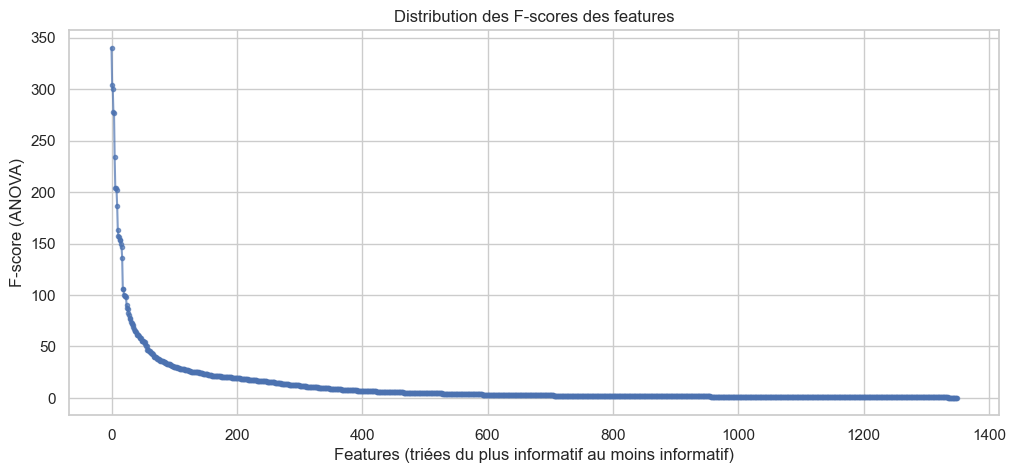

In [27]:
# =============================
# 1. Chargement du train
# =============================
df = pd.read_csv("../data/raw/train.csv")

# Supprimer colonnes constantes
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# =============================
# 2. Normalisation PAR SESSION
# =============================
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X = df[feature_cols].copy()
y = df["TRIAL_TYPE"].copy()

# =============================
# 3. Imputation temporaire pour faire ANOVA correctement
# =============================
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_imp = imputer.fit_transform(X)

# =============================
# 4. Calcul ANOVA F-test
# =============================
F_scores, _ = f_classif(X_imp, y)

# Tri décroissant pour visualisation
F_sorted = np.sort(F_scores)[::-1]

# =============================
# 5. Plot des F-scores
# =============================
plt.figure(figsize=(12,5))
plt.plot(F_sorted, marker='.', linestyle='-', alpha=0.7)
plt.xlabel("Features (triées du plus informatif au moins informatif)")
plt.ylabel("F-score (ANOVA)")
plt.title("Distribution des F-scores des features")
plt.grid(True)
plt.show()

Features totales : 1350
Top features gardées : 400


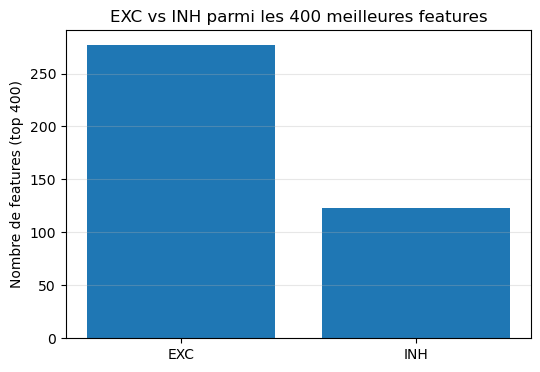

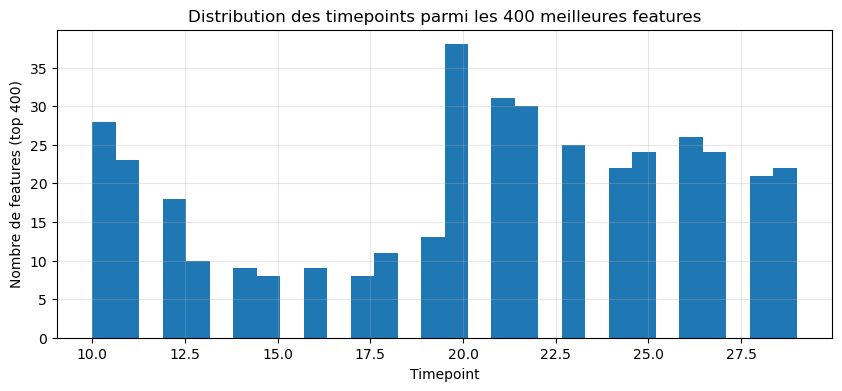

In [ ]:

n_top = 400
idx_sorted = np.argsort(F_scores)[::-1]
top_idx = idx_sorted[:n_top]

top_features = [feature_cols[i] for i in top_idx]
top_F = F_scores[top_idx]

print(f"Features totales : {len(feature_cols)}")
print(f"Top features gardées : {len(top_features)}")

# =============================
# 6. Fonctions simples pour type (EXC/INH) et timepoint
# =============================
def get_cell_type(name: str) -> str:
    # Ex: "A1_L1_EXC_time_0" -> "EXC"
    parts = name.split("_")
    if "EXC" in parts:
        return "EXC"
    if "INH" in parts:
        return "INH"
    return "UNKNOWN"

def get_timepoint(name: str):
    # Ex: "A1_L1_EXC_time_0" -> 0
    parts = name.split("_")
    if "time" in parts:
        i = parts.index("time")
        if i + 1 < len(parts):
            try:
                return int(parts[i + 1])
            except ValueError:
                return None
    # fallback: essayer dernier bout
    try:
        return int(parts[-1])
    except ValueError:
        return None

cell_types = []
timepoints = []
for f in top_features:
    cell_types.append(get_cell_type(f))
    tp = get_timepoint(f)
    if tp is not None:
        timepoints.append(tp)

# =============================
# 7. Plot EXC vs INH
# =============================
counts = Counter(cell_types)

plt.figure(figsize=(6, 4))
plt.bar(list(counts.keys()), list(counts.values()))
plt.ylabel("Nombre de features (top 400)")
plt.title("EXC vs INH parmi les 400 meilleures features")
plt.grid(axis="y", alpha=0.3)
plt.show()

# =============================
# 8. Plot distribution des timepoints
# =============================
plt.figure(figsize=(10, 4))
plt.hist(timepoints, bins=30)
plt.xlabel("Timepoint")
plt.ylabel("Nombre de features (top 400)")
plt.title("Distribution des timepoints parmi les 400 meilleures features")
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
cols_final = ["session_id", "trial_number", "TRIAL_TYPE"] + top_features
df_reduced = df[cols_final].copy()

# =============================
# 11. Sauvegarder dans data/processed
# =============================
output_path = "../data/train_reduced_400.csv"
df_reduced.to_csv(output_path, index=False)

print(f"Dataset réduit sauvegardé dans : {output_path}")
print("Taille originale :", df.shape,
      "Taille réduite :", df_reduced.shape)

Dataset réduit sauvegardé dans : ../data/train_reduced_400.csv
Taille originale : (4407, 1353) Taille réduite : (4407, 403)


## 2.5 Conclusion
Overall, the preprocessing steps suggest that the data are shaped at least as much by recording logistics as by behaviour: PCA reveals strong clustering by mouse and session, simple normalizations redistribute this variance in different ways, and almost one fifth of the feature matrix is missing in a session‑specific pattern. Per‑session transformations and fold‑wise imputation therefore look essential if we want to avoid models simply memorizing session identity. In addition, the univariate ANOVA screen shows that only a few hundred neuron–timepoint features carry most of the label‑relevant variance, with excitatory units and post‑stimulus timepoints over‑represented among the top scores, which justifies using an internal ANOVA step to focus the linear model on the most informative inputs. In the next section we build a linear baseline (multiclass logistic regression) that explicitly takes these findings into account by normalizing within sessions, handling missing values and ANOVA selection inside each fold, and evaluating performance with leave‑one‑session‑out cross‑validation.

# 3. Linear model


## 3.1 Goals and overall setup

Here we build a linear baseline using multiclass logistic regression. Based on the preprocessing results, we want a model that can generalize to unseen sessions, uses per‑session normalization and fold‑wise imputation, and keeps the amount of tuning manageable. We therefore use leave‑one‑session‑out (LOSO) cross‑validation, where each fold holds out one `session_id`.

The next two cells prepare the training dataframe and define the shared LOSO evaluation function: we filter out globally constant features and features that appear in fewer than three sessions, construct the stable feature matrix and groups, and then implement the per‑session normalization, imputation and ANOVA selection that will be reused in all linear‑model experiments.


In [ ]:

# Optional: reduce KNN memory spikes by forcing chunking
set_config(working_memory=32)  # MB, helps avoid large allocations in KNNImputer

TRAIN_PATH = "../data/raw/train.csv"
TEST_PATH  = "../data/raw/test.csv"

TARGET_COL = "TRIAL_TYPE"
GROUP_COL  = "session_id"
ID_COLS    = ["session_id", "trial_number", "TRIAL_TYPE"]

SEED = 0
np.random.seed(SEED)

# Global generalization constraint:
# a feature seen in only 1–2 sessions cannot generalize to a held-out session.
MIN_SESSIONS_PRESENT = 3
df = pd.read_csv(TRAIN_PATH)

# Drop globally constant OR all-NaN features
constant_cols = [c for c in df.columns if c not in ID_COLS and df[c].nunique(dropna=False) <= 1]
df = df.drop(columns=constant_cols)

feature_cols_all = [c for c in df.columns if c not in ID_COLS]

# Count in how many sessions each feature is observed at least once
present = df[feature_cols_all].notna().groupby(df[GROUP_COL]).any()
n_sessions_present = present.sum(axis=0)

stable_feature_cols = n_sessions_present[n_sessions_present >= MIN_SESSIONS_PRESENT].index.tolist()

print(f"Train shape: {df.shape}")
print(f"Features after dropping global constant/all-NaN: {len(feature_cols_all)}")
print(f"Features present in exactly 1 session: {(n_sessions_present==1).sum()}")
print(f"Features present in <=2 sessions: {(n_sessions_present<=2).sum()}")
print(f"Keeping features present in >= {MIN_SESSIONS_PRESENT} sessions: {len(stable_feature_cols)}")


Train shape: (4407, 1353)
Features after dropping global constant/all-NaN: 1350
Features present in exactly 1 session: 30
Features present in <=2 sessions: 60
Keeping features present in >= 3 sessions: 1290


In [ ]:
X_df = df[stable_feature_cols].copy()
y = df[TARGET_COL].copy()
groups = df[GROUP_COL].copy()

logo = LeaveOneGroupOut()
sessions = groups.unique()
print("Number of sessions (folds):", len(sessions))

def zscore_per_session(df_block, feature_cols, group_col=GROUP_COL):
    out = df_block.copy()
    # pandas mean/std ignore NaNs by default -> fine; NaNs remain NaN for the imputer
    out[feature_cols] = out.groupby(group_col)[feature_cols].transform(
        lambda x: (x - x.mean()) / (x.std() + 1e-8)
    )
    return out
"""
def centre_per_session(df_block, feature_cols, group_col=GROUP_COL):
    out = df_block.copy()
    out[feature_cols] = out.groupby(group_col)[feature_cols].transform(
        lambda x: x - x.mean()
    )
    return out
"""
def center_per_session(df: pd.DataFrame, features: list[str], session_col: str) -> pd.DataFrame:
    centered = pd.DataFrame(index=df.index, columns=features, dtype=float)
    for sid, block in df.groupby(session_col):
        mat = block[features].fillna(0)
        centered.loc[block.index, features] = mat - mat.mean()
    return centered

def drop_fold_empty_columns(X_tr, X_te):
    # Drop columns that are all-NaN in training split
    keep = ~np.isnan(X_tr).all(axis=0)
    return X_tr[:, keep], X_te[:, keep], keep

def drop_fold_constant_columns(X_tr, X_te):
    # After imputation, some cols can become constant in a fold -> ANOVA can produce NaNs.
    # We drop them fold-wise to keep selection stable.
    std = X_tr.std(axis=0)
    keep = std > 0
    return X_tr[:, keep], X_te[:, keep], keep

def apply_norm(df_block, feature_cols, norm, group_col=GROUP_COL):
    if norm == "zscore":
        return zscore_per_session(df_block, feature_cols, group_col)
    if norm == "center":
        return center_per_session(df_block, feature_cols, group_col)
    return df_block  # no normalization

def evaluate_setting(k_features, imputer, penalty, C, norm="zscore", verbose_folds=True):
    fold_accs = []
    fold_info = []
    
    for fold_i, (tr_idx, te_idx) in enumerate(logo.split(X_df, y, groups=groups), start=1):
        train_block = df.iloc[tr_idx].copy()
        test_block  = df.iloc[te_idx].copy()
        left_out_session = test_block[GROUP_COL].iloc[0]

        # per-session normalization (z-score, center, or none)
        train_block = apply_norm(train_block, stable_feature_cols, norm, GROUP_COL)
        test_block  = apply_norm(test_block, stable_feature_cols, norm, GROUP_COL)

        X_tr = train_block[stable_feature_cols].to_numpy(dtype=np.float32)
        X_te = test_block[stable_feature_cols].to_numpy(dtype=np.float32)
        y_tr = y.iloc[tr_idx].to_numpy()
        y_te = y.iloc[te_idx].to_numpy()

        # drop fold-empty columns (all-NaN in training)
        X_tr, X_te, _ = drop_fold_empty_columns(X_tr, X_te)

        # impute (fit on training split only)
        X_tr_imp = imputer.fit_transform(X_tr)
        X_te_imp = imputer.transform(X_te)

        # drop fold-constant columns after imputation (keeps ANOVA stable)
        X_tr_imp, X_te_imp, _ = drop_fold_constant_columns(X_tr_imp, X_te_imp)

        # ANOVA feature selection inside fold
        if k_features != "all":
            k = min(int(k_features), X_tr_imp.shape[1])
            selector = SelectKBest(score_func=f_classif, k=k)
            X_tr_final = selector.fit_transform(X_tr_imp, y_tr)
            X_te_final = selector.transform(X_te_imp)
        else:
            X_tr_final, X_te_final = X_tr_imp, X_te_imp

        base_lr = LogisticRegression(
            penalty=penalty,
            C=C,
            solver="liblinear",
            max_iter=2000,
        )
        model = OneVsRestClassifier(base_lr)
        model.fit(X_tr_final, y_tr)
        preds = model.predict(X_te_final)

        acc = accuracy_score(y_te, preds)
        fold_accs.append(acc)
        fold_info.append((fold_i, left_out_session, acc))

        if verbose_folds:
            print(f"  Fold {fold_i:02d} | left-out session={left_out_session} | acc={acc:.4f}")

    mean_acc = float(np.mean(fold_accs))
    std_acc  = float(np.std(fold_accs))
    if verbose_folds:
        print(f"  ==> MEAN ± STD: {mean_acc:.4f} ± {std_acc:.4f}\n")
    return mean_acc, std_acc, fold_info


Number of sessions (folds): 8


### 3.1 Commentary

These two cells set up a consistent environment for all linear‑model experiments. After removing globally constant and very session‑specific features, we keep 1 290 “stable” predictors and define eight LOSO folds, one for each `session_id`. The `evaluate_setting` function then implements the full fold logic: per‑session normalization (either centering or z‑scoring), dropping columns that are empty or constant in the training split, imputing missing values using a chosen strategy, and optionally applying ANOVA feature selection before fitting a one‑vs‑rest logistic regression. This way, every later experiment in Section 3 only needs to specify the normalization, imputer, number of features and regularization parameters, while the cross‑validation protocol and preprocessing steps remain exactly the same across runs.


## 3.2 Exploring feature selection and normalization



### 3.2.1 Baseline sweeps over k and C

In this first step we keep the model simple (mean imputer, l1‑regularized logistic regression) and look at how LOSO accuracy changes as a function of the number of ANOVA‑selected features k and the session normalization (per‑session z‑score vs per‑session centering). We start with a baseline setting C = 1 and sweep k over several values for both normalizations, then repeat exactly the same sweep with a smaller C = 0.03. [file:1]

With C = 1, using all features clearly underperforms and small k values (around 60–100) give noticeably better accuracy for both z‑score and centering. When we switch to C = 0.03, the curves change shape and the ranking between normalizations and k shifts, showing that k and C interact with each other and with the normalization. This motivates treating (normalization, k, C) as a joint choice instead of fixing C by hand before looking at k. [file:1]


=== STEP A: Feature selection screen (zscore vs center) ===


Testing normalization: zscore
Setting: k=all, norm=zscore, imputer=mean, penalty=l1, C=1
Setting: k=60, norm=zscore, imputer=mean, penalty=l1, C=1
Setting: k=100, norm=zscore, imputer=mean, penalty=l1, C=1
Setting: k=200, norm=zscore, imputer=mean, penalty=l1, C=1
Setting: k=400, norm=zscore, imputer=mean, penalty=l1, C=1
Setting: k=600, norm=zscore, imputer=mean, penalty=l1, C=1

Testing normalization: center
Setting: k=all, norm=center, imputer=mean, penalty=l1, C=1
Setting: k=60, norm=center, imputer=mean, penalty=l1, C=1
Setting: k=100, norm=center, imputer=mean, penalty=l1, C=1
Setting: k=200, norm=center, imputer=mean, penalty=l1, C=1
Setting: k=400, norm=center, imputer=mean, penalty=l1, C=1
Setting: k=600, norm=center, imputer=mean, penalty=l1, C=1

STEP A summary (zscore vs center):
  norm   k  mean_acc  std_acc
center  60  0.501399 0.049289
center 100  0.491504 0.060064
zscore  60  0.491029 0.053151
zscore 100  0.4

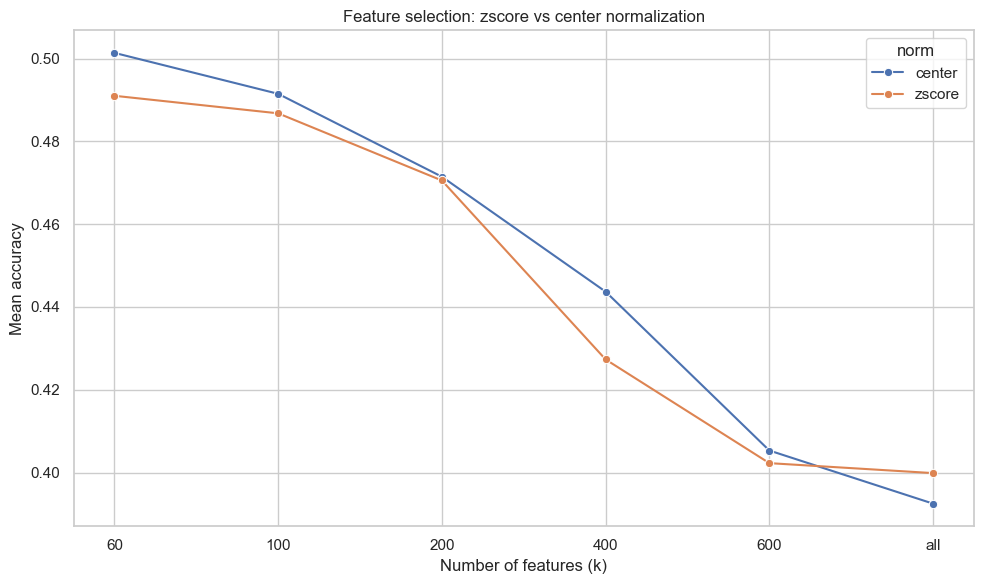

In [79]:
print("=== STEP A: Feature selection screen (zscore vs center) ===\n")

BASE_IMPUTER = SimpleImputer(strategy="mean")
BASE_PENALTY = "l1"
BASE_C       = 1
K_CANDIDATES = ["all", 60,100, 200, 400, 600]

norm_methods = ["zscore", "center"]
results_norm = []

for norm in norm_methods:
    print(f"\nTesting normalization: {norm}")
    for k in K_CANDIDATES:
        print(f"Setting: k={k}, norm={norm}, imputer=mean, penalty={BASE_PENALTY}, C={BASE_C}")
        mean_acc, std_acc, _ = evaluate_setting(
            k_features=k,
            imputer=BASE_IMPUTER,
            penalty=BASE_PENALTY,
            C=BASE_C,
            norm=norm,
            verbose_folds=False
        )
        results_norm.append({
            "norm": norm,
            "k": k,
            "mean_acc": mean_acc,
            "std_acc": std_acc
        })

results_norm_df = pd.DataFrame(results_norm).sort_values("mean_acc", ascending=False)
print("\nSTEP A summary (zscore vs center):")
print(results_norm_df.to_string(index=False))


# plot graphically
plt.figure(figsize=(10, 6))
# Convert k to string for categorical plotting
results_norm_df_plot = results_norm_df.copy()
results_norm_df_plot["k"] = results_norm_df_plot["k"].astype(str)
sns.lineplot(
    data=results_norm_df_plot,
    x="k",
    y="mean_acc",
    hue="norm",
    marker="o"
)
plt.xlabel("Number of features (k)")
plt.ylabel("Mean accuracy")
plt.title("Feature selection: zscore vs center normalization")
plt.tight_layout()
plt.show()


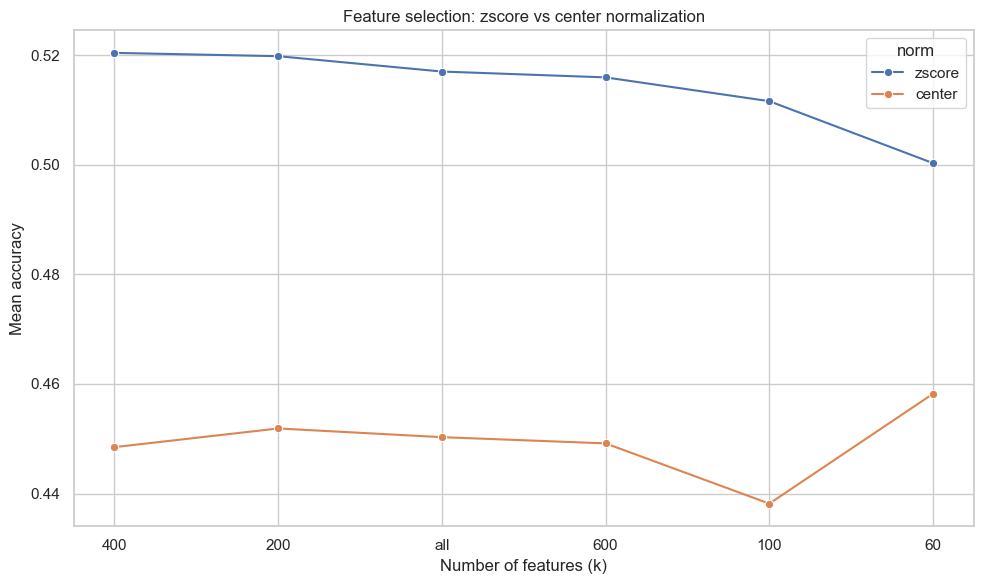

In [75]:
print("=== STEP A: Feature selection screen (zscore vs center) ===\n")

BASE_IMPUTER = SimpleImputer(strategy="mean")
BASE_PENALTY = "l1"
BASE_C       = 0.03
K_CANDIDATES = ["all", 60,100, 200, 400, 600]

norm_methods = ["zscore", "center"]
results_norm = []

for norm in norm_methods:
    print(f"\nTesting normalization: {norm}")
    for k in K_CANDIDATES:
        print(f"Setting: k={k}, norm={norm}, imputer=mean, penalty={BASE_PENALTY}, C={BASE_C}")
        mean_acc, std_acc, _ = evaluate_setting(
            k_features=k,
            imputer=BASE_IMPUTER,
            penalty=BASE_PENALTY,
            C=BASE_C,
            norm=norm,
            verbose_folds=False
        )
        results_norm.append({
            "norm": norm,
            "k": k,
            "mean_acc": mean_acc,
            "std_acc": std_acc
        })

results_norm_df = pd.DataFrame(results_norm).sort_values("mean_acc", ascending=False)
print("\nSTEP A summary (zscore vs center):")
print(results_norm_df.to_string(index=False))


# plot graphically
plt.figure(figsize=(10, 6))
# Convert k to string for categorical plotting
results_norm_df_plot = results_norm_df.copy()
results_norm_df_plot["k"] = results_norm_df_plot["k"].astype(str)
sns.lineplot(
    data=results_norm_df_plot,
    x="k",
    y="mean_acc",
    hue="norm",
    marker="o"
)
plt.xlabel("Number of features (k)")
plt.ylabel("Mean accuracy")
plt.title("Feature selection: zscore vs center normalization")
plt.tight_layout()
plt.show()


#### 3.2.1 Commentary and motivation for the next step

The two baseline sweeps already show that ANOVA feature selection helps: using all features gives clearly lower LOSO accuracy than keeping only a few dozen, and both normalizations tend to work best around k ≈ 60–100. At the same time, changing C from 1 to 0.03 noticeably reshapes the curves and even shifts the relative ranking of z‑score and centering, which means that k and C are not independent of the normalization.

We therefore decided to run a small “confirmatory” grid over (normalization, k, C) rather than fixing C by hand. The idea is not to tune every possible combination, but to focus on a few reasonable values around the elbows observed in the sweeps: for each normalization we test a small set of k in the range that looked good and a couple of nearby C values. This mini‑search should give a more stable choice of (normalization, k, C) to carry forward into the imputer comparison and the final regularization refinement.


### 3.2.2 Small grid over normalization, k and C

In this second step we turn the observations from the baseline sweeps into a small, more systematic grid search. Instead of fixing C in advance, we jointly vary the session normalization (per‑session z‑score or centering), a few candidate values of k around the elbow region (for example 60–100–200), and a couple of nearby C values. For each combination we run the full LOSO evaluation with the same pipeline as before (mean imputer, l1 penalty) and record the mean and standard deviation of accuracy across sessions.


In [ ]:

print("=== Confirmatory small search for (norm, k, C) ===\n")

BASE_IMPUTER = SimpleImputer(strategy="mean")   # keep fixed here
BASE_PENALTY = "l1"

# Small, norm-specific candidate sets (log-ish k, narrow C bands)
SEARCH = {
    "zscore": {
        "k_list": [100, 200, 300, 400, 600, "all"],
        "C_list": [0.01, 0.02, 0.03, 0.05],
    },
    "center": {
        "k_list": [40, 60, 80, 100, 200, "all"],
        "C_list": [0.1, 0.3, 1.0],
    },
}

rows = []
best = (-1.0, None)
total = sum(len(v["k_list"]) * len(v["C_list"]) for v in SEARCH.values())
done = 0

for norm_mode, cfg in SEARCH.items():
    print(f"\n--- norm={norm_mode} ---")
    for C in cfg["C_list"]:
        for k in cfg["k_list"]:
            done += 1
            print(f"[{done:02d}/{total}] norm={norm_mode:6s} | C={C:<4} | k={str(k):>4s}", flush=True)

            mean_acc, std_acc, _ = evaluate_setting(
                k_features=k,
                imputer=BASE_IMPUTER,
                penalty=BASE_PENALTY,
                C=C,
                norm=norm_mode,          
                verbose_folds=False     
            )

            row = dict(norm=norm_mode, C=float(C), k=k,
                       mean_acc=mean_acc, std_acc=std_acc)
            rows.append(row)

            if mean_acc > best[0]:
                best = (mean_acc, row)
                print(f"  -> best so far: {best[0]:.4f} with {best[1]}")

results = pd.DataFrame(rows).sort_values("mean_acc", ascending=False)

print("\n all results:")
display(results)

print("\nBest per norm:")
display(results.groupby("norm").head(1))

BEST = results.iloc[0].to_dict()
print("\nOVERALL WINNER:", BEST)

# plot the results
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=results.assign(k=results['k'].astype(str)),
    x='k',
    y='mean_acc',
    hue='norm',
    marker='o'
)


=== Confirmatory small search for (norm, k, C) ===


--- norm=zscore ---
[01/42] norm=zscore | C=0.01 | k= 100


  -> best so far: 0.4993 with {'norm': 'zscore', 'C': 0.01, 'k': 100, 'mean_acc': 0.4992916252476701, 'std_acc': 0.049227312766237666}
[02/42] norm=zscore | C=0.01 | k= 200
  -> best so far: 0.4995 with {'norm': 'zscore', 'C': 0.01, 'k': 200, 'mean_acc': 0.49950084819940976, 'std_acc': 0.054882443228696225}
[03/42] norm=zscore | C=0.01 | k= 300
[04/42] norm=zscore | C=0.01 | k= 400
  -> best so far: 0.5003 with {'norm': 'zscore', 'C': 0.01, 'k': 400, 'mean_acc': 0.5003083585183078, 'std_acc': 0.052654570160084936}
[05/42] norm=zscore | C=0.01 | k= 600
[06/42] norm=zscore | C=0.01 | k= all
[07/42] norm=zscore | C=0.02 | k= 100
  -> best so far: 0.5125 with {'norm': 'zscore', 'C': 0.02, 'k': 100, 'mean_acc': 0.5124704737763506, 'std_acc': 0.05150379746458577}
[08/42] norm=zscore | C=0.02 | k= 200
  -> best so far: 0.5189 with {'norm': 'zscore', 'C': 0.02, 'k': 200, 'mean_acc': 0.5188961040457902, 'std_acc': 0.049422655997567747}
[09/42] norm=zscore | C=0.02 | k= 300
[10/42] norm=zscore |

,norm,C,k,mean_acc,std_acc
15,zscore,0.03,400,0.520205,0.049093
13,zscore,0.03,200,0.519797,0.050486
14,zscore,0.03,300,0.519178,0.053831
7,zscore,0.02,200,0.518896,0.049423
19,zscore,0.05,200,0.517650,0.049411
17,zscore,0.03,all,0.517163,0.052930
16,zscore,0.03,600,0.515929,0.054776
8,zscore,0.02,300,0.515513,0.045406
6,zscore,0.02,100,0.512470,0.051504
18,zscore,0.05,100,0.512297,0.048939



Best per norm:


,norm,C,k,mean_acc,std_acc
15,zscore,0.03,400,0.520205,0.049093
31,center,0.30,60,0.503732,0.046864



OVERALL WINNER: {'norm': 'zscore', 'C': 0.03, 'k': 400, 'mean_acc': 0.5202051083702104, 'std_acc': 0.049092859846168235}


<Axes: xlabel='k', ylabel='mean_acc'>

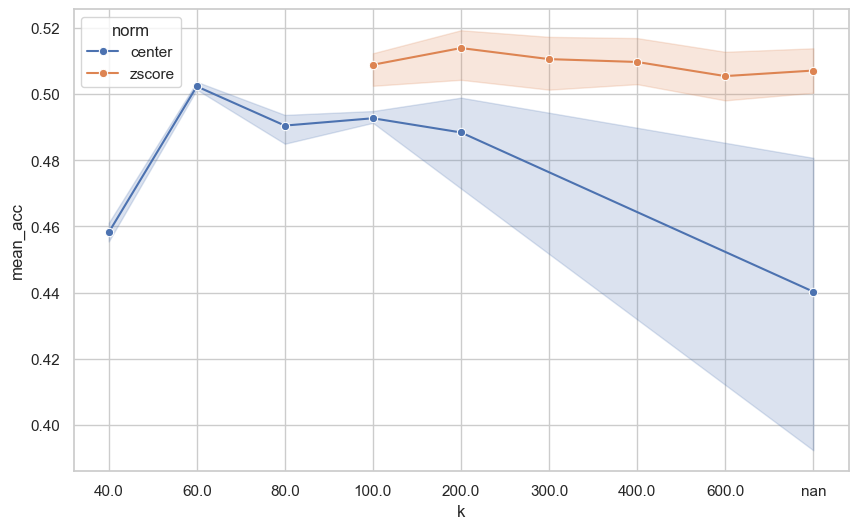

In [91]:
results_sorted = results.copy()
results_sorted["k"] = pd.to_numeric(results_sorted["k"], errors="coerce")
results_sorted = results_sorted.sort_values("k")

plt.figure(figsize=(10, 6))
sns.lineplot(
    data=results_sorted.assign(k=results_sorted['k'].astype(str)),
    x='k',
    y='mean_acc',
    hue='norm',
    marker='o'
)


#### 3.2.2 Commentary

The small grid over $(\text{norm}, k, C)$ reveals a consistent advantage of per-session z-scoring compared to simple centering across all explored feature counts. For both normalization schemes, using all features performs worse than using a subset, and accuracy improves quickly when moving from very low $k$ (around 40) to intermediate values, but only z-score manages to keep mean LOSO accuracy relatively flat (around 0.51–0.52) when increasing $k$ from 100 up to 600, or even when keeping all features. In contrast, the center-only pipeline peaks at small $k$ (around 60–100) and then drops quickly as $k$ increases, with a wide spread in performance across sessions, which suggests that adding more features mainly injects noise when scales are not standardized.

Per-session z-scoring not only reaches the highest mean LOSO accuracies in this grid, it also exhibits narrower confidence bands, indicating more stable performance across sessions for a broad range of $k$ values. One configuration that looks particularly reasonable is

$$
\text{norm}=\text{zscore},\quad C=0.03,\quad k=400,
$$

which attains a mean LOSO accuracy of about 0.52 with a standard deviation across sessions of roughly 0.05. This combination strikes a balance between strong average performance, robustness to the exact number of selected features, and relatively low variability, so the triple $(\text{zscore}, k=400, C=0.03)$ is adopted as a working default for the following experiments, where the focus will shift to other parts of the pipeline (in particular the imputer choice and refinements of the regularization), while still allowing for minor adjustments of $k$ or $C$ around this baseline if later results motivate them.

## 3.3 Imputer screen (fixed normalization, k and C)


### 3.3.1


Here we fix the normalization, feature count \(k\) and regularization strength \(C\) to the best‑looking combination from previous step, and swap out only the imputer (mean, constant 0, KNN, possibly iterative). The goal is to see whether more flexible imputers actually improve LOSO accuracy enough to justify their extra cost.

=== STEP B: Imputer screen (fixed norm, fixed k, fixed C) ===

Setting: norm=zscore | k=400 | imputer=zero | penalty=l1 | C=0.03
  Fold 01 | left-out session=PG082_20221113 | acc=0.5287
  Fold 02 | left-out session=PG082_20221114 | acc=0.5700
  Fold 03 | left-out session=PG083_20221125 | acc=0.5503
  Fold 04 | left-out session=PG083_20221129 | acc=0.5099
  Fold 05 | left-out session=PG084_20221206 | acc=0.5039
  Fold 06 | left-out session=PG084_20221207 | acc=0.5718
  Fold 07 | left-out session=PG085_20221213 | acc=0.4071
  Fold 08 | left-out session=PG085_20221214 | acc=0.5198
  ==> MEAN ± STD: 0.5202 ± 0.0491

Setting: norm=zscore | k=400 | imputer=mean | penalty=l1 | C=0.03
  Fold 01 | left-out session=PG082_20221113 | acc=0.5287
  Fold 02 | left-out session=PG082_20221114 | acc=0.5700
  Fold 03 | left-out session=PG083_20221125 | acc=0.5503
  Fold 04 | left-out session=PG083_20221129 | acc=0.5099
  Fold 05 | left-out session=PG084_20221206 | acc=0.5039
  Fold 06 | left-out session=

,imputer,mean_acc,std_acc
0,zero,0.520205,0.049093
1,mean,0.520205,0.049093
4,knn10,0.516549,0.043520
3,knn5,0.513336,0.049893
2,knn2,0.508557,0.046857



Chosen BEST_IMPUTER = zero
Chosen setting: {'norm': 'zscore', 'k': 400, 'C': 0.03, 'penalty': 'l1', 'imputer': 'zero'}


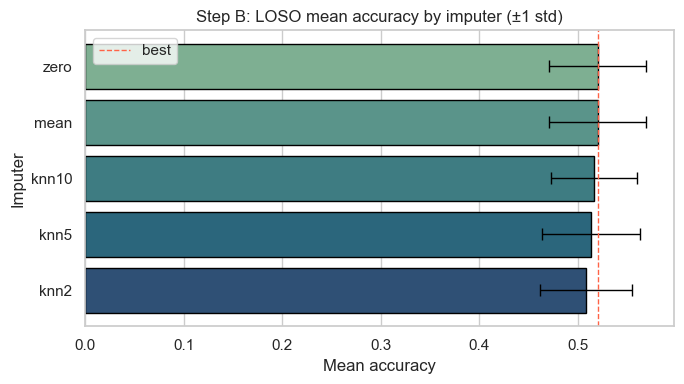

In [ ]:
print("=== STEP B: Imputer screen (fixed norm, fixed k, fixed C) ===\n")

# From Step A/confirmatory search:
BEST_NORM    = "zscore"
BEST_K       = 400
BASE_PENALTY = "l1"
BASE_C       = 0.03

IMPUTERS = {
    "zero": SimpleImputer(strategy="constant", fill_value=0),
    "mean": SimpleImputer(strategy="mean"),
    "knn2": KNNImputer(n_neighbors=2),
    "knn5": KNNImputer(n_neighbors=5),
    "knn10": KNNImputer(n_neighbors=10),
    # "iter": IterativeImputer(random_state=SEED, max_iter=10)  # optional, slower
}

rows_B = []
for name, imp in IMPUTERS.items():
    print(f"Setting: norm={BEST_NORM} | k={BEST_K} | imputer={name} | penalty={BASE_PENALTY} | C={BASE_C}")
    
    mean_acc, std_acc, _ = evaluate_setting(
        k_features=BEST_K,
        imputer=imp,
        penalty=BASE_PENALTY,
        C=BASE_C,
        norm=BEST_NORM,          # <-- IMPORTANT: fix norm here
        verbose_folds=True
    )
    rows_B.append({"imputer": name, "mean_acc": mean_acc, "std_acc": std_acc})

results_B = pd.DataFrame(rows_B).sort_values("mean_acc", ascending=False)

print("\nSTEP B summary (sorted):")
display(results_B)

BEST_IMPUTER_NAME = results_B.iloc[0]["imputer"]
print("\nChosen BEST_IMPUTER =", BEST_IMPUTER_NAME)
print("Chosen setting:", {"norm": BEST_NORM, "k": BEST_K, "C": BASE_C, "penalty": BASE_PENALTY, "imputer": BEST_IMPUTER_NAME})


# --- Smart plots for Step B ---
plot_df = results_B.copy()
plt.figure(figsize=(7, 4))
sns.barplot(
    data=plot_df,
    x="mean_acc",
    y="imputer",
    orient="h",
    palette="crest",
    edgecolor="black",
)
# error bars
plt.errorbar(
    x=plot_df["mean_acc"],
    y=np.arange(len(plot_df)),
    xerr=plot_df["std_acc"],
    fmt="none",
    ecolor="black",
    capsize=4,
    linewidth=1,
)
# highlight best
best_row = plot_df.iloc[0]
plt.axvline(best_row["mean_acc"], color="tomato", linestyle="--", linewidth=1, label="best")
plt.title("Step B: LOSO mean accuracy by imputer (±1 std)")
plt.xlabel("Mean accuracy")
plt.ylabel("Imputer")
plt.legend()
plt.tight_layout()
plt.show()

#### 3.3.1 commentary

With per‑session z‑score, \(k = 400\) and \(C = 0.03\) fixed, the imputer comparison shows that the simple **zero** and **mean** imputers are tied for best, with a mean LOSO accuracy of \(0.5202 ±  0.0491\). All kNN variants perform slightly worse (kNN10 at \(0.5165\), kNN5 at \(0.5133\), kNN2 at \(0.5086\)), with overlapping but not clearly superior error bars.

This pattern is consistent with the fact that, after per‑session z‑scoring, most feature means are already very close to zero, so mean imputation and constant‑zero imputation effectively produce the same filled matrix and therefore identical LOSO performance. The small drop for kNN imputers suggests that, in this LOSO setup, reconstructing missing entries from neighbours does not uncover additional discriminative structure and may even smooth away useful variability, while incurring extra computational cost.

The apparent degeneracy between mean and zero imputation is therefore not a bug in the code but a direct consequence of applying z‑scoring before imputation: once each feature is centered within a session, the training‑fold mean is approximately 0, so `SimpleImputer(strategy="mean")` and `SimpleImputer(fill_value=0)` both end up inserting (almost) the same values and the classifier sees essentially identical inputs. The next two cells make this explicit by (i) checking on one LOSO fold that the post‑z‑score feature means are numerically near zero and that the mean‑ and zero‑imputed matrices coincide up to tiny numerical noise, and (ii) repeating the experiment with the order swapped (impute -> z‑score), where the two imputers diverge again in LOSO accuracy, confirming that their equivalence in the main pipeline is driven by the normalization step rather than a coding error.

### 3.3.2 Diagnostic: why mean ≈ zero imputation?

To better understand why mean and zero imputation give identical LOSO accuracies, this diagnostic zooms in on a single LOSO fold and inspects the data **after** per‑session z‑scoring. It quantifies how close each feature’s training‑fold mean is to zero and compares the resulting design matrices for `SimpleImputer(strategy="mean")` and `SimpleImputer(fill_value=0)`, showing that they differ only by tiny numerical noise. A second check then swaps the order of operations (impute → z‑score) and confirms that, without prior centering, mean and zero imputation yield visibly different inputs and LOSO accuracies, so the equivalence in Step B is a consequence of the normalization scheme rather than an implementation bug.


In [ ]:

print("=== DIAGNOSTIC: why mean-impute == zero-impute after per-session z-score? ===\n")

stable_feature_cols = list(stable_feature_cols)  # just in case it's an Index

# take the first LOSO split
tr_idx, te_idx = next(logo.split(df[stable_feature_cols], df[TARGET_COL], groups=df[GROUP_COL]))

train_block = df.iloc[tr_idx].copy()
test_block  = df.iloc[te_idx].copy()

def zscore_block_per_session(block):
    out = block.copy()
    out[stable_feature_cols] = out.groupby(GROUP_COL)[stable_feature_cols].transform(
        lambda x: (x - x.mean()) / (x.std() + 1e-8)
    )
    return out

train_z = zscore_block_per_session(train_block)
test_z  = zscore_block_per_session(test_block)

X_tr = train_z[stable_feature_cols].to_numpy(dtype=np.float32)
X_te = test_z[stable_feature_cols].to_numpy(dtype=np.float32)

# Some columns can be all-NaN inside this training fold (features only present in a few sessions)
keep = ~np.all(np.isnan(X_tr), axis=0)
X_tr = X_tr[:, keep]
X_te = X_te[:, keep]
kept_cols = np.array(stable_feature_cols)[keep]

col_means = np.nanmean(X_tr, axis=0)

print(f"Fold left-out session: {test_block[GROUP_COL].iloc[0]}")
print(f"Kept columns (not all-NaN in train fold): {len(kept_cols)} / {len(stable_feature_cols)}")
print(f"Total NaNs in X_tr: {np.isnan(X_tr).sum()}")

print("\nAfter per-session z-score, training-fold column means are ~0:")
print(f"  median |mean| = {np.nanmedian(np.abs(col_means)):.3e}")
print(f"  99%    |mean| = {np.nanpercentile(np.abs(col_means), 99):.3e}")
print(f"  max    |mean| = {np.nanmax(np.abs(col_means)):.3e}")

imp_zero = SimpleImputer(strategy="constant", fill_value=0)
imp_mean = SimpleImputer(strategy="mean")

X0 = imp_zero.fit_transform(X_tr)
XM = imp_mean.fit_transform(X_tr)

diff = np.abs(X0 - XM)
print("\nComparison between zero-impute and mean-impute (on z-scored data):")
print(f"  max |X0 - XM| = {np.max(diff):.3e}")
print(f"  % entries differing > 1e-8 = {100*np.mean(diff > 1e-8):.4f}%")

print("\nInterpretation: per-session z-score centers features around 0, so mean-impute fills ~0,")
print("making it (almost) identical to zero-impute → very similar inputs → same LR accuracy.\n")
print(f"Typical |X| scale after z-score (median abs): {np.nanmedian(np.abs(X_tr)):.3f}")



=== DIAGNOSTIC: why mean-impute == zero-impute after per-session z-score? ===

Fold left-out session: PG082_20221113
Kept columns (not all-NaN in train fold): 1290 / 1290
Total NaNs in X_tr: 831300

After per-session z-score, training-fold column means are ~0:
  median |mean| = 4.248e-09
  99%    |mean| = 1.990e-08
  max    |mean| = 2.936e-08

Comparison between zero-impute and mean-impute (on z-scored data):
  max |X0 - XM| = 2.936e-08
  % entries differing > 1e-8 = 4.8465%

Interpretation: per-session z-score centers features around 0, so mean-impute fills ~0,
making it (almost) identical to zero-impute → very similar inputs → same LR accuracy.

Typical |X| scale after z-score (median abs): 0.555


In [ ]:

print("=== TEST: impute first, then per-session z-score (LOSO) ===\n")

# Use the SAME columns as Step B (pick ONE that exists in your notebook)
COLS = stable_feature_cols  # or: stable_feature_cols

def evaluate_setting_impute_then_zscore(k_features, imputer, penalty, C, verbose_folds=True):
    accs = []
    fold_id = 0

    for tr_idx, te_idx in logo.split(df[COLS], df[TARGET_COL], groups=df[GROUP_COL]):
        fold_id += 1
        train_block = df.iloc[tr_idx].copy()
        test_block  = df.iloc[te_idx].copy()

        y_tr = train_block[TARGET_COL].to_numpy()
        y_te = test_block[TARGET_COL].to_numpy()

        X_tr_raw = train_block[COLS].to_numpy(dtype=np.float32)
        X_te_raw = test_block[COLS].to_numpy(dtype=np.float32)

        # drop columns that are all-NaN inside this TRAIN fold
        keep = ~np.all(np.isnan(X_tr_raw), axis=0)
        cols = np.array(COLS)[keep]
        X_tr_raw = X_tr_raw[:, keep]
        X_te_raw = X_te_raw[:, keep]

        # 1) impute (fit on train, transform test)
        X_tr_imp = imputer.fit_transform(X_tr_raw)
        X_te_imp = imputer.transform(X_te_raw)

        # 2) per-session z-score AFTER imputation
        tr_df = pd.DataFrame(X_tr_imp, columns=cols, index=train_block.index)
        te_df = pd.DataFrame(X_te_imp, columns=cols, index=test_block.index)

        tr_df[GROUP_COL] = train_block[GROUP_COL].values
        te_df[GROUP_COL] = test_block[GROUP_COL].values

        tr_df[cols] = tr_df.groupby(GROUP_COL)[cols].transform(
            lambda x: (x - x.mean()) / (x.std() + 1e-8)
        )
        te_df[cols] = te_df.groupby(GROUP_COL)[cols].transform(
            lambda x: (x - x.mean()) / (x.std() + 1e-8)
        )

        X_tr = tr_df[cols].to_numpy(dtype=np.float32)
        X_te = te_df[cols].to_numpy(dtype=np.float32)

        # 3) ANOVA feature selection inside the fold (optional)
        if k_features != "all":
            k = min(int(k_features), X_tr.shape[1])
            selector = SelectKBest(score_func=f_classif, k=k)
            X_tr = selector.fit_transform(X_tr, y_tr)
            X_te = selector.transform(X_te)

        # 4) logistic regression
        model = LogisticRegression(
            penalty=penalty,
            C=C,
            solver="liblinear",
            max_iter=2000
        )
        model.fit(X_tr, y_tr)
        preds = model.predict(X_te)
        acc = accuracy_score(y_te, preds)
        accs.append(acc)

        if verbose_folds:
            left_out = test_block[GROUP_COL].iloc[0]
            print(f"  Fold {fold_id:02d} | left-out session={left_out} | acc={acc:.4f}")

    return float(np.mean(accs)), float(np.std(accs)), accs


IMPUTERS_TEST = {
    "zero": SimpleImputer(strategy="constant", fill_value=0),
    "mean": SimpleImputer(strategy="mean"),
}

for name, imp in IMPUTERS_TEST.items():
    print(f"\nSetting (impute->zscore): k={BEST_K}, imputer={name}, penalty={BASE_PENALTY}, C={BASE_C}")
    mean_acc, std_acc, _ = evaluate_setting_impute_then_zscore(
        k_features=BEST_K,
        imputer=imp,
        penalty=BASE_PENALTY,
        C=BASE_C,
        verbose_folds=True
    )
    print(f"  ==> MEAN ± STD: {mean_acc:.4f} ± {std_acc:.4f}")


=== TEST: impute first, then per-session z-score (LOSO) ===


Setting (impute->zscore): k=400, imputer=zero, penalty=l1, C=0.01
  Fold 01 | left-out session=PG082_20221113 | acc=0.5015
  Fold 02 | left-out session=PG082_20221114 | acc=0.5407
  Fold 03 | left-out session=PG083_20221125 | acc=0.5346
  Fold 04 | left-out session=PG083_20221129 | acc=0.4724
  Fold 05 | left-out session=PG084_20221206 | acc=0.5157
  Fold 06 | left-out session=PG084_20221207 | acc=0.5426
  Fold 07 | left-out session=PG085_20221213 | acc=0.3734
  Fold 08 | left-out session=PG085_20221214 | acc=0.5216
  ==> MEAN ± STD: 0.5003 ± 0.0527

Setting (impute->zscore): k=400, imputer=mean, penalty=l1, C=0.01
  Fold 01 | left-out session=PG082_20221113 | acc=0.4577
  Fold 02 | left-out session=PG082_20221114 | acc=0.5179
  Fold 03 | left-out session=PG083_20221125 | acc=0.5346
  Fold 04 | left-out session=PG083_20221129 | acc=0.4570
  Fold 05 | left-out session=PG084_20221206 | acc=0.4921
  Fold 06 | left-out session=P


#### 3.3.2 Choice for the rest of the pipeline

Given these observations, the main LOSO pipeline keeps the original order **z‑score → impute** and adopts **zero imputation** as the default, since it is the simplest method and performs on par with mean imputation while slightly outperforming the tested kNN variants. All subsequent linear‑model experiments (regularization refinements in Step C and later comparisons) therefore use per‑session z‑scoring followed by zero imputation, with \(k = 400\) and \(C = 0.03\) fixed from previous step.


 ## 3.4 Regularization screen

 


### 3.4.1 Regularization screening

At this stage, the pipeline is fixed to the best configuration identified in the previuous steps, namely per-session z-score normalization, ANOVA feature selection with k = 400, and a zero-imputation strategy. Only the regularization of the logistic regression model is varied.

We perform a coarse grid search over both L1 and L2 penalties, together with a wide range of regularization strengths C, spanning from very small values (around 0.001) up to large values (around 10). The goal of this step is to assess how sensitive the classification performance is to both the type and the strength of regularization, while keeping all other components of the pipeline unchanged. Importantly, the exact same leave-one-session-out cross-validation protocol is used as in the previous steps, so that any performance differences can be attributed solely to the regularization choice.

In [ ]:
print("=== STEP C: Regularization screen ===\n")

if BEST_IMPUTER_NAME == "zero":
    BEST_IMPUTER = SimpleImputer(strategy="constant", fill_value=0)
elif BEST_IMPUTER_NAME == "mean":
    BEST_IMPUTER = SimpleImputer(strategy="mean")
else:
    BEST_IMPUTER = KNNImputer(n_neighbors=2)

PENALTIES = ["l1", "l2"]
C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]


rows_C = []
best = (-1, None)

for pen in PENALTIES:
    for C in C_GRID:
        print(f"Setting: norm={BEST_NORM} | k={BEST_K} | imputer={BEST_IMPUTER_NAME} | penalty={pen} | C={C}")
        mean_acc, std_acc, _ = evaluate_setting(
            k_features=BEST_K,
            imputer=BEST_IMPUTER,
            penalty=pen,
            C=C,
            verbose_folds=False  # keep it readable; set True if you want fold prints for every run
        )
        rows_C.append({"k": BEST_K, "imputer": BEST_IMPUTER_NAME, "penalty": pen, "C": C,
                       "mean_acc": mean_acc, "std_acc": std_acc})

        if mean_acc > best[0]:
            best = (mean_acc, rows_C[-1])
            print(f"  -> best so far: {best[0]:.4f} with {best[1]}\n")

results_C = pd.DataFrame(rows_C).sort_values("mean_acc", ascending=False)
print("Top settings:")
print(results_C.head(10).to_string(index=False))

BEST_SETTING = results_C.iloc[0].to_dict()
print("\nBEST SETTING:")
print(BEST_SETTING)


=== STEP C: Regularization screen ===

Setting: norm=zscore | k=400 | imputer=zero | penalty=l1 | C=0.001
  -> best so far: 0.2000 with {'k': 400, 'imputer': 'zero', 'penalty': 'l1', 'C': 0.001, 'mean_acc': 0.19997126187578568, 'std_acc': 0.0020139610674188295}

Setting: norm=zscore | k=400 | imputer=zero | penalty=l1 | C=0.003
  -> best so far: 0.4093 with {'k': 400, 'imputer': 'zero', 'penalty': 'l1', 'C': 0.003, 'mean_acc': 0.40930351900141315, 'std_acc': 0.0594663884143082}

Setting: norm=zscore | k=400 | imputer=zero | penalty=l1 | C=0.01
  -> best so far: 0.5003 with {'k': 400, 'imputer': 'zero', 'penalty': 'l1', 'C': 0.01, 'mean_acc': 0.5003083585183078, 'std_acc': 0.052654570160084936}

Setting: norm=zscore | k=400 | imputer=zero | penalty=l1 | C=0.03
  -> best so far: 0.5202 with {'k': 400, 'imputer': 'zero', 'penalty': 'l1', 'C': 0.03, 'mean_acc': 0.5202051083702104, 'std_acc': 0.049092859846168235}

Setting: norm=zscore | k=400 | imputer=zero | penalty=l1 | C=0.1
Setting: no

#### 3.4.1 Commentary

The coarse scan shows that both penalties can reach competitive accuracies, but at very different regularization scales. The L1 penalty performs best for moderate regularization strengths, with a clear peak around C = 0.03 and a mean leave-one-session-out accuracy of about 0.52. In contrast, the L2 penalty reaches a slightly higher mean accuracy (around 0.525) already for very strong regularization, near C = 0.001.

For larger values of C, performance degrades for both penalties, indicating that overly weak regularization leads to poorer generalization across sessions. Based on these observations, the subsequent refinement focuses on narrow regions around the most promising values identified in this coarse scan, namely around C = 0.03 for L1 and around C = 0.001 for L2.

### 3.4.2 Local refinement per penalty

After the coarse grid search, the relationship between performance and the regularization strength C clearly differed between the two penalties. The L1 penalty showed a well-defined peak around C = 0.03, while the L2 penalty performed best at much smaller values of C, close to 0.001. 

Rather than expanding the grid unnecessarily, the next step therefore refines each penalty locally around its apparent optimum. During this refinement, all other components of the pipeline are kept fixed at the previously selected configuration, namely per-session z-score normalization, k = 400 ANOVA-selected features, and the zero imputer.

=== STEP C refine — L1 around 0.03 ===

[L1 1/11] C=0.025
[L1 2/11] C=0.026
[L1 3/11] C=0.027
[L1 4/11] C=0.028
[L1 5/11] C=0.029
[L1 6/11] C=0.03
[L1 7/11] C=0.031
[L1 8/11] C=0.032
[L1 9/11] C=0.033
[L1 10/11] C=0.034
[L1 11/11] C=0.035

L1 refine results:


,penalty,C,mean_acc,std_acc
5,l1,0.030,0.520205,0.049093
6,l1,0.031,0.520066,0.049522
8,l1,0.033,0.519574,0.050891
7,l1,0.032,0.519390,0.050699
9,l1,0.034,0.519272,0.052110
3,l1,0.028,0.519225,0.049014
4,l1,0.029,0.519201,0.047855
1,l1,0.026,0.518554,0.049213
2,l1,0.027,0.518413,0.049838
10,l1,0.035,0.517858,0.052130


Best L1: (0.5202051083702104, {'penalty': 'l1', 'C': 0.03, 'mean_acc': 0.5202051083702104, 'std_acc': 0.049092859846168235})


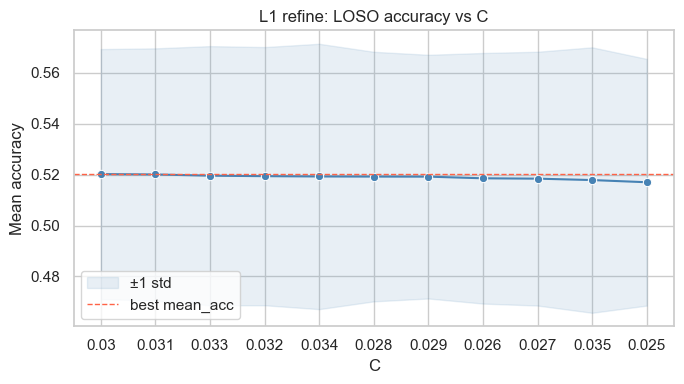

=== STEP C refine — L2 around 0.001 ===

[L2 1/7] C=0.0005
[L2 2/7] C=0.0007
[L2 3/7] C=0.001
[L2 4/7] C=0.0015
[L2 5/7] C=0.002
[L2 6/7] C=0.003
[L2 7/7] C=0.005

L2 refine results:


,penalty,C,mean_acc,std_acc
1,l2,0.0007,0.527784,0.057546
0,l2,0.0005,0.527012,0.057640
2,l2,0.0010,0.525175,0.054940
3,l2,0.0015,0.519172,0.053899
4,l2,0.0020,0.518091,0.054620
5,l2,0.0030,0.515832,0.053694
6,l2,0.0050,0.506156,0.053711


Best L2: (0.5277837001269131, {'penalty': 'l2', 'C': 0.0007, 'mean_acc': 0.5277837001269131, 'std_acc': 0.05754631325269624})


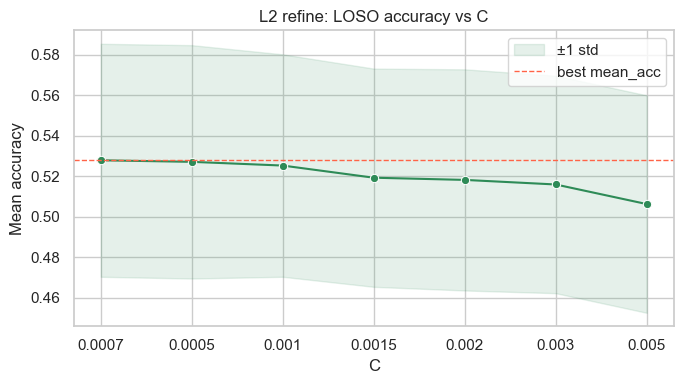

In [ ]:
# Refine C for L1 (local grid around 0.03)
print("=== STEP C refine — L1 around 0.03 ===\n")

# Local grid focused on the L1 peak observed (0.03)
C_GRID_L1 = [0.025, 0.026, 0.027, 0.028, 0.029, 0.03, 0.031, 0.032, 0.033, 0.034, 0.035]

rows_L1 = []
best_L1 = (-1, None)

for i, C in enumerate(C_GRID_L1, 1):
    print(f"[L1 {i}/{len(C_GRID_L1)}] C={C}")
    mean_acc, std_acc, _ = evaluate_setting(
        k_features=BEST_K,
        imputer=BEST_IMPUTER,
        penalty="l1",
        C=C,
        norm=BEST_NORM,
        verbose_folds=False,
    )
    rows_L1.append({"penalty": "l1", "C": C, "mean_acc": mean_acc, "std_acc": std_acc})
    if mean_acc > best_L1[0]:
        best_L1 = (mean_acc, rows_L1[-1])

res_L1 = pd.DataFrame(rows_L1).sort_values("mean_acc", ascending=False)
print("\nL1 refine results:")
display(res_L1)
print("Best L1:", best_L1)

plt.figure(figsize=(7, 4))
sns.lineplot(data=res_L1.assign(C_str=res_L1["C"].astype(str)),
             x="C_str", y="mean_acc", marker="o", color="steelblue")
plt.fill_between(res_L1["C"].astype(str),
                 res_L1["mean_acc"] - res_L1["std_acc"],
                 res_L1["mean_acc"] + res_L1["std_acc"],
                 color="steelblue", alpha=0.12, label="±1 std")
plt.axhline(best_L1[0], color="tomato", linestyle="--", linewidth=1, label="best mean_acc")
plt.title("L1 refine: LOSO accuracy vs C")
plt.xlabel("C")
plt.ylabel("Mean accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Refine C for L2 (local grid around 0.001 winner)
print("=== STEP C refine — L2 around 0.001 ===\n")

# Narrow grid centered near the L2 best (0.001) from the coarse scan
C_GRID_L2 = [0.0005, 0.0007, 0.001, 0.0015, 0.002, 0.003, 0.005]

rows_L2 = []
best_L2 = (-1, None)

for i, C in enumerate(C_GRID_L2, 1):
    print(f"[L2 {i}/{len(C_GRID_L2)}] C={C}")
    mean_acc, std_acc, _ = evaluate_setting(
        k_features=BEST_K,
        imputer=BEST_IMPUTER,
        penalty="l2",
        C=C,
        norm=BEST_NORM,
        verbose_folds=False,
    )
    rows_L2.append({"penalty": "l2", "C": C, "mean_acc": mean_acc, "std_acc": std_acc})
    if mean_acc > best_L2[0]:
        best_L2 = (mean_acc, rows_L2[-1])

res_L2 = pd.DataFrame(rows_L2).sort_values("mean_acc", ascending=False)
print("\nL2 refine results:")
display(res_L2)
print("Best L2:", best_L2)

plt.figure(figsize=(7, 4))
sns.lineplot(data=res_L2.assign(C_str=res_L2["C"].astype(str)),
             x="C_str", y="mean_acc", marker="o", color="seagreen")
plt.fill_between(res_L2["C"].astype(str),
                 res_L2["mean_acc"] - res_L2["std_acc"],
                 res_L2["mean_acc"] + res_L2["std_acc"],
                 color="seagreen", alpha=0.12, label="±1 std")
plt.axhline(best_L2[0], color="tomato", linestyle="--", linewidth=1, label="best mean_acc")
plt.title("L2 refine: LOSO accuracy vs C")
plt.xlabel("C")
plt.ylabel("Mean accuracy")
plt.legend()
plt.tight_layout()
plt.show()

#### 3.4.2 Commentary

After the local refinement, the L1 regularization curve turns out to be very flat in the range C between 0.025 and 0.035. Several neighbouring values yield almost identical mean LOSO accuracies around 0.52, with very similar variability across sessions. This indicates that, for L1, performance is relatively insensitive to small changes in C within this band.

In contrast, the L2 refinement shows a more clearly defined optimum at C = 0.0007, reaching a mean LOSO accuracy of about 0.528 with a standard deviation close to 0.058. This setting slightly improves upon the coarse C = 0.001 result and consistently outperforms larger C values.

Because this refined L2 configuration achieves the highest average LOSO accuracy overall while remaining reasonably stable across folds, the model using per-session z-score normalization, k = 400 selected features, the zero imputer, an L2 penalty, and C = 0.0007 is selected as the default configuration for the final submission.

## 3.5  Final model and Kaggle submission
We now refit a single one‑vs‑rest logistic regression on the full training set using the best configuration from Step C (per‑session z‑score, \(k = 400\), zero imputer, L2 with \(C = 0.0007\)). We reuse the same stable feature list and post‑imputation constant‑column mask, then z‑score each test session by its own distribution, apply the trained imputer and selector, and write the predicted labels into the Kaggle submission template.



In [ ]:
final_imputer = SimpleImputer(strategy="constant", fill_value=0)

final_penalty = "l2"
final_C = 0.0007
final_k = 400
final_norm = "zscore"
# ---- Train preprocessing on full train ----
train_full = zscore_per_session(df.copy(), stable_feature_cols)

X_train = train_full[stable_feature_cols].to_numpy(dtype=np.float32)
y_train = train_full[TARGET_COL].to_numpy()

# drop columns that are all-NaN even in full train (should be none after earlier cleaning, but safe)
keep_full = ~np.isnan(X_train).all(axis=0)
X_train = X_train[:, keep_full]
kept_feature_names = np.array(stable_feature_cols)[keep_full].tolist()

X_train_imp = final_imputer.fit_transform(X_train)

# drop constant after imputation (safe)
std_full = X_train_imp.std(axis=0)
keep_nonconst = std_full > 0
X_train_imp = X_train_imp[:, keep_nonconst]
kept_feature_names = np.array(kept_feature_names)[keep_nonconst].tolist()

# optional ANOVA selection for final model
if final_k != "all":
    k = min(int(final_k), X_train_imp.shape[1])
    selector = SelectKBest(score_func=f_classif, k=k)
    X_train_final = selector.fit_transform(X_train_imp, y_train)
else:
    selector = None
    X_train_final = X_train_imp

# ---- Fit final LR ----
base_lr = LogisticRegression(
    penalty=final_penalty,
    C=final_C,
    solver="liblinear",
    max_iter=2000,
)
final_model = OneVsRestClassifier(base_lr)
final_model.fit(X_train_final, y_train)

print("Final train matrix shape:", X_train_final.shape)

# ---- Prepare test ----
df_test = pd.read_csv(TEST_PATH)
test_ids = df_test[["session_id", "trial_number"]].copy()

# Keep only columns that exist in training feature list
# (reindex will add missing cols as NaN)
test_block = df_test.reindex(columns=["session_id", "trial_number"] + kept_feature_names)

# z-score per session on test
test_block = zscore_per_session(test_block, kept_feature_names)

X_test = test_block[kept_feature_names].to_numpy(dtype=np.float32)

# impute using train-fitted imputer
X_test_imp = final_imputer.transform(X_test)

# drop constant mask (same as train)
X_test_imp = X_test_imp[:, keep_nonconst]

# apply ANOVA selector if used
if selector is not None:
    X_test_final = selector.transform(X_test_imp)
else:
    X_test_final = X_test_imp

pred_test = final_model.predict(X_test_final)

# ---- Write submission ----
sample_sub = pd.read_csv("../data/raw/sample_submission.csv")
sample_sub[TARGET_COL] = pred_test
out_path = "../data/submission_logreg_linear_pipeline.csv"
sample_sub.to_csv(out_path, index=False)

print("Saved:", out_path)


Final train matrix shape: (4407, 400)
Saved: ../data/submission_logreg_linear_pipeline.csv


### 3.6 Conclusion

Overall, the linear multiclass logistic regression provides a strong and interpretable baseline that respects the session structure of the dataset. Using a unified LOSO pipeline with per‑session z‑score normalization, fold‑wise imputation, and ANOVA feature selection, the best configuration (z‑score, 400 features, zero imputer, L2 with \(C=0.0007\)) reaches a mean LOSO accuracy of about 0.528 with a standard deviation around 0.058, and achieves a Kaggle test accuracy of 0.59606 when retrained on the full training set. This shows that a carefully regularized linear model can already capture a substantial fraction of the behaviour‑related signal, while remaining robust to recording‑specific artefacts, and it provides a reliable reference point against which more flexible models such as XGBoost or Random Forest can be compared.

# 4. Non Linear Model 

## 4.1 XGBoost

### 4.1.1 Introduction
In this section, we introduce our non-linear classification model, based on XGBoost. XGBoost was chosen because it can model non-linear decision boundaries, handle high-dimensional feature spaces, and capture interactions between features, which are expected in our dataset. In addition, tree-based models are relatively robust to feature scaling and correlated variables, making XGBoost a strong candidate for this type of neural data.
To ensure a fair and controlled comparison, we start from the same preprocessing pipeline as for the logistic regression (normalization, imputation, feature selection, and LOSO cross-validation). In order to avoid an excessively large and expensive grid search, hyperparameters are not tuned all at once. Instead, we follow a step-by-step strategy, selecting parameters by order of importance through successive iterations, while keeping the rest of the pipeline fixed. This approach reduces computational cost and allows a clearer interpretation of the impact of each group of hyperparameters. It's worth noting that a massive grid search over all possible parameters of the model, by testing every possibility, should be "better" but it's rapidely unfeasible because of the time it would take.


### 4.1.2 LOSO-Based Optimization of the Three Most Influential XGBoost Hyperparameters
This notebook section performs a grid search for the 3 main XGBoost hyperparameters using a Leave-One-Session-Out (LOSO) cross-validation scheme to avoid leakage across recording sessions. We first load the raw training set, drop constant features, and apply a per-session z-score normalization. Labels are encoded to integers.
For each combination of `n_estimators`, `max_depth`, and `learning_rate` we run LOSO folds where we: 

1) fit a KNN imputer on the training fold only and apply it to the test fold

2) compute ANOVA F-scores on the training fold only to select the top K_FEATURES (here 400) 

3) train an XGBoost classifier and evaluate its accuracy on the held-out session. We report the mean ± std accuracy across sessions and rank all configurations to identify the best-performing hyperparameter triplets.

`n_estimators`, `max_depth`, and `learning_rate` are considered the most important hyperparameters because they directly control the capacity, complexity, and learning dynamics of the XGBoost model:

`n_estimators` controls the number of boosting trees

`max_depth` determines the complexity of individual trees

`learning_rate` regulates how strongly each new tree contributes to the ensemble

In [ ]:
# =============================
# 0. Global parameters
# =============================
K_FEATURES = 400
N_NEIGHBORS = 2

PARAM_GRID = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 5, 7, 9],
    "learning_rate": [0.03, 0.05, 0.1, 0.2],
}

# =============================
# 1. Load RAW training data
# =============================
df = pd.read_csv("../data/raw/train.csv")

# Remove constant columns
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# Feature columns
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

# Per-session normalization (z-score)
df[feature_cols] = df.groupby("session_id")[feature_cols].transform(
    lambda x: (x - x.mean()) / (x.std() + 1e-8)
)

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Label encoding
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

# =============================
# 2. LOSO grid search
# =============================
logo = LeaveOneGroupOut()
results = []

for n_estimators in PARAM_GRID["n_estimators"]:
    for max_depth in PARAM_GRID["max_depth"]:
        for learning_rate in PARAM_GRID["learning_rate"]:

            fold_accs = []

            print(
                f"\nTesting: "
                f"n_estimators={n_estimators}, "
                f"max_depth={max_depth}, "
                f"learning_rate={learning_rate}"
            )

            for train_idx, test_idx in logo.split(X, y, groups):

                X_train_raw = X[train_idx]
                X_test_raw  = X[test_idx]
                y_train = y[train_idx]
                y_test  = y[test_idx]

                # --- Imputation
                imputer = KNNImputer(n_neighbors=N_NEIGHBORS)
                X_train_imp = imputer.fit_transform(X_train_raw)
                X_test_imp  = imputer.transform(X_test_raw)

                # --- Select top-K features (TRAIN of the fold only)
                f_scores, _ = f_classif(X_train_imp, y_train)
                f_scores = np.nan_to_num(f_scores, nan=-np.inf)
                topk_idx = np.argsort(f_scores)[-K_FEATURES:]

                X_train_sel = X_train_imp[:, topk_idx]
                X_test_sel  = X_test_imp[:, topk_idx]

                # --- XGBoost model
                model = XGBClassifier(
                    n_estimators=n_estimators,
                    max_depth=max_depth,
                    learning_rate=learning_rate,
                    min_child_weight=1, #default value
                    subsample=0.8, #amount of observations seen by each tree, induce less correlation among trees
                    colsample_bytree=0.8, #amount of features seen by each tree, induce less correlation among trees
                    objective="multi:softprob",#manage multi-class classification better than softmax
                    num_class=num_classes,
                    eval_metric="mlogloss",#logarithmic loss for multi-class, evaluate softprob outputs
                    tree_method="hist", #faster than exact
                    random_state=0,#for reproducibility
                    n_jobs=-1,#use all cores
                )

                model.fit(X_train_sel, y_train)
                y_pred = model.predict(X_test_sel)

                acc = accuracy_score(y_test, y_pred)
                fold_accs.append(acc)

            mean_acc = np.mean(fold_accs)
            std_acc  = np.std(fold_accs)

            results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "mean_acc": mean_acc,
                "std_acc": std_acc,
            })

            print(f"→ mean accuracy: {mean_acc:.4f} ± {std_acc:.4f}")

# =============================
# 3. Final results
# =============================
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("mean_acc", ascending=False)

print("\n=== TOP 5 CONFIGURATIONS ===")
print(results_df.head())

# save results
results_df.to_csv("../data/xgboost_loso_grid_results.csv", index=False)



Testing: n_estimators=200, max_depth=3, learning_rate=0.03
→ mean accuracy: 0.5481 ± 0.0522

Testing: n_estimators=200, max_depth=3, learning_rate=0.05
→ mean accuracy: 0.5606 ± 0.0443

Testing: n_estimators=200, max_depth=3, learning_rate=0.1
→ mean accuracy: 0.5443 ± 0.0426

Testing: n_estimators=200, max_depth=3, learning_rate=0.2
→ mean accuracy: 0.5523 ± 0.0431

Testing: n_estimators=200, max_depth=5, learning_rate=0.03
→ mean accuracy: 0.5530 ± 0.0569

Testing: n_estimators=200, max_depth=5, learning_rate=0.05
→ mean accuracy: 0.5559 ± 0.0495

Testing: n_estimators=200, max_depth=5, learning_rate=0.1
→ mean accuracy: 0.5561 ± 0.0504

Testing: n_estimators=200, max_depth=5, learning_rate=0.2
→ mean accuracy: 0.5606 ± 0.0539

Testing: n_estimators=200, max_depth=7, learning_rate=0.03
→ mean accuracy: 0.5471 ± 0.0475

Testing: n_estimators=200, max_depth=7, learning_rate=0.05
→ mean accuracy: 0.5571 ± 0.0579

Testing: n_estimators=200, max_depth=7, learning_rate=0.1
→ mean accuracy

### 4.1.3 Progressive Pipeline Optimization

Interestingly, XGBoost achieves a similar best accuracy to the logistic regression. This suggests that the current pipeline may be overly restrictive and could limit the potential of our non-linear model. To investigate this hypothesis, we refine the pipeline in a step-by-step manner as described in introduction, optimizing one component at a time. At each stage, we select a subset of the best-performing configurations before proceeding to the next step. The successive steps are:
1) Normalisation methode
2) Number of keeped features K
3) imputation strategy
4) regularisation strategy

The tuning order follows a top-down logic: data representation (normalization), model input dimensionality (feature selection), robustness to missing values (imputation), and finally model complexity control (regularization).

#### 4.1.3.1 Normalisation methode

In this section, we use `TOP_TRIPLETS`, i.e. the three best hyperparameter sets identified in the previous iteration, and compare different `NORMALIZATIONS` strategies using these configurations. We additionally test two candidate values of 
`K` from `K_LIST` to ensure that potential interactions between normalization and feature dimensionality are not missed, even though this parameter will be tuned more extensively in the next iteration. 

In [ ]:
# =============================
# 0) Step 1 settings (Normalization)
# =============================
K_LIST = [400, 800]
N_NEIGHBORS = 2

# Best triplets from the previous grid search
TOP_TRIPLETS = [
    {"n_estimators": 500, "max_depth": 7, "learning_rate": 0.10},
    {"n_estimators": 300, "max_depth": 9, "learning_rate": 0.05},
    {"n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
]

#  normalization strategies to compare
NORMALIZATIONS = ["none", "center", "zscore"]


# =============================
# 1) Load RAW training data (no normalization applied here)
# =============================
df = pd.read_csv("../data/raw/train.csv")

# Remove constant columns
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# Feature columns
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X_raw = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Label encoding
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# 2) Utility functions
# =============================
def normalize_per_session_matrix(X_mat, g_vec, mode: str):
    """
    Apply a per-session normalization (g_vec) to a matrix X_mat.
    Important: normalization is applied to the full dataset here,
    which is valid because it does not use the labels y.
    """
    if mode == "none":
        return X_mat

    Xn = X_mat.copy()
    # Implemented in numpy to avoid pandas overhead inside the loop
    unique_groups = np.unique(g_vec)

    for sid in unique_groups:
        idx = np.where(g_vec == sid)[0]
        block = Xn[idx, :]

        mu = np.nanmean(block, axis=0)

        if mode == "center":
            Xn[idx, :] = block - mu

        elif mode == "zscore":
            sigma = np.nanstd(block, axis=0)
            sigma = np.where(sigma < 1e-8, 1.0, sigma)
            Xn[idx, :] = (block - mu) / sigma
        else:
            raise ValueError(f"Unknown mode: {mode}")

    return Xn


def eval_config_loso(X, y, groups, k_features, triplet):
    """
    Evaluate a configuration (K + hyperparameter triplet) using LOSO, with:
    - KNN imputation in each fold
    - ANOVA top-K feature selection in each fold
    - XGBoost training and prediction in each fold
    Returns mean_acc, std_acc
    """
    fold_accs = []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train_raw = X[train_idx]
        X_test_raw  = X[test_idx]
        y_train = y[train_idx]
        y_test  = y[test_idx]

        # Imputation (fit on training fold only)
        imputer = KNNImputer(n_neighbors=N_NEIGHBORS)
        X_train_imp = imputer.fit_transform(X_train_raw)
        X_test_imp  = imputer.transform(X_test_raw)

        # Top-K feature selection on training fold only
        f_scores, _ = f_classif(X_train_imp, y_train)
        f_scores = np.nan_to_num(f_scores, nan=-np.inf)

        k = min(k_features, X_train_imp.shape[1])
        topk_idx = np.argsort(f_scores)[-k:]

        X_train_sel = X_train_imp[:, topk_idx]
        X_test_sel  = X_test_imp[:, topk_idx]

        # Model
        model = XGBClassifier(
            n_estimators=triplet["n_estimators"],
            max_depth=triplet["max_depth"],
            learning_rate=triplet["learning_rate"],
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
        )

        model.fit(X_train_sel, y_train)
        y_pred = model.predict(X_test_sel)
        fold_accs.append(accuracy_score(y_test, y_pred))

    return float(np.mean(fold_accs)), float(np.std(fold_accs))


# =============================
# 3) Step 1: compare normalization strategies
# =============================
results = []

for norm in NORMALIZATIONS:
    print(f"\n==============================")
    print(f"Normalization = {norm}")
    print(f"==============================")

    # Apply normalization to the full feature matrix (no label usage, thus valid)
    X_norm = normalize_per_session_matrix(X_raw, groups, mode=norm)

    for k in K_LIST:
        for t in TOP_TRIPLETS:
            print(
                f"\nTesting norm={norm}, K={k}, "
                f"n_estimators={t['n_estimators']}, max_depth={t['max_depth']}, lr={t['learning_rate']}"
            )

            mean_acc, std_acc = eval_config_loso(X_norm, y, groups, k_features=k, triplet=t)

            results.append({
                "norm": norm,
                "K": k,
                "n_estimators": t["n_estimators"],
                "max_depth": t["max_depth"],
                "learning_rate": t["learning_rate"],
                "mean_acc": mean_acc,
                "std_acc": std_acc,
            })

            print(f"→ mean accuracy: {mean_acc:.4f} ± {std_acc:.4f}")

# Final results
results_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)

print("\n=== TOP 10 (Step 1: Normalization) ===")
print(results_df.head(10))

# Save results
results_df.to_csv("../data/step1_normalization_results.csv", index=False)
print("\nSaved: step1_normalization_results.csv")



Normalisation = none

Testing norm=none, K=400, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.4332 ± 0.0830

Testing norm=none, K=400, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.4242 ± 0.0827

Testing norm=none, K=400, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.4307 ± 0.0853

Testing norm=none, K=800, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.4303 ± 0.0912

Testing norm=none, K=800, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.4276 ± 0.0901

Testing norm=none, K=800, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.4270 ± 0.0919

Normalisation = center

Testing norm=center, K=400, n_estimators=500, max_depth=7, lr=0.1


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_78494/1490176925.py:81: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)


→ mean accuracy: 0.5518 ± 0.0744

Testing norm=center, K=400, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5544 ± 0.0786

Testing norm=center, K=400, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5562 ± 0.0776

Testing norm=center, K=800, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.5440 ± 0.0745

Testing norm=center, K=800, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5411 ± 0.0731

Testing norm=center, K=800, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5460 ± 0.0771

Normalisation = zscore

Testing norm=zscore, K=400, n_estimators=500, max_depth=7, lr=0.1


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_78494/1490176925.py:81: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


→ mean accuracy: 0.5624 ± 0.0462

Testing norm=zscore, K=400, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5537 ± 0.0547

Testing norm=zscore, K=400, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5633 ± 0.0490

Testing norm=zscore, K=800, n_estimators=500, max_depth=7, lr=0.1
→ mean accuracy: 0.5483 ± 0.0452

Testing norm=zscore, K=800, n_estimators=300, max_depth=9, lr=0.05
→ mean accuracy: 0.5549 ± 0.0484

Testing norm=zscore, K=800, n_estimators=500, max_depth=9, lr=0.03
→ mean accuracy: 0.5572 ± 0.0522

=== TOP 10 (Step 1: Normalisation) ===
      norm    K  n_estimators  max_depth  learning_rate  mean_acc   std_acc
14  zscore  400           500          9           0.03  0.563261  0.049021
12  zscore  400           500          7           0.10  0.562447  0.046162
17  zscore  800           500          9           0.03  0.557242  0.052200
8   center  400           500          9           0.03  0.556197  0.077552
16  zscore  800           300          9   

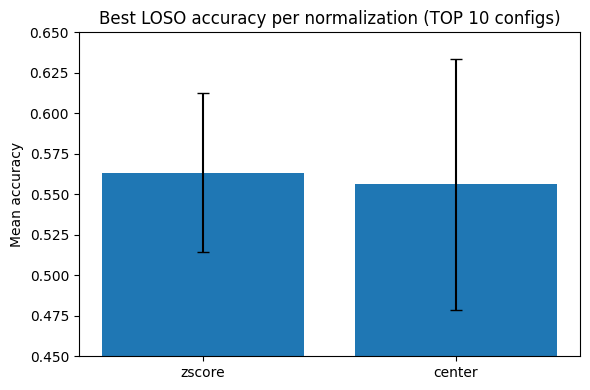

In [ ]:
df = pd.read_csv("../data/step1_normalization_results.csv")

top10 = df.sort_values("mean_acc", ascending=False).head(10)

best_per_norm_top10 = (
    top10.sort_values("mean_acc", ascending=False)
         .groupby("norm", as_index=False)
         .head(1)
)

plt.figure(figsize=(6, 4))
plt.bar(
    best_per_norm_top10["norm"],
    best_per_norm_top10["mean_acc"],
    yerr=best_per_norm_top10["std_acc"],
    capsize=4,
)

plt.ylim(0.45, 0.65)
plt.title("Best LOSO accuracy per normalization (TOP 10 configs)")
plt.ylabel("Mean accuracy")
plt.tight_layout()
plt.show()


We can conclude here that the z-score normalisation works slightly better than the centering especially in the top 3 even if we've some centering in the top 10, we can keep this in mind and keep only the better set of parameter for the centering in following iterations. 

#### 4.1.3.2 Number of keeped features K

According to the F-score scree plot displayed in introduction, almost all the variance is explained by the 500-600 features with the highest F-score. We will then explore numbers in this range to find the best `K`. 


In [ ]:
# =============================
# 0) Settings 
# =============================
K_LIST = [350, 400, 450, 550]

# Two best z-score configs + the best center config from Step 1
CONFIGS = [
    {"name": "zscore_xgb_9_003", "norm": "zscore", "n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
    {"name": "zscore_xgb_7_010", "norm": "zscore", "n_estimators": 500, "max_depth": 7, "learning_rate": 0.10},
    {"name": "center_xgb_9_003", "norm": "center", "n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
]


# =============================
# 1) Load raw data
# =============================
df = pd.read_csv("../data/raw/train.csv")

# Drop constant columns
cols_to_keep = ["session_id", "trial_number", "TRIAL_TYPE"]
constant_cols = [
    c for c in df.columns
    if c not in cols_to_keep and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

# Feature columns
feature_cols = [
    c for c in df.columns
    if c not in ["session_id", "trial_number", "TRIAL_TYPE"]
]

X_raw = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

# Label encoding
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# 2) Per-session normalization helper
# =============================
def normalize_per_session_matrix(X_mat, g_vec, mode: str):
    if mode == "none":
        return X_mat

    Xn = X_mat.copy()
    for sid in np.unique(g_vec):
        idx = np.where(g_vec == sid)[0]
        block = Xn[idx, :]

        mu = np.nanmean(block, axis=0)

        if mode == "center":
            Xn[idx, :] = block - mu
        elif mode == "zscore":
            sigma = np.nanstd(block, axis=0)
            sigma = np.where(sigma < 1e-8, 1.0, sigma)
            Xn[idx, :] = (block - mu) / sigma
        else:
            raise ValueError(f"Unknown mode: {mode}")

    return Xn


# =============================
# 3) LOSO loop: KNN imputation + ANOVA + XGBoost
# =============================
results = []

for cfg in CONFIGS:
    print(f"\n=== CONFIG: {cfg['name']} (norm={cfg['norm']}) ===")

    # Apply normalization once (no label usage → OK)
    X_norm = normalize_per_session_matrix(X_raw, groups, mode=cfg["norm"])

    for K in K_LIST:
        fold_accs = []

        for train_idx, test_idx in logo.split(X_norm, y, groups):
            X_tr_raw, X_te_raw = X_norm[train_idx], X_norm[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # KNN imputation (fit on train only)
            imputer = KNNImputer(n_neighbors=2)
            X_tr = imputer.fit_transform(X_tr_raw)
            X_te = imputer.transform(X_te_raw)

            # ANOVA feature ranking on train only
            scores, _ = f_classif(X_tr, y_tr)
            scores = np.nan_to_num(scores, nan=-np.inf)

            k = min(K, X_tr.shape[1])
            idx = np.argsort(scores)[-k:]

            X_tr_sel = X_tr[:, idx]
            X_te_sel = X_te[:, idx]

            # XGBoost (single thread for stability)
            model = XGBClassifier(
                n_estimators=cfg["n_estimators"],
                max_depth=cfg["max_depth"],
                learning_rate=cfg["learning_rate"],
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=num_classes,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=0,
                n_jobs=-1,
            )

            model.fit(X_tr_sel, y_tr)
            fold_accs.append(accuracy_score(y_te, model.predict(X_te_sel)))

        results.append({
            "config": cfg["name"],
            "norm": cfg["norm"],
            "K": K,
            "n_estimators": cfg["n_estimators"],
            "max_depth": cfg["max_depth"],
            "learning_rate": cfg["learning_rate"],
            "mean_acc": float(np.mean(fold_accs)),
            "std_acc": float(np.std(fold_accs)),
        })

        print(f"K={K:4d} → acc={np.mean(fold_accs):.4f}")


# =============================
# 4) Results
# =============================
res_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)

print("\n=== TOP RESULTS (K selection, KNN imputation) ===") 
print(res_df.head(20))

res_df.to_csv("../data/step2_K_selection_anova_KNN_zscore_vs_center.csv", index=False)
print("\nSaved: step2_K_selection_anova_KNN_zscore_vs_center.csv")


Although the initial XGBoost hyperparameter search was performed using K = 400, we subsequently evaluated a range of nearby values. The resulting performance curve shows a clear maximum around K = 400, with a consistent decrease for smaller and larger values. This confirms that the chosen dimensionality is not an artifact of the initial choice, but rather reflects a stable optimum of the pipeline. It's worth noting that from the first iteration we fixed K=400 and selected the other parameters thereafter, this way it's possible that we've included a moderate bias related to the pipeline.

#### 4.1.3.3 Imputer

This script evaluates which imputation strategy works best (and compares the best fixed XGBoost configurations found before) under a leakage-safe Leave-One-Session-Out (LOSO) setup.


In [ ]:
# =============================
# Settings (fixed)
# =============================
K_FEATURES = 400
NORM_MODE = "zscore"

MODELS = [
    {"name": "xgb_9_003",        "n_estimators": 500, "max_depth": 9, "learning_rate": 0.03},
    {"name": "xgb_7_010",        "n_estimators": 500, "max_depth": 7, "learning_rate": 0.10},
    {"name": "xgb_7_010_small",  "n_estimators": 200, "max_depth": 7, "learning_rate": 0.10},
]

IMPUTERS = [
    ("mean", SimpleImputer(strategy="mean")),
    ("knn1", KNNImputer(n_neighbors=1)),
    ("knn2", KNNImputer(n_neighbors=2)),
    ("knn3", KNNImputer(n_neighbors=3)),
]


# =============================
# 1) Load data
# =============================
df = pd.read_csv("../data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop constant feature columns
constant_cols = [
    c for c in df.columns
    if c not in ID_COLS and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X_raw = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# 2) Normalize per session (z-score)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn

if NORM_MODE == "zscore":
    X_norm = zscore_per_session(X_raw, groups)
elif NORM_MODE == "none":
    X_norm = X_raw
else:
    raise ValueError(f"Unknown NORM_MODE: {NORM_MODE}")


# =============================
# 3) LOSO evaluation
# =============================
summary_rows = []
fold_rows = []

for model_cfg in MODELS:
    print(f"\n==============================")
    print(f"MODEL: {model_cfg['name']}")
    print(f"==============================")

    for imp_name, imp in IMPUTERS:
        print(f"\n--- Imputer: {imp_name} ---")

        fold_accs = []

        for fold_i, (train_idx, test_idx) in enumerate(logo.split(X_norm, y, groups), start=1):
            heldout_sid = groups[test_idx][0]

            X_tr_raw, X_te_raw = X_norm[train_idx], X_norm[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # 1) Fit imputer on train only
            X_tr = imp.fit_transform(X_tr_raw)
            X_te = imp.transform(X_te_raw)

            # 2) Select top-K features with ANOVA on train only
            scores, _ = f_classif(X_tr, y_tr)
            scores = np.nan_to_num(scores, nan=-np.inf)

            k = min(K_FEATURES, X_tr.shape[1])
            feat_idx = np.argsort(scores)[-k:]

            X_tr_sel = X_tr[:, feat_idx]
            X_te_sel = X_te[:, feat_idx]

            # 3) Train + predict XGBoost
            model = XGBClassifier(
                n_estimators=model_cfg["n_estimators"],
                max_depth=model_cfg["max_depth"],
                learning_rate=model_cfg["learning_rate"],
                min_child_weight=1,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=num_classes,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=0,
                n_jobs=-1,
            )

            model.fit(X_tr_sel, y_tr)
            y_pred = model.predict(X_te_sel)
            acc = accuracy_score(y_te, y_pred)

            fold_accs.append(acc)

            fold_rows.append({
                "model": model_cfg["name"],
                "imputer": imp_name,
                "fold": fold_i,
                "heldout_session_id": heldout_sid,
                "K": K_FEATURES,
                "norm": NORM_MODE,
                "acc": float(acc),
            })

            print(f"  Fold {fold_i:02d} | held-out session {heldout_sid} | acc = {acc:.4f}")

        mean_acc = float(np.mean(fold_accs))
        std_acc = float(np.std(fold_accs))

        summary_rows.append({
            "model": model_cfg["name"],
            "imputer": imp_name,
            "K": K_FEATURES,
            "norm": NORM_MODE,
            "mean_acc": mean_acc,
            "std_acc": std_acc,
        })

        print(f"→ mean accuracy: {mean_acc:.4f} ± {std_acc:.4f}")


# =============================
# 4) Save results
# =============================
summary_df = pd.DataFrame(summary_rows).sort_values("mean_acc", ascending=False)
folds_df = pd.DataFrame(fold_rows).sort_values(["model", "imputer", "fold"])

print("\n=== TOP RESULTS (summary) ===")
print(summary_df)

summary_df.to_csv("../data/step3_imputer_selection_summary.csv", index=False)
folds_df.to_csv("../data/step3_imputer_selection_folds.csv", index=False)

print("\nSaved: step3_imputer_selection_summary.csv")
print("Saved: step3_imputer_selection_folds.csv")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3865038602.py:67: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_9_003

--- Imputer: mean ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5710
  Fold 02 | held-out session PG082_20221114 | acc = 0.6515
  Fold 03 | held-out session PG083_20221125 | acc = 0.5833
  Fold 04 | held-out session PG083_20221129 | acc = 0.5342
  Fold 05 | held-out session PG084_20221206 | acc = 0.5591
  Fold 06 | held-out session PG084_20221207 | acc = 0.5771
  Fold 07 | held-out session PG085_20221213 | acc = 0.4653


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


  Fold 08 | held-out session PG085_20221214 | acc = 0.5486
→ mean accuracy: 0.5613 ± 0.0488

--- Imputer: knn1 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5755
  Fold 02 | held-out session PG082_20221114 | acc = 0.6156
  Fold 03 | held-out session PG083_20221125 | acc = 0.5802
  Fold 04 | held-out session PG083_20221129 | acc = 0.5408
  Fold 05 | held-out session PG084_20221206 | acc = 0.5669
  Fold 06 | held-out session PG084_20221207 | acc = 0.5745
  Fold 07 | held-out session PG085_20221213 | acc = 0.4634
  Fold 08 | held-out session PG085_20221214 | acc = 0.5576
→ mean accuracy: 0.5593 ± 0.0414

--- Imputer: knn2 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5846
  Fold 02 | held-out session PG082_20221114 | acc = 0.6482
  Fold 03 | held-out session PG083_20221125 | acc = 0.5802
  Fold 04 | held-out session PG083_20221129 | acc = 0.5386
  Fold 05 | held-out session PG084_20221206 | acc = 0.5551
  Fold 06 | held-out session PG084_20221207 | acc = 0.5785
  F

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


  Fold 08 | held-out session PG085_20221214 | acc = 0.5324
→ mean accuracy: 0.5528 ± 0.0465

--- Imputer: knn1 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5695
  Fold 02 | held-out session PG082_20221114 | acc = 0.6319
  Fold 03 | held-out session PG083_20221125 | acc = 0.5896
  Fold 04 | held-out session PG083_20221129 | acc = 0.5673
  Fold 05 | held-out session PG084_20221206 | acc = 0.5512
  Fold 06 | held-out session PG084_20221207 | acc = 0.5864
  Fold 07 | held-out session PG085_20221213 | acc = 0.4465
  Fold 08 | held-out session PG085_20221214 | acc = 0.5683
→ mean accuracy: 0.5639 ± 0.0497

--- Imputer: knn2 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5755
  Fold 02 | held-out session PG082_20221114 | acc = 0.6384
  Fold 03 | held-out session PG083_20221125 | acc = 0.5818
  Fold 04 | held-out session PG083_20221129 | acc = 0.5342
  Fold 05 | held-out session PG084_20221206 | acc = 0.5669
  Fold 06 | held-out session PG084_20221207 | acc = 0.5691
  F

/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_base.py:653: UserWarning: Skipping features without any observed values: [ 90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119]. At least one non-missing value is needed for imputation with strategy='mean'.
  warnings.warn(


  Fold 08 | held-out session PG085_20221214 | acc = 0.5288
→ mean accuracy: 0.5491 ± 0.0535

--- Imputer: knn1 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5785
  Fold 02 | held-out session PG082_20221114 | acc = 0.6450
  Fold 03 | held-out session PG083_20221125 | acc = 0.5865
  Fold 04 | held-out session PG083_20221129 | acc = 0.5475
  Fold 05 | held-out session PG084_20221206 | acc = 0.5531
  Fold 06 | held-out session PG084_20221207 | acc = 0.5745
  Fold 07 | held-out session PG085_20221213 | acc = 0.4484
  Fold 08 | held-out session PG085_20221214 | acc = 0.5701
→ mean accuracy: 0.5630 ± 0.0514

--- Imputer: knn2 ---
  Fold 01 | held-out session PG082_20221113 | acc = 0.5785
  Fold 02 | held-out session PG082_20221114 | acc = 0.6352
  Fold 03 | held-out session PG083_20221125 | acc = 0.5692
  Fold 04 | held-out session PG083_20221129 | acc = 0.5276
  Fold 05 | held-out session PG084_20221206 | acc = 0.5650
  Fold 06 | held-out session PG084_20221207 | acc = 0.5758
  F

Globally, KNN 1 and 2 are better than KNN 3, increasing the number of neighbors beyond 2 does not bring additional benefit in this setting. We can keep in mind that mean was good too since the differences in the head values of `TOP RESULTS`are very small, mean imputation performs comparably on average, but is less robust due to degenerate features in some LOSO folds. We can associate KNN 1 to xgb_7_010 and its small variant and KNN2 to xgb_9_003 but no strong interaction between the imputation method and the XGBoost configuration is observed. KNN with 1 or 2 neighbors consistently yields competitive performance across all tested models.

Since the iterative imputer is computationally expensive, we did not include it in the full LOSO imputation comparison. Instead, we performed a targeted evaluation on a single held-out session using the best performing XGBoost configuration and the previously selected imputation strategy. This controlled single-fold test allows us to assess whether the iterative imputer provides a meaningful performance gain before considering a more costly full cross-validation.

To do so we selected 2 folds: the one that always provides bad results `PG085_20221213` and an other arbitrary representative fold `PG083_20221125`.

In [ ]:


# =============================
# Fixed best pipeline
# =============================
K_FEATURES = 400

FOLDS_TO_TEST = [
    "PG085_20221213",  # worst fold 
    "PG083_20221125",  # representative fold
]

MODEL_CFG = {
    "n_estimators": 500,
    "max_depth": 7,
    "learning_rate": 0.10,
}


# =============================
# Load & preprocess data
# =============================
df = pd.read_csv("../data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop global constant columns
constant_cols = [
    c for c in df.columns
    if c not in ID_COLS and df[c].nunique() <= 1
]
df = df.drop(columns=constant_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X_raw = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)


# =============================
# Exact same normalization as base pipeline
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn


X = zscore_per_session(X_raw, groups)


# =============================
# Helper: evaluate one fold + one imputer
# =============================
def eval_fold(session_id, imputer, name):
    logo = LeaveOneGroupOut()

    for train_idx, test_idx in logo.split(X, y, groups):
        if groups[test_idx][0] == session_id:
            break

    X_train_raw = X[train_idx]
    X_test_raw  = X[test_idx]
    y_train = y[train_idx]
    y_test  = y[test_idx]

    # Imputation (fit on train only)
    X_train_imp = imputer.fit_transform(X_train_raw)
    X_test_imp  = imputer.transform(X_test_raw)

    # ANOVA top-K (train only)
    scores, _ = f_classif(X_train_imp, y_train)
    scores = np.nan_to_num(scores, nan=-np.inf)
    topk_idx = np.argsort(scores)[-K_FEATURES:]

    X_tr = X_train_imp[:, topk_idx]
    X_te = X_test_imp[:, topk_idx]

    model = XGBClassifier(
        n_estimators=MODEL_CFG["n_estimators"],
        max_depth=MODEL_CFG["max_depth"],
        learning_rate=MODEL_CFG["learning_rate"],
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
    )

    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_test, y_pred)

    print(f"{name:<28s} | acc = {acc:.4f}")
    return acc


# =============================
# Run comparison
# =============================
print("\n=== Iterative vs KNN (2-fold test) ===")

for sid in FOLDS_TO_TEST:
    print(f"\n--- Held-out session: {sid} ---")

    acc_knn = eval_fold(
        sid,
        KNNImputer(n_neighbors=1),
        "KNNImputer (k=1)"
    )

    acc_iter = eval_fold(
        sid,
        IterativeImputer(
            estimator=BayesianRidge(),
            max_iter=10,
            n_nearest_features=50,
            tol=1e-2,
            sample_posterior=False,
            random_state=0,
            skip_complete=True,
        ),
        "IterativeImputer (max_iter=3)"
    )

    print(f"Δ (iterative - knn1): {acc_iter - acc_knn:+.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3226091643.py:66: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



=== Iterative vs KNN (2-fold test) ===

--- Held-out session: PG085_20221213 ---
KNNImputer (k=1)             | acc = 0.4465


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


IterativeImputer (max_iter=3) | acc = 0.4540
Δ (iterative - knn1): +0.0075

--- Held-out session: PG083_20221125 ---
KNNImputer (k=1)             | acc = 0.5896


/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


IterativeImputer (max_iter=3) | acc = 0.5928
Δ (iterative - knn1): +0.0031


Although a lightweight iterative imputation strategy yielded a small performance improvement on a limited number of folds, the effect was not robust and did not persist with increased iterations. Given the substantially higher computational cost and the lack of consistent gains across folds, iterative imputation was not retained in the final pipeline. KNN imputation was selected for its stability, simplicity, and comparable performance.

#### 4.1.3.4 Regularization Strategy
In the final tuning stage, we focused on regularization parameters of the XGBoost model while keeping the entire preprocessing pipeline fixed. Specifically, per-session z-score normalization, KNN imputation (k=1,2), and ANOVA-based top-400 feature selection were applied within each LOSO fold. Regularization was explored across three representative XGBoost configurations using a reduced grid. This approach allows us to assess whether explicit regularization improves predictive accuracy and stability across sessions without confounding effects from earlier pipeline choices. More explicitely we vary these parameters:

`min_child_weight` controls the minimum amount of data required to create a split. Increasing this value prevents the model from creating splits based on very small or session-specific subsets of samples.

`gamma` imposes a minimum gain required to perform a split, effectively discouraging weak or noisy splits that do not significantly improve the objective.

`reg_lambda` (L2 regularization) penalizes large leaf weights, stabilizing predictions and reducing variance.

`reg_alpha` (L1 regularization) enforces sparsity in leaf weights; it is set to zero here because sparsity is already induced upstream by ANOVA feature selection and feature subsampling.


We do not perform an extensive search on this section, the idea was to determine if a moderate or a strong regularization helped the tested models. 


In [ ]:
# =============================
# Fixed pipeline settings
# =============================
K_FEATURES = 400
NORM = "zscore"

MODELS = [
    dict(name="xgb_7_010",       n_estimators=500, max_depth=7, learning_rate=0.10, knn_k=1),
    dict(name="xgb_9_003",       n_estimators=500, max_depth=9, learning_rate=0.03, knn_k=2),
    dict(name="xgb_7_010_small", n_estimators=200, max_depth=7, learning_rate=0.10, knn_k=1),
]

REG_SETS = {
    "baseline": dict(min_child_weight=1,  gamma=0.0, reg_lambda=1.0,  reg_alpha=0.0),
    "moderate": dict(min_child_weight=5,  gamma=0.1, reg_lambda=5.0,  reg_alpha=0.0),
    "strong":   dict(min_child_weight=10, gamma=0.3, reg_lambda=10.0, reg_alpha=0.0),
}


# =============================
# Load data
# =============================
df = pd.read_csv("../data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]
const_cols = [c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1]
df = df.drop(columns=const_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# Per-session z-score 
# =============================
Xz = X.copy()
for sid in np.unique(groups):
    idx = groups == sid
    mu = np.nanmean(Xz[idx], axis=0)
    sigma = np.nanstd(Xz[idx], axis=0)
    sigma[sigma < 1e-8] = 1.0
    Xz[idx] = (Xz[idx] - mu) / sigma


# =============================
# Evaluation
# =============================
results = []

for model_cfg in MODELS:
    print(f"\n==============================")
    print(f"MODEL: {model_cfg['name']}")
    print(f"==============================")

    for reg_name, reg in REG_SETS.items():
        fold_accs = []

        for train_idx, test_idx in logo.split(Xz, y, groups):
            X_tr, X_te = Xz[train_idx], Xz[test_idx]
            y_tr, y_te = y[train_idx], y[test_idx]

            # Imputation
            imputer = KNNImputer(n_neighbors=model_cfg["knn_k"])
            X_tr = imputer.fit_transform(X_tr)
            X_te = imputer.transform(X_te)

            # ANOVA selection (train only)
            scores, _ = f_classif(X_tr, y_tr)
            scores = np.nan_to_num(scores, nan=-np.inf)
            topk = np.argsort(scores)[-K_FEATURES:]

            X_tr = X_tr[:, topk]
            X_te = X_te[:, topk]

            model = XGBClassifier(
                n_estimators=model_cfg["n_estimators"],
                max_depth=model_cfg["max_depth"],
                learning_rate=model_cfg["learning_rate"],
                subsample=0.8,
                colsample_bytree=0.8,
                objective="multi:softprob",
                num_class=num_classes,
                eval_metric="mlogloss",
                tree_method="hist",
                random_state=0,
                n_jobs=-1,
                **reg,
            )

            model.fit(X_tr, y_tr)
            y_pred = model.predict(X_te)
            fold_accs.append(accuracy_score(y_te, y_pred))

        mean_acc = np.mean(fold_accs)
        std_acc = np.std(fold_accs)

        print(f"{reg_name:>9} | acc = {mean_acc:.4f} ± {std_acc:.4f}")

        results.append({
            "model": model_cfg["name"],
            "reg": reg_name,
            "mean_acc": mean_acc,
            "std_acc": std_acc,
        })


results_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)
results_df.to_csv("../data/regularization_simple_test.csv", index=False)

print("\n=== SUMMARY ===")
print(results_df)


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/1452548196.py:60: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xz[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_7_010
 baseline | acc = 0.5639 ± 0.0497
 moderate | acc = 0.5560 ± 0.0443
   strong | acc = 0.5523 ± 0.0535

MODEL: xgb_9_003
 baseline | acc = 0.5633 ± 0.0490
 moderate | acc = 0.5581 ± 0.0460
   strong | acc = 0.5595 ± 0.0482

MODEL: xgb_7_010_small
 baseline | acc = 0.5630 ± 0.0514
 moderate | acc = 0.5559 ± 0.0474
   strong | acc = 0.5552 ± 0.0567

=== SUMMARY ===
             model       reg  mean_acc   std_acc
0        xgb_7_010  baseline  0.563856  0.049745
3        xgb_9_003  baseline  0.563261  0.049021
6  xgb_7_010_small  baseline  0.562951  0.051432
5        xgb_9_003    strong  0.559525  0.048215
4        xgb_9_003  moderate  0.558121  0.046035
1        xgb_7_010  moderate  0.555994  0.044282
7  xgb_7_010_small  moderate  0.555857  0.047366
8  xgb_7_010_small    strong  0.555212  0.056671
2        xgb_7_010    strong  0.552305  0.053473


The regularization grid search shows that adding explicit regularization consistently decreases performance across all tested XGBoost configurations. The baseline models achieve the highest mean accuracy and comparable variability, indicating that the existing pipeline already provides sufficient regularization.
To ensure the model do not apply a too strong regularization we can perform a mini test with the baseline parameters vs weak regularization parameters on one model. 

In [ ]:
# =============================
# Fixed pipeline settings (unchanged)
# =============================
K_FEATURES = 400

MODEL = dict(
    name="xgb_7_010",
    n_estimators=500,
    max_depth=7,
    learning_rate=0.10,
    knn_k=1,
)

# Only 2 reg settings: baseline vs slightly weaker L2
REG_SETS = {
    "baseline": dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0),
    "weak":     dict(min_child_weight=1, gamma=0.0, reg_lambda=0.5, reg_alpha=0.0),
}


# =============================
# Load data 
# =============================
df = pd.read_csv("../data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]
const_cols = [c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1]
df = df.drop(columns=const_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].values
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

logo = LeaveOneGroupOut()


# =============================
# Per-session z-score
# =============================
Xz = X.copy()
for sid in np.unique(groups):
    idx = groups == sid
    mu = np.nanmean(Xz[idx], axis=0)
    sigma = np.nanstd(Xz[idx], axis=0)
    sigma[sigma < 1e-8] = 1.0
    Xz[idx] = (Xz[idx] - mu) / sigma


# =============================
# Evaluation 
# =============================
print(f"\nMODEL: {MODEL['name']} (knn_k={MODEL['knn_k']}, K={K_FEATURES}, zscore per session)")

for reg_name, reg in REG_SETS.items():
    fold_accs = []

    for train_idx, test_idx in logo.split(Xz, y, groups):
        X_tr, X_te = Xz[train_idx], Xz[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]

        # Imputation 
        imputer = KNNImputer(n_neighbors=MODEL["knn_k"])
        X_tr = imputer.fit_transform(X_tr)
        X_te = imputer.transform(X_te)

        # ANOVA selection 
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        topk = np.argsort(scores)[-K_FEATURES:]

        X_tr = X_tr[:, topk]
        X_te = X_te[:, topk]

        # XGBoost 
        model = XGBClassifier(
            n_estimators=MODEL["n_estimators"],
            max_depth=MODEL["max_depth"],
            learning_rate=MODEL["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **reg,
        )

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        fold_accs.append(accuracy_score(y_te, y_pred))

    mean_acc = float(np.mean(fold_accs))
    std_acc = float(np.std(fold_accs))
    print(f"{reg_name:>8} | acc = {mean_acc:.4f} ± {std_acc:.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3345168305.py:61: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xz[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_7_010 (knn_k=1, K=400, zscore per session)
baseline | acc = 0.5639 ± 0.0497
    weak | acc = 0.5596 ± 0.0463


We can observe that the weak regulariastion (lower L2 regularisation) do not lead to a better accuracy. 

Finally, we keep these 2 models as our best performing models after all search iterations:

`xgb_7_010`: n_estimators=500, max_depth=7, learning_rate=0.10, knn_k=1 

`xgb_9_003`: n_estimators=500, max_depth=9, learning_rate=0.03, knn_k=2

The rest of the pipeline is not changed as the best normalisaton is zscore and `K`=400 is better. 



### 4.1.4 Final LOSO 
In this section we perform the final LOSO for the 2 best models we've foud with the best pipeline parameters. 

/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3513909783.py:67: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



MODEL: xgb_7_010 | IMPUTER: knn1
  Fold 01 | held-out session PG082_20221113 | acc = 0.5695
  Fold 02 | held-out session PG082_20221114 | acc = 0.6319
  Fold 03 | held-out session PG083_20221125 | acc = 0.5896
  Fold 04 | held-out session PG083_20221129 | acc = 0.5673
  Fold 05 | held-out session PG084_20221206 | acc = 0.5512
  Fold 06 | held-out session PG084_20221207 | acc = 0.5864
  Fold 07 | held-out session PG085_20221213 | acc = 0.4465
  Fold 08 | held-out session PG085_20221214 | acc = 0.5683
→ FINAL LOSO: 0.5639 ± 0.0497


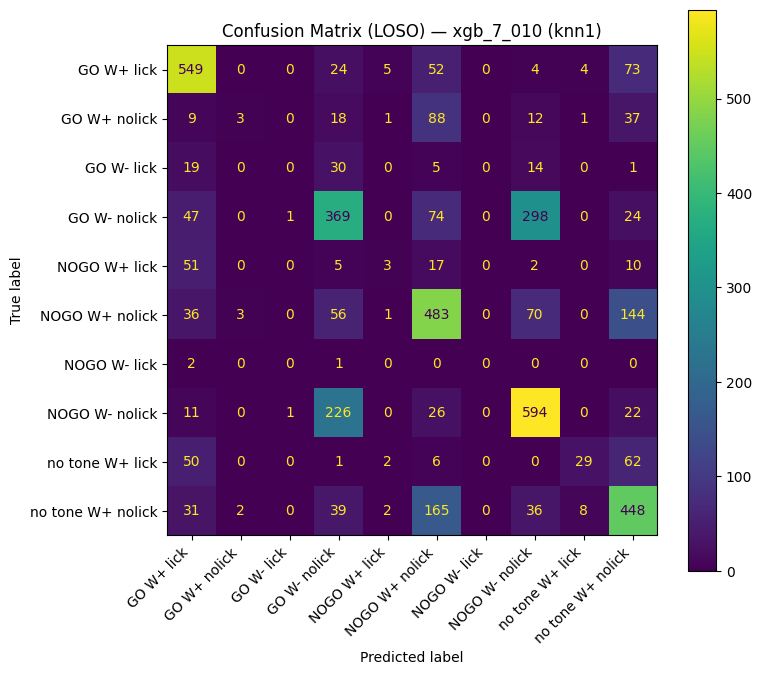


MODEL: xgb_9_003 | IMPUTER: knn2
  Fold 01 | held-out session PG082_20221113 | acc = 0.5846
  Fold 02 | held-out session PG082_20221114 | acc = 0.6482
  Fold 03 | held-out session PG083_20221125 | acc = 0.5802
  Fold 04 | held-out session PG083_20221129 | acc = 0.5386
  Fold 05 | held-out session PG084_20221206 | acc = 0.5551
  Fold 06 | held-out session PG084_20221207 | acc = 0.5785
  Fold 07 | held-out session PG085_20221213 | acc = 0.4615
  Fold 08 | held-out session PG085_20221214 | acc = 0.5594
→ FINAL LOSO: 0.5633 ± 0.0490


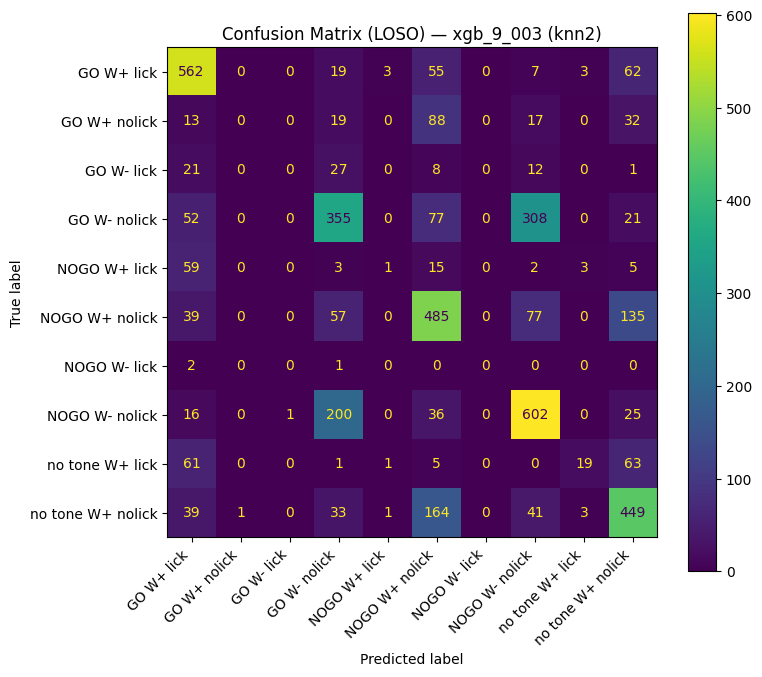


=== FINAL RESULTS (summary) ===
       model imputer    K    norm  mean_acc   std_acc
0  xgb_7_010    knn1  400  zscore  0.563856  0.049745
1  xgb_9_003    knn2  400  zscore  0.563261  0.049021

Saved: final_loso_2models_summary.csv
Saved: final_loso_2models_folds.csv


In [ ]:
# =============================
# Settings (final LOSO)
# =============================
K_FEATURES = 400
NORM_MODE = "zscore"

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500, max_depth=7, learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1), imputer_name="knn1",
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500, max_depth=9, learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2), imputer_name="knn2",
    ),
]


# =============================
# 1) Load data
# =============================
df = pd.read_csv("../data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

constant_cols = [c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1]
df = df.drop(columns=constant_cols)

feature_cols = [c for c in df.columns if c not in ID_COLS]

X_raw = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)
class_names = list(le.classes_)
num_classes = len(class_names)

logo = LeaveOneGroupOut()


# =============================
# 2) Normalize per session (z-score)  
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn

if NORM_MODE == "zscore":
    X_norm = zscore_per_session(X_raw, groups)
elif NORM_MODE == "none":
    X_norm = X_raw
else:
    raise ValueError(f"Unknown NORM_MODE: {NORM_MODE}")


# =============================
# 3) Final LOSO (2 models) + Confusion matrices
# =============================
summary_rows = []
fold_rows = []

for cfg in MODELS:
    print("\n==============================")
    print(f"MODEL: {cfg['name']} | IMPUTER: {cfg['imputer_name']}")
    print("==============================")

    fold_accs = []
    y_true_all, y_pred_all = [], []

    for fold_i, (train_idx, test_idx) in enumerate(logo.split(X_norm, y, groups), start=1):
        heldout_sid = groups[test_idx][0]

        X_tr_raw, X_te_raw = X_norm[train_idx], X_norm[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]

        # 1) Imputation
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr_raw)
        X_te = imp.transform(X_te_raw)

        # 2) Top-K ANOVA 
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)

        k = min(K_FEATURES, X_tr.shape[1])
        feat_idx = np.argsort(scores)[-k:]

        X_tr_sel = X_tr[:, feat_idx]
        X_te_sel = X_te[:, feat_idx]

        # 3) XGBoost 
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
        )

        model.fit(X_tr_sel, y_tr)
        y_pred = model.predict(X_te_sel)
        acc = accuracy_score(y_te, y_pred)

        fold_accs.append(acc)
        y_true_all.append(y_te)
        y_pred_all.append(y_pred)

        fold_rows.append({
            "model": cfg["name"],
            "imputer": cfg["imputer_name"],
            "fold": fold_i,
            "heldout_session_id": heldout_sid,
            "K": K_FEATURES,
            "norm": NORM_MODE,
            "acc": float(acc),
        })

        print(f"  Fold {fold_i:02d} | held-out session {heldout_sid} | acc = {acc:.4f}")

    # ---- Summary + global confusion matrix ----
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    mean_acc = float(np.mean(fold_accs))
    std_acc = float(np.std(fold_accs))

    summary_rows.append({
        "model": cfg["name"],
        "imputer": cfg["imputer_name"],
        "K": K_FEATURES,
        "norm": NORM_MODE,
        "mean_acc": mean_acc,
        "std_acc": std_acc,
    })

    print(f"→ FINAL LOSO: {mean_acc:.4f} ± {std_acc:.4f}")

    cm = confusion_matrix(y_true_all, y_pred_all, labels=np.arange(num_classes))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(8, 7))
    disp.plot(ax=ax, values_format="d")
    ax.set_title(f"Confusion Matrix (LOSO) — {cfg['name']} ({cfg['imputer_name']})")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


# =============================
# 4) Save results
# =============================
summary_df = pd.DataFrame(summary_rows).sort_values("mean_acc", ascending=False)
folds_df = pd.DataFrame(fold_rows).sort_values(["model", "fold"])

print("\n=== FINAL RESULTS (summary) ===")
print(summary_df)

summary_df.to_csv("../data/final_loso_2models_summary.csv", index=False)
folds_df.to_csv("../data/final_loso_2models_folds.csv", index=False)
print("\nSaved: final_loso_2models_summary.csv")
print("Saved: final_loso_2models_folds.csv")


The confusion matrices indicate that a substantial fraction of misclassifications involves transitions between GO and NOGO conditions, particularly when the tone is the primary changing cue. However, this pattern must be interpreted with caution. For certain classes such as W− nolick, the absolute number of errors is large mainly because these conditions are highly represented in the dataset. In relative terms, the proportion of correctly classified samples for these classes remains high. Thus, while GO–NOGO confusions constitute an important source of error, they do not necessarily reflect poor separability for all involved conditions, but rather a combination of subtle cue differences and class frequency imbalance.

In [ ]:

labels = [
    "GO W+ lick",
    "GO W+ nolick",
    "GO W- lick",
    "GO W- nolick",
    "NOGO W+ lick",
    "NOGO W+ nolick",
    "NOGO W- lick",
    "NOGO W- nolick",
    "no tone W+ lick",
    "no tone W+ nolick",
]

cm = np.array([
    [549, 0, 0, 24, 5, 52, 0, 4, 4, 73],
    [9, 3, 0, 18, 1, 88, 0, 12, 1, 37],
    [19, 0, 0, 30, 0, 5, 0, 14, 0, 1],
    [47, 0, 1, 369, 0, 74, 0, 298, 0, 24],
    [51, 0, 0, 5, 3, 17, 0, 2, 0, 10],
    [36, 3, 0, 56, 1, 483, 0, 70, 0, 144],
    [2, 0, 0, 1, 0, 0, 0, 0, 0, 0],
    [11, 0, 1, 226, 0, 26, 0, 594, 0, 22],
    [50, 0, 0, 1, 2, 6, 0, 0, 29, 62],
    [31, 2, 0, 39, 2, 165, 0, 36, 8, 448],
])

def parse_factors(label: str):
    if label.startswith("no tone"):
        aud = "NOTONE"
    elif label.startswith("NOGO"):
        aud = "NOGO"
    elif label.startswith("GO"):
        aud = "GO"
    else:
        aud = "UNK_AUD"

    # FIX: correct whisker parsing
    m = re.search(r"W[+-]", label)
    whisk = m.group(0) if m else "UNK_W"

    if "nolick" in label:
        act = "NOLICK"
    elif re.search(r"\blick\b", label):
        act = "LICK"
    else:
        act = "UNK_ACT"

    return aud, whisk, act


factors = {lab: parse_factors(lab) for lab in labels}

# ----------------------------
# Count "factor-errors" (0..3 per sample)
# ----------------------------
aud_err = 0
whisk_err = 0
act_err = 0

# optional: to see top contributing confusions per factor
contrib = []

for i, true_lab in enumerate(labels):
    true_aud, true_whisk, true_act = factors[true_lab]
    for j, pred_lab in enumerate(labels):
        n = int(cm[i, j])
        if n == 0 or i == j:
            continue

        pred_aud, pred_whisk, pred_act = factors[pred_lab]

        da = (true_aud != pred_aud)
        dw = (true_whisk != pred_whisk)
        db = (true_act != pred_act)

        if da: aud_err += n
        if dw: whisk_err += n
        if db: act_err += n

        contrib.append({
            "true": true_lab,
            "pred": pred_lab,
            "count": n,
            "aud_err": int(da) * n,
            "whisk_err": int(dw) * n,
            "act_err": int(db) * n,
            "n_factors_wrong": int(da) + int(dw) + int(db),
            "factor_errors_from_cell": n * (int(da) + int(dw) + int(db)),
        })

total_samples = int(cm.sum())
total_correct = int(np.trace(cm))
total_misclassified = total_samples - total_correct

total_factor_errors = aud_err + whisk_err + act_err  # this can be > total_misclassified

summary = pd.DataFrame([
    {"factor": "Auditory (GO/NOGO/no tone)", "factor_errors": aud_err},
    {"factor": "Whisker (W+ vs W-)",         "factor_errors": whisk_err},
    {"factor": "Action (lick vs nolick)",    "factor_errors": act_err},
]).sort_values("factor_errors", ascending=False)

summary["share_of_factor_errors"] = summary["factor_errors"] / total_factor_errors

print("Total samples:", total_samples)
print("Total correct:", total_correct)
print("Total misclassified (standard):", total_misclassified)
print("Total factor-errors (multi-count):", total_factor_errors)
print("\nFactor-errors by information type:")
print(summary.to_string(index=False))

# Optional: show which confusions contribute most to (multi) factor-errors
contrib_df = pd.DataFrame(contrib).sort_values("factor_errors_from_cell", ascending=False)
print("\nTop 10 confusions contributing most factor-errors:")
print(contrib_df[["true","pred","count","n_factors_wrong","factor_errors_from_cell"]].head(10).to_string(index=False))

Total samples: 4407
Total correct: 2478
Total misclassified (standard): 1929
Total factor-errors (multi-count): 2549

Factor-errors by information type:
                    factor  factor_errors  share_of_factor_errors
Auditory (GO/NOGO/no tone)           1595                0.625736
        Whisker (W+ vs W-)            498                0.195371
   Action (lick vs nolick)            456                0.178894

Top 10 confusions contributing most factor-errors:
             true              pred  count  n_factors_wrong  factor_errors_from_cell
     GO W- nolick    NOGO W- nolick    298                1                      298
   NOGO W- nolick      GO W- nolick    226                1                      226
no tone W+ nolick    NOGO W+ nolick    165                1                      165
     GO W- nolick    NOGO W+ nolick     74                2                      148
       GO W+ lick no tone W+ nolick     73                2                      146
   NOGO W+ nolick no 

### 4.1.5 Submission 
In this section we prepare the submission folders for the 2 best models tuned in the previous section.

In [ ]:
# =============================
# Settings (final)
# =============================
K_FEATURES = 400

REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(
        name="xgb_7_010__500trees_depth7_lr0p10__knn1__K400__zscore_session__REGbaseline",
        n_estimators=500, max_depth=7, learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
        imputer_tag="knn1",
    ),
    dict(
        name="xgb_9_003__500trees_depth9_lr0p03__knn2__K400__zscore_session__REGbaseline",
        n_estimators=500, max_depth=9, learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
        imputer_tag="knn2",
    ),
]


# =============================
# Utils: z-score par session (EXACTEMENT comme ton grid)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = np.where(session_ids == sid)[0]
        block = Xn[idx]

        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)

        Xn[idx] = (block - mu) / sigma
    return Xn


# =============================
# 1) Load TRAIN (complet) + preproc commun
# =============================
train = pd.read_csv("../data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# drop constant columns (comme ton script)
constant_cols = [c for c in train.columns if c not in ID_COLS and train[c].nunique() <= 1]
train = train.drop(columns=constant_cols)

feature_cols = [c for c in train.columns if c not in ID_COLS]

X_train_raw = train[feature_cols].to_numpy()
y_train_str = train["TRIAL_TYPE"].to_numpy()
groups_train = train["session_id"].to_numpy()

# labels
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
num_classes = len(le.classes_)
print("Classes:", le.classes_)

# z-score par session (sur tout le train)
X_train_norm = zscore_per_session(X_train_raw, groups_train)


# =============================
# 2) Load TEST + preproc commun (z-score par session)
# =============================
test = pd.read_csv("../data/raw/test.csv")

needed_cols = ["session_id", "trial_number"] + feature_cols
test = test[needed_cols].copy()

X_test_raw = test[feature_cols].to_numpy()
groups_test = test["session_id"].to_numpy()

# z-score par session (sur tout le test)
X_test_norm = zscore_per_session(X_test_raw, groups_test)


# =============================
# 3) Train + Predict + Save submission for each model
# =============================
sample = pd.read_csv("../data/raw/sample_submission.csv")

for cfg in MODELS:
    print("\n==============================")
    print(f"Training model: {cfg['name']}")
    print("==============================")

    # 1) Imputation (fit sur tout le train)
    imputer = cfg["imputer"]
    X_tr_imp = imputer.fit_transform(X_train_norm)
    X_te_imp = imputer.transform(X_test_norm)

    # 2) Feature selection top-K (fit sur tout le train)
    scores, _ = f_classif(X_tr_imp, y_train)
    scores = np.nan_to_num(scores, nan=-np.inf)

    k = min(K_FEATURES, X_tr_imp.shape[1])
    feat_idx = np.argsort(scores)[-k:]

    X_tr_final = X_tr_imp[:, feat_idx]
    X_te_final = X_te_imp[:, feat_idx]

    # 3) XGBoost (baseline reg)
    model = XGBClassifier(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        learning_rate=cfg["learning_rate"],

        subsample=0.8,
        colsample_bytree=0.8,

        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",

        random_state=0,
        n_jobs=-1,

        **REG_BASELINE,
    )

    model.fit(X_tr_final, y_train)

    # 4) Predict
    y_pred_int = model.predict(X_te_final)
    y_pred_str = le.inverse_transform(y_pred_int)

    # 5) Submission
    submission = sample.copy()
    submission["TRIAL_TYPE"] = y_pred_str

    out_path = f"../data/submission__{cfg['name']}.csv"
    submission.to_csv(out_path, index=False)

    print(f"Saved: {out_path}")
    print(submission.head())


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/4176694203.py:43: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/4176694203.py:43: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,



Training model: xgb_7_010__500trees_depth7_lr0p10__knn1__K400__zscore_session__REGbaseline
Saved: submission__xgb_7_010__500trees_depth7_lr0p10__knn1__K400__zscore_session__REGbaseline.csv
   ID    TRIAL_TYPE
0   1  GO W- nolick
1   2    GO W+ lick
2   3  GO W- nolick
3   4    GO W+ lick
4   5    GO W+ lick

Training model: xgb_9_003__500trees_depth9_lr0p03__knn2__K400__zscore_session__REGbaseline
Saved: submission__xgb_9_003__500trees_depth9_lr0p03__knn2__K400__zscore_session__REGbaseline.csv
   ID         TRIAL_TYPE
0   1     NOGO W- nolick
1   2         GO W+ lick
2   3     NOGO W- nolick
3   4  no tone W+ nolick
4   5         GO W+ lick


### 4.1.6 Ensemble
Since Both model are really good, it would be intersting to combine them. If the two models exhibit partially uncorrelated error patterns, combining them via probability averaging is expected to reduce variance and improve generalization performance

/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/4011396882.py:32: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


xgb_7_010 OOF acc = 0.562287270251872
xgb_9_003 OOF acc = 0.5611527115951894


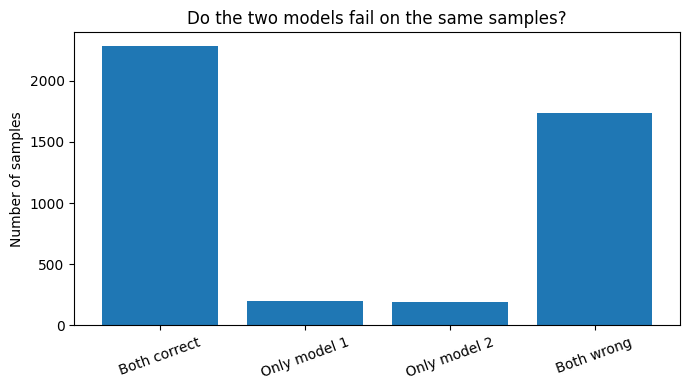


Summary:
Only model 1 correct : 197
Only model 2 correct : 192
Both wrong           : 1737


In [ ]:
# =============================
# Minimal configuration
# =============================
K_FEATURES = 400
REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(name="xgb_7_010", n_estimators=500, max_depth=7, learning_rate=0.10, imputer=KNNImputer(n_neighbors=1)),
    dict(name="xgb_9_003", n_estimators=500, max_depth=9, learning_rate=0.03, imputer=KNNImputer(n_neighbors=2)),
]



# =============================
# Session-wise z-score normalization (identical to the pipeline)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# Load data
# =============================
df = pd.read_csv("../data/raw/train.csv")
ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

df = df.drop(columns=[c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1])
feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

le = LabelEncoder()
y = le.fit_transform(y_str)

X = zscore_per_session(X, groups)

logo = LeaveOneGroupOut()


# =============================
# Out-of-fold predictions for each model
# =============================
oof_preds = {}

for cfg in MODELS:
    y_pred = np.full_like(y, -1)

    for train_idx, test_idx in logo.split(X, y, groups):
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr = y[train_idx]

        # Imputation
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr)
        X_te = imp.transform(X_te)

        # Feature selection
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        feat_idx = np.argsort(scores)[-K_FEATURES:]

        # Model
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=len(le.classes_),
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **REG_BASELINE,
        )

        model.fit(X_tr[:, feat_idx], y_tr)
        y_pred[test_idx] = model.predict(X_te[:, feat_idx])

    oof_preds[cfg["name"]] = y_pred
    print(cfg["name"], "OOF acc =", accuracy_score(y, y_pred))


# =============================
# Error comparison (CORE ANALYSIS)
# =============================
p1 = oof_preds[MODELS[0]["name"]]
p2 = oof_preds[MODELS[1]["name"]]

c1 = (p1 == y)
c2 = (p2 == y)

both_correct = np.sum(c1 & c2)
only_1 = np.sum(c1 & ~c2)
only_2 = np.sum(~c1 & c2)
both_wrong = np.sum(~c1 & ~c2)

# =============================
# Very simple plot
# =============================
labels = ["Both correct", "Only model 1", "Only model 2", "Both wrong"]
values = [both_correct, only_1, only_2, both_wrong]

plt.figure(figsize=(7, 4))
plt.bar(labels, values)
plt.title("Do the two models fail on the same samples?")
plt.ylabel("Number of samples")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# =============================
# Clear summary message
# =============================
print("\nSummary:")
print(f"Only model 1 correct : {only_1}")
print(f"Only model 2 correct : {only_2}")
print(f"Both wrong           : {both_wrong}")


Since the two final models achieve comparable accuracy and exhibit a non-negligible fraction of complementary errors, we evaluate an ensemble of both models using equal weighting under a LOSO cross-validation scheme.

In [ ]:
# =============================
# Fixed configuration (same pipeline as before)
# =============================
K_FEATURES = 400
REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500,
        max_depth=7,
        learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500,
        max_depth=9,
        learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
    ),
]


# =============================
# Session-wise z-score normalization (IDENTICAL)
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# Load training data
# =============================
df = pd.read_csv("../data/raw/train.csv")
ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# Remove constant feature columns
df = df.drop(columns=[c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1])

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

# Encode labels
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

# Normalize per session
X = zscore_per_session(X, groups)

logo = LeaveOneGroupOut()


# =============================
# LOSO ensemble evaluation (50 / 50)
# =============================
y_pred_oof = np.full_like(y, -1)

for fold_i, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
    X_tr_raw, X_te_raw = X[train_idx], X[test_idx]
    y_tr = y[train_idx]

    probas = []

    for cfg in MODELS:
        # 1) Imputation (fit on train only)
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr_raw)
        X_te = imp.transform(X_te_raw)

        # 2) Feature selection (ANOVA, fit on train only)
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        feat_idx = np.argsort(scores)[-K_FEATURES:]

        X_tr_sel = X_tr[:, feat_idx]
        X_te_sel = X_te[:, feat_idx]

        # 3) Train XGBoost model
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **REG_BASELINE,
        )

        model.fit(X_tr_sel, y_tr)
        probas.append(model.predict_proba(X_te_sel))

    # 4) 50 / 50 ensemble (probability averaging)
    proba_ensemble = 0.5 * probas[0] + 0.5 * probas[1]
    y_pred_oof[test_idx] = np.argmax(proba_ensemble, axis=1)

    print(f"Fold {fold_i:02d} completed")


# =============================
# Final LOSO ensemble accuracy
# =============================
acc = accuracy_score(y, y_pred_oof)
print(f"\nLOSO Ensemble (0.5 / 0.5) accuracy = {acc:.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/2211810525.py:42: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Fold 01 completed
Fold 02 completed
Fold 03 completed
Fold 04 completed
Fold 05 completed
Fold 06 completed
Fold 07 completed
Fold 08 completed

LOSO Ensemble (0.5 / 0.5) accuracy = 0.5655


Since the LOSO ensemble already achieves strong performance—surpassing that of the individual models—we further explore this direction by explicitly leveraging the strengths of each model. Specifically, when one model exhibits high prediction confidence (maximum class probability > 0.75), its prediction is selected; otherwise, predictions are combined using an equal-weight (50/50) ensemble. 

In [ ]:
# =============================
# Fixed configuration (same pipeline as before)
# =============================
K_FEATURES = 400
THRESH = 0.75  # confidence threshold (arbitrary choice, should be tuned)

REG_BASELINE = dict(min_child_weight=1, gamma=0.0, reg_lambda=1.0, reg_alpha=0.0)

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500,
        max_depth=7,
        learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500,
        max_depth=9,
        learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
    ),
]


# =============================
# Session-wise z-score normalization 
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# Load training data
# =============================
df = pd.read_csv("../data/raw/train.csv")
ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# Remove constant feature columns
df = df.drop(columns=[c for c in df.columns if c not in ID_COLS and df[c].nunique() <= 1])

feature_cols = [c for c in df.columns if c not in ID_COLS]

X = df[feature_cols].to_numpy()
y_str = df["TRIAL_TYPE"].to_numpy()
groups = df["session_id"].to_numpy()

# Encode labels
le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)

# Normalize per session
X = zscore_per_session(X, groups)

logo = LeaveOneGroupOut()


# =============================
# LOSO confidence-gated ensemble
# =============================
y_pred_oof = np.full_like(y, -1)

for fold_i, (train_idx, test_idx) in enumerate(logo.split(X, y, groups), start=1):
    X_tr_raw, X_te_raw = X[train_idx], X[test_idx]
    y_tr = y[train_idx]

    probas = []

    for cfg in MODELS:
        # 1) Imputation (fit on train only)
        imp = cfg["imputer"]
        X_tr = imp.fit_transform(X_tr_raw)
        X_te = imp.transform(X_te_raw)

        # 2) Feature selection (ANOVA, fit on train only)
        scores, _ = f_classif(X_tr, y_tr)
        scores = np.nan_to_num(scores, nan=-np.inf)
        feat_idx = np.argsort(scores)[-K_FEATURES:]

        X_tr_sel = X_tr[:, feat_idx]
        X_te_sel = X_te[:, feat_idx]

        # 3) Train XGBoost model
        model = XGBClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            learning_rate=cfg["learning_rate"],
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=num_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            random_state=0,
            n_jobs=-1,
            **REG_BASELINE,
        )

        model.fit(X_tr_sel, y_tr)
        probas.append(model.predict_proba(X_te_sel))

    proba1, proba2 = probas[0], probas[1]
    conf1 = np.max(proba1, axis=1)
    conf2 = np.max(proba2, axis=1)

    # Rule:
    # - if model1 confident -> take model1
    # - else if model2 confident -> take model2
    # - else -> average 50/50
    use1 = conf1 >= THRESH
    use2 = (~use1) & (conf2 >= THRESH)

    proba_ens = 0.5 * proba1 + 0.5 * proba2
    proba_ens[use1] = proba1[use1]
    proba_ens[use2] = proba2[use2]

    y_pred_oof[test_idx] = np.argmax(proba_ens, axis=1)

    print(f"Fold {fold_i:02d} completed")


# =============================
# Final LOSO accuracy
# =============================
acc = accuracy_score(y, y_pred_oof)
print(f"\nLOSO Confidence-Gated Ensemble (THRESH={THRESH}) accuracy = {acc:.4f}")


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/2734701791.py:44: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Fold 01 completed
Fold 02 completed
Fold 03 completed
Fold 04 completed
Fold 05 completed
Fold 06 completed
Fold 07 completed
Fold 08 completed

LOSO Confidence-Gated Ensemble (THRESH=0.75) accuracy = 0.5655


Both ensemble models reach the same accuracy, we can arbitrarily choose the first model because it's simplier. 

In [ ]:
# =============================
# Fixed configuration
# =============================
K_FEATURES = 400

REG_BASELINE = dict(
    min_child_weight=1,
    gamma=0.0,
    reg_lambda=1.0,
    reg_alpha=0.0,
)

MODELS = [
    dict(
        name="xgb_7_010",
        n_estimators=500,
        max_depth=7,
        learning_rate=0.10,
        imputer=KNNImputer(n_neighbors=1),
    ),
    dict(
        name="xgb_9_003",
        n_estimators=500,
        max_depth=9,
        learning_rate=0.03,
        imputer=KNNImputer(n_neighbors=2),
    ),
]


# =============================
# Session-wise z-score normalization 
# =============================
def zscore_per_session(X, session_ids):
    Xn = X.copy()
    for sid in np.unique(session_ids):
        idx = session_ids == sid
        mu = np.nanmean(Xn[idx], axis=0)
        std = np.nanstd(Xn[idx], axis=0)
        std[std < 1e-8] = 1.0
        Xn[idx] = (Xn[idx] - mu) / std
    return Xn


# =============================
# 1) Load FULL training data
# =============================
train = pd.read_csv("../data/raw/train.csv")

ID_COLS = ["session_id", "trial_number", "TRIAL_TYPE"]

# Remove constant feature columns
train = train.drop(
    columns=[c for c in train.columns if c not in ID_COLS and train[c].nunique() <= 1]
)

feature_cols = [c for c in train.columns if c not in ID_COLS]

X_train_raw = train[feature_cols].to_numpy()
y_train_str = train["TRIAL_TYPE"].to_numpy()
groups_train = train["session_id"].to_numpy()

# Encode labels
le = LabelEncoder()
y_train = le.fit_transform(y_train_str)
num_classes = len(le.classes_)

print("Classes:", le.classes_)

# Normalize per session (train)
X_train_norm = zscore_per_session(X_train_raw, groups_train)


# =============================
# 2) Load TEST data
# =============================
test = pd.read_csv("../data/raw/test.csv")

needed_cols = ["session_id", "trial_number"] + feature_cols
test = test[needed_cols].copy()

X_test_raw = test[feature_cols].to_numpy()
groups_test = test["session_id"].to_numpy()

# Normalize per session (test)
X_test_norm = zscore_per_session(X_test_raw, groups_test)


# =============================
# 3) Train both models + predict probabilities
# =============================
test_probas = []

for cfg in MODELS:
    print(f"Training model: {cfg['name']}")

    # --- Imputation (fit on FULL train) ---
    imputer = cfg["imputer"]
    X_tr_imp = imputer.fit_transform(X_train_norm)
    X_te_imp = imputer.transform(X_test_norm)

    # --- Feature selection (ANOVA, fit on FULL train) ---
    scores, _ = f_classif(X_tr_imp, y_train)
    scores = np.nan_to_num(scores, nan=-np.inf)

    feat_idx = np.argsort(scores)[-K_FEATURES:]

    X_tr_final = X_tr_imp[:, feat_idx]
    X_te_final = X_te_imp[:, feat_idx]

    # --- Train XGBoost ---
    model = XGBClassifier(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        learning_rate=cfg["learning_rate"],
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=num_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=0,
        n_jobs=-1,
        **REG_BASELINE,
    )

    model.fit(X_tr_final, y_train)

    # --- Predict probabilities on test ---
    test_probas.append(model.predict_proba(X_te_final))


# =============================
# 4) 50 / 50 ensemble (probability averaging)
# =============================
proba_ensemble = 0.5 * test_probas[0] + 0.5 * test_probas[1]
y_pred_int = np.argmax(proba_ensemble, axis=1)
y_pred_str = le.inverse_transform(y_pred_int)


# =============================
# 5) Build Kaggle submission file
# =============================
sample = pd.read_csv("../data/raw/sample_submission.csv")

submission = sample.copy()
submission["TRIAL_TYPE"] = y_pred_str

out_path = "../data/submission__FULLTRAIN__ENSEMBLE50_50__zscoreSession__KNN1_KNN2__FscoreK400__XGBbaseline.csv"
submission.to_csv(out_path, index=False)

print(f"\nSubmission saved to: {out_path}")
print(submission.head())


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']


/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3373692190.py:47: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/var/folders/18/3z63165154733svhtms9hx4w0000gn/T/ipykernel_92254/3373692190.py:47: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(Xn[idx], axis=0)
/Users/leomanuele/miniforge3/envs/MLCourse/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Training model: xgb_7_010
Training model: xgb_9_003

Submission saved to: submission__FULLTRAIN__ENSEMBLE50_50__zscoreSession__KNN1_KNN2__FscoreK400__XGBbaseline.csv
   ID      TRIAL_TYPE
0   1  NOGO W- nolick
1   2      GO W+ lick
2   3    GO W- nolick
3   4      GO W+ lick
4   5      GO W+ lick


After Kaggle submission when applied to the test set, the resulting accuracy was slightly lower than the individual xgb_7_010 model. The ensemble underperforms the best single model on the test set, likely due to partial error overlap and the dilution of a slightly dominant model when averaging predictions.

### 4.1.7 Conclusion 

Overall, the non‑linear model confirm the value of the shared preprocessing pipeline and demonstrate a clear but moderate gain over the linear baseline. With per‑session z‑score normalization, LOSO‑consistent imputation, and ANOVA feature selection, the best XGBoost configuration reaches a Kaggle accuracy of 0.63 compared to 0.59606 for the optimized logistic regression, while achieving mean LOSO accuracies only a few points above the linear model. This indicates that most of the easily accessible label signal is already captured by the regularized linear pipeline, and that tree‑based ensembles primarily provide an additional performance margin by modeling non‑linear interactions on top of the robust session‑aware preprocessing.


# 5. What we would have liked to try

## 5.1 Random Forest

In addition to the XGBoost models, we introduce here a Random Forest baseline using a minimal amount of tuning, primarily to gauge how much performance can be achieved by a simpler, less optimized ensemble. The model uses the same reduced feature set (400 ANOVA‑selected features), per‑session z‑score normalization, and in‑fold KNN imputation as the XGBoost pipeline, but its hyper‑parameter search is restricted to a small grid over tree depth, number of trees, and a few basic regularization settings. This design makes the Random Forest a useful reference point: if its LOSO accuracy approaches that of the best XGBoost configuration, it suggests that extensive boosting‑specific tuning yields only modest gains over a comparatively straightforward bagged ensemble; if it clearly underperforms, it supports the value of the more carefully tuned XGBoost pipeline.

In [ ]:
# =========
# Globals
# =========
KFEATURES = 400
NNEIGHBORS = 2

RF_PARAMGRID = [
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 1, "max_features": "sqrt"},
    {"n_estimators": 400, "max_depth": None, "min_samples_leaf": 2, "max_features": "sqrt"},
    {"n_estimators": 400, "max_depth": 16,  "min_samples_leaf": 2, "max_features": "sqrt"},
]

def zscore_per_session_matrix(Xmat, gvec):
    Xn = Xmat.copy()
    unique = np.unique(gvec)
    for sid in unique:
        idx = np.where(gvec == sid)[0]
        block = Xn[idx]
        mu = np.nanmean(block, axis=0)
        sigma = np.nanstd(block, axis=0)
        sigma = np.where(sigma < 1e-8, 1.0, sigma)
        Xn[idx] = (block - mu) / sigma
    return Xn

# =========
# Load data (same as XGB)
# =========
df = pd.read_csv("../data/raw/train.csv")
feature_cols = [c for c in df.columns if c not in ["session_id", "trial_number", "TRIAL_TYPE"]]
X_raw = df[feature_cols].values.astype(np.float32)
y_str = df["TRIAL_TYPE"].values
groups = df["session_id"].values

le = LabelEncoder()
y = le.fit_transform(y_str)
num_classes = len(le.classes_)
print("Classes:", le.classes_)

# Per-session z-score on full matrix (labels not used)
X_z = zscore_per_session_matrix(X_raw, groups)

logo = LeaveOneGroupOut()

def eval_rf_config_loso(X, y, groups, cfg):
    fold_accs = []
    for train_idx, test_idx in logo.split(X, y, groups):
        Xtrain_raw = X[train_idx]
        Xtest_raw = X[test_idx]
        ytrain = y[train_idx]
        ytest = y[test_idx]

        # Imputation fit on train only
        imputer = KNNImputer(n_neighbors=NNEIGHBORS)
        Xtrain_imp = imputer.fit_transform(Xtrain_raw)
        Xtest_imp = imputer.transform(Xtest_raw)

        # ANOVA on train only (top-KFEATURES)
        fscores, _ = f_classif(Xtrain_imp, ytrain)
        fscores = np.nan_to_num(fscores, nan=-np.inf)
        topk_idx = np.argsort(fscores)[-KFEATURES:]
        Xtrain_sel = Xtrain_imp[:, topk_idx]
        Xtest_sel = Xtest_imp[:, topk_idx]

        # Random Forest with given cfg
        clf = RandomForestClassifier(
            n_estimators=cfg["n_estimators"],
            max_depth=cfg["max_depth"],
            min_samples_leaf=cfg["min_samples_leaf"],
            max_features=cfg["max_features"],
            n_jobs=-1,
            random_state=0,
        )
        clf.fit(Xtrain_sel, ytrain)
        ypred = clf.predict(Xtest_sel)
        acc = accuracy_score(ytest, ypred)
        fold_accs.append(acc)

    return np.mean(fold_accs), np.std(fold_accs)

# =========
# Small LOSO "grid search" for RF
# =========
results = []
for cfg in RF_PARAMGRID:
    mean_acc, std_acc = eval_rf_config_loso(X_z, y, groups, cfg)
    print(
        f"RF cfg {cfg} -> mean LOSO acc {mean_acc:.4f} ± {std_acc:.4f}"
    )
    results.append({**cfg, "mean_acc": mean_acc, "std_acc": std_acc})

rf_results_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)
display(rf_results_df)

best_cfg = rf_results_df.iloc[0].to_dict()
print("Best RF config:", best_cfg)

# =========
# Fit final RF on full train_reduced_400-style matrix
# =========
# Rebuild final train matrix exactly as in LOSO: zscore per session, KNN2, ANOVA 400
imputer_final = KNNImputer(n_neighbors=NNEIGHBORS)
Xtrain_imp_full = imputer_final.fit_transform(X_z)

fscores_full, _ = f_classif(Xtrain_imp_full, y)
fscores_full = np.nan_to_num(fscores_full, nan=-np.inf)
topk_idx_full = np.argsort(fscores_full)[-KFEATURES:]
Xtrain_final = Xtrain_imp_full[:, topk_idx_full]

final_rf = RandomForestClassifier(
    n_estimators=int(best_cfg["n_estimators"]),
    max_depth=None if pd.isna(best_cfg["max_depth"]) else int(best_cfg["max_depth"]),
    min_samples_leaf=int(best_cfg["min_samples_leaf"]),
    max_features=best_cfg["max_features"],
    n_jobs=-1,
    random_state=0,
)
final_rf.fit(Xtrain_final, y)
print("Final RF trained on full train set with best LOSO configuration.")

# =========
# Prepare test set with same pipeline
# =========
df_test = pd.read_csv("../data/raw/test.csv")
needed_cols = ["session_id", "trial_number"] + feature_cols
df_test = df_test[needed_cols].copy()

Xtest_raw = df_test[feature_cols].values.astype(np.float32)
groups_test = df_test["session_id"].values

Xtest_z = zscore_per_session_matrix(Xtest_raw, groups_test)
Xtest_imp = imputer_final.transform(Xtest_z)
Xtest_final = Xtest_imp[:, topk_idx_full]

y_test_pred_int = final_rf.predict(Xtest_final)
y_test_pred = le.inverse_transform(y_test_pred_int)

sub = pd.read_csv("../data/raw/sample_submission.csv")
sub["TRIAL_TYPE"] = y_test_pred
sub.to_csv("../data/submission_rf_baseline.csv", index=False)
print("submission_rf_baseline.csv")


Classes: ['GO W+ lick' 'GO W+ nolick' 'GO W- lick' 'GO W- nolick' 'NOGO W+ lick'
 'NOGO W+ nolick' 'NOGO W- lick' 'NOGO W- nolick' 'no tone W+ lick'
 'no tone W+ nolick']


C:\Users\akh17\AppData\Local\Temp\ipykernel_21456\1198783130.py:29: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


RF cfg {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 'sqrt'} -> mean LOSO acc 0.5588 ± 0.0356
RF cfg {'n_estimators': 400, 'max_depth': None, 'min_samples_leaf': 2, 'max_features': 'sqrt'} -> mean LOSO acc 0.5624 ± 0.0433
RF cfg {'n_estimators': 400, 'max_depth': 16, 'min_samples_leaf': 2, 'max_features': 'sqrt'} -> mean LOSO acc 0.5662 ± 0.0488


,n_estimators,max_depth,min_samples_leaf,max_features,mean_acc,std_acc
2,400,16.0,2,sqrt,0.566246,0.048822
1,400,NaN,2,sqrt,0.562383,0.043301
0,200,NaN,1,sqrt,0.558812,0.035573


Best RF config: {'n_estimators': 400, 'max_depth': 16.0, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'mean_acc': 0.5662462489663977, 'std_acc': 0.048821652680665885}
Final RF trained on full train set with best LOSO configuration.


C:\Users\akh17\AppData\Local\Temp\ipykernel_21456\1198783130.py:29: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(block, axis=0)
c:\Users\akh17\anaconda3\envs\dataanalysis\lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


Saved ../data/submission_rf_baseline.csv


### 5.1 Conclusion 
Random Forest, trained within the same z‑score, KNN‑imputed, ANOVA‑selected pipeline, achieves a mean LOSO accuracy very close to the best XGBoost configurations but a lower Kaggle score of 0.585 versus 0.63. This suggests that, although both tree‑based models capture similar structure on the training sessions, XGBoost generalizes better to the held‑out test set, making it the preferred non‑linear model for this task.

## 5.2 Feature engenniring

After reducing the training set and tuning the pipeline, we likely hit the current performance ceiling. A natural next step is feature engineering to add more informative signals. Our intuition is that trial types might be distinguishable from the spiking traces when focusing on task-relevant time windows (e.g., tone, whisker, response). Raw per-neuron traces are noisy, so instead of pointwise values we consider windowed summaries such as derivatives or area under the curve. The main question is how to aggregate: by cortical area, by layer, or by cell type (EXC/INH). Because data are strongly clustered by session, we first split by session; then, within a session and per trial type, we compare different averaging schemes (area × layer × cell type) to see which grouping yields clearer, less noisy signals.

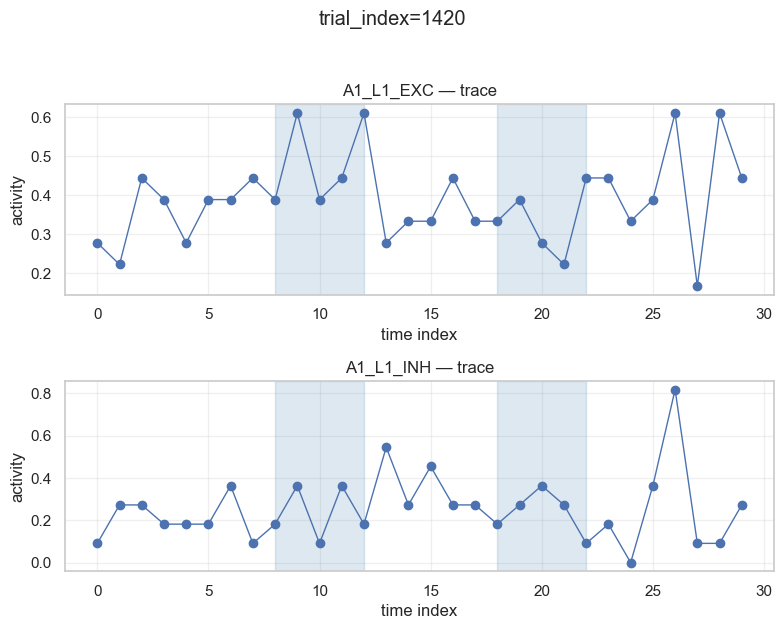

In [ ]:

PATH = "../data/raw/train.csv"
E1 = range(8, 13)
E2 = range(18, 23)
N_TRIALS_TO_SHOW = 1
N_TRACES_TO_SHOW = 2
EPS = 1e-12

df = pd.read_csv(PATH)

# Find time-binned columns "<base>_time_<k>"
pat = re.compile(r"^(.*)_time_(\d+)$")
time_cols = []
for c in df.columns:
    m = pat.match(c)
    if m:
        base = m.group(1)
        t = int(m.group(2))
        time_cols.append((c, base, t))
if not time_cols:
    raise ValueError("No columns match pattern '<base>_time_<k>'.")

# Group by base -> [(t, col), ...]
by_base = {}
for c, base, t in time_cols:
    by_base.setdefault(base, []).append((t, c))

bases = sorted(by_base.keys())
np.random.seed(0)
trial_idxs = np.random.choice(df.index.values, size=min(N_TRIALS_TO_SHOW, len(df)), replace=False)

def get_trace(df_row, base):
    tc = sorted(by_base[base], key=lambda x: x[0])
    t_vals = [t for t, _ in tc]
    x_vals = np.array([df_row[col] for _, col in tc], dtype=float)
    return np.array(t_vals), x_vals

for ridx in trial_idxs:
    row = df.loc[ridx]

    # pick bases that are not all zero/NaN for THIS trial
    bases_nonflat = []
    for b in bases:
        _, x = get_trace(row, b)
        if np.isnan(x).all():
            continue
        if np.all(np.abs(x) < EPS):
            continue
        bases_nonflat.append(b)

    if len(bases_nonflat) == 0:
        raise ValueError(f"No non-flat traces for trial {ridx}.")
    bases_show = bases_nonflat[:N_TRACES_TO_SHOW]

    fig = plt.figure(figsize=(8, 3.2 * len(bases_show)))
    fig.suptitle(f"trial_index={ridx}")
    for i, base in enumerate(bases_show, start=1):
        t, x = get_trace(row, base)
        ax = plt.subplot(len(bases_show), 1, i)
        ax.plot(t, x, marker="o", linewidth=1)
        ax.axvspan(min(E1), max(E1), alpha=0.18, color="steelblue")
        ax.axvspan(min(E2), max(E2), alpha=0.18, color="steelblue")
        ax.set_title(f"{base} — trace")
        ax.set_xlabel("time index")
        ax.set_ylabel("activity")
        ax.grid(True, alpha=0.3)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

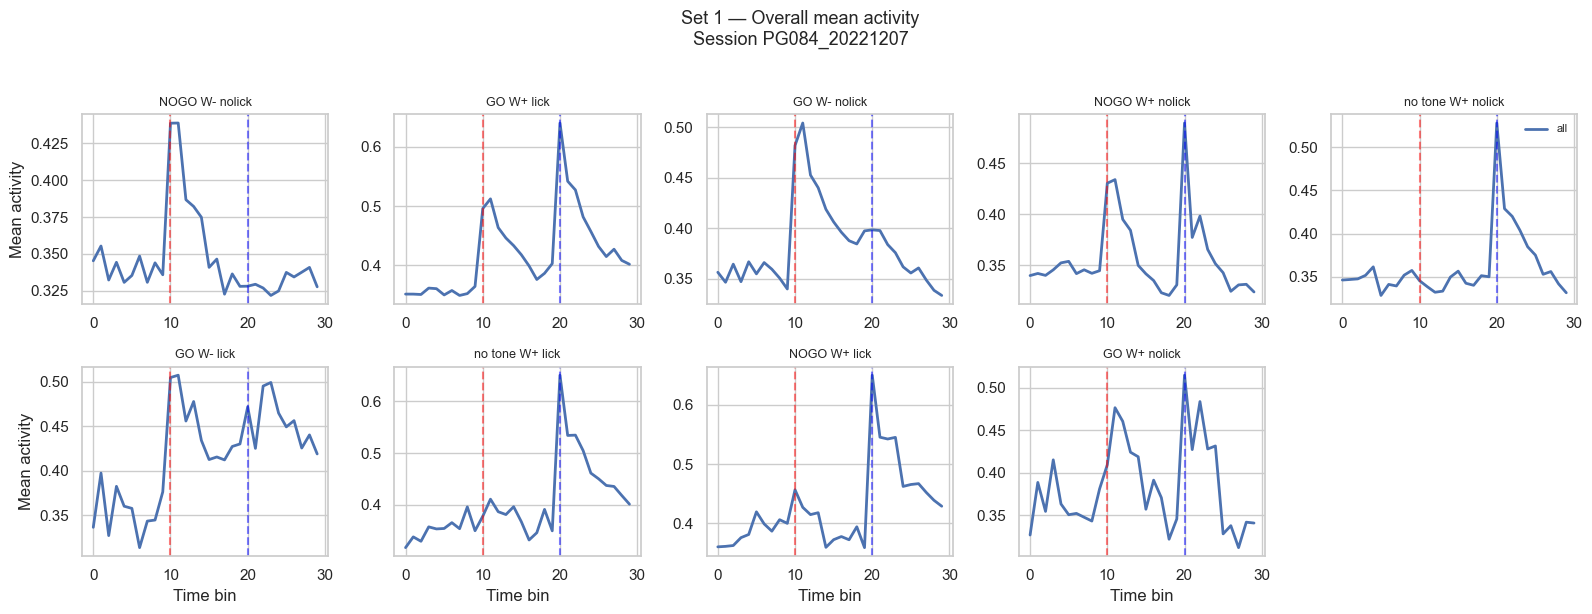

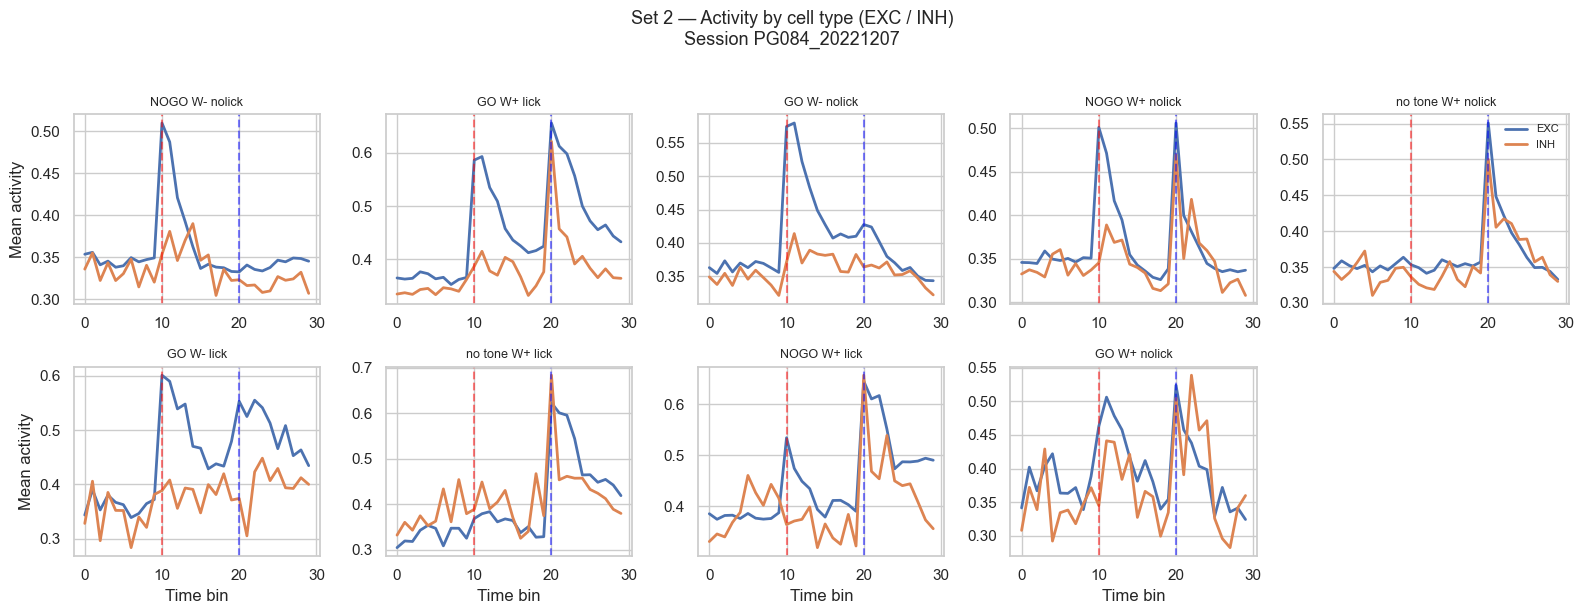

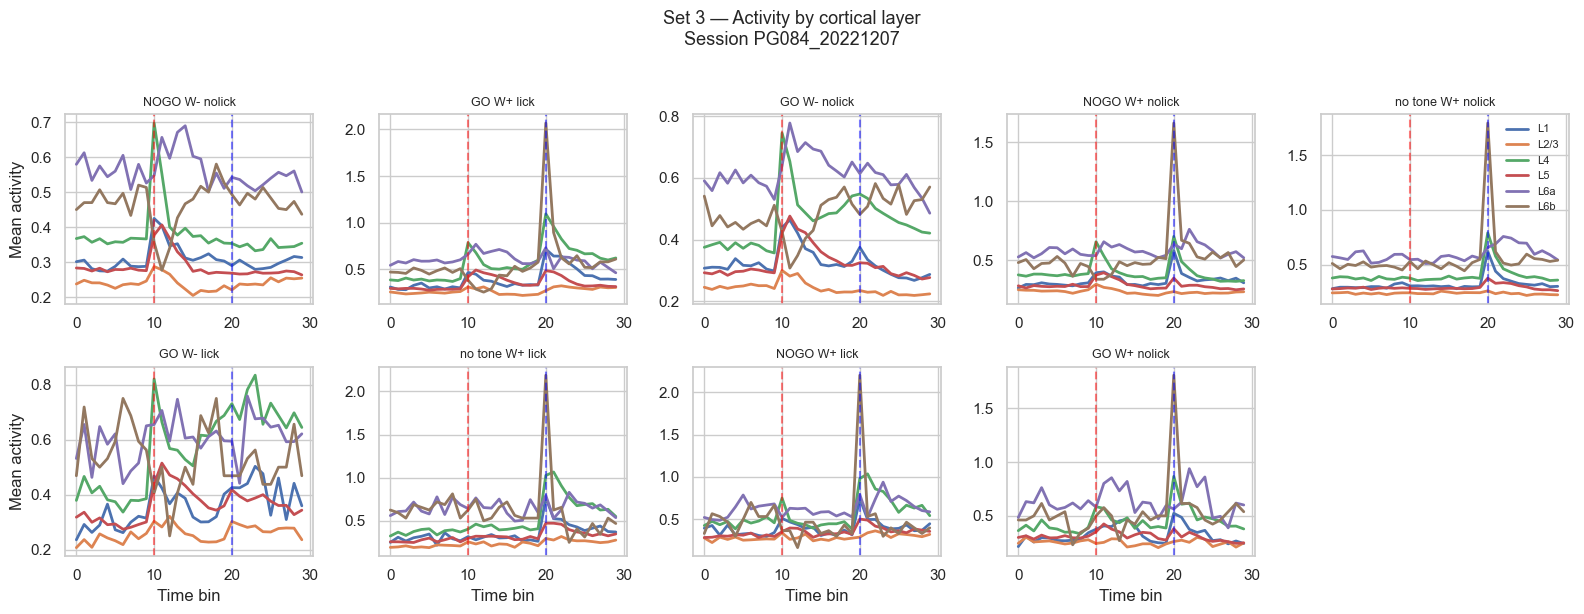

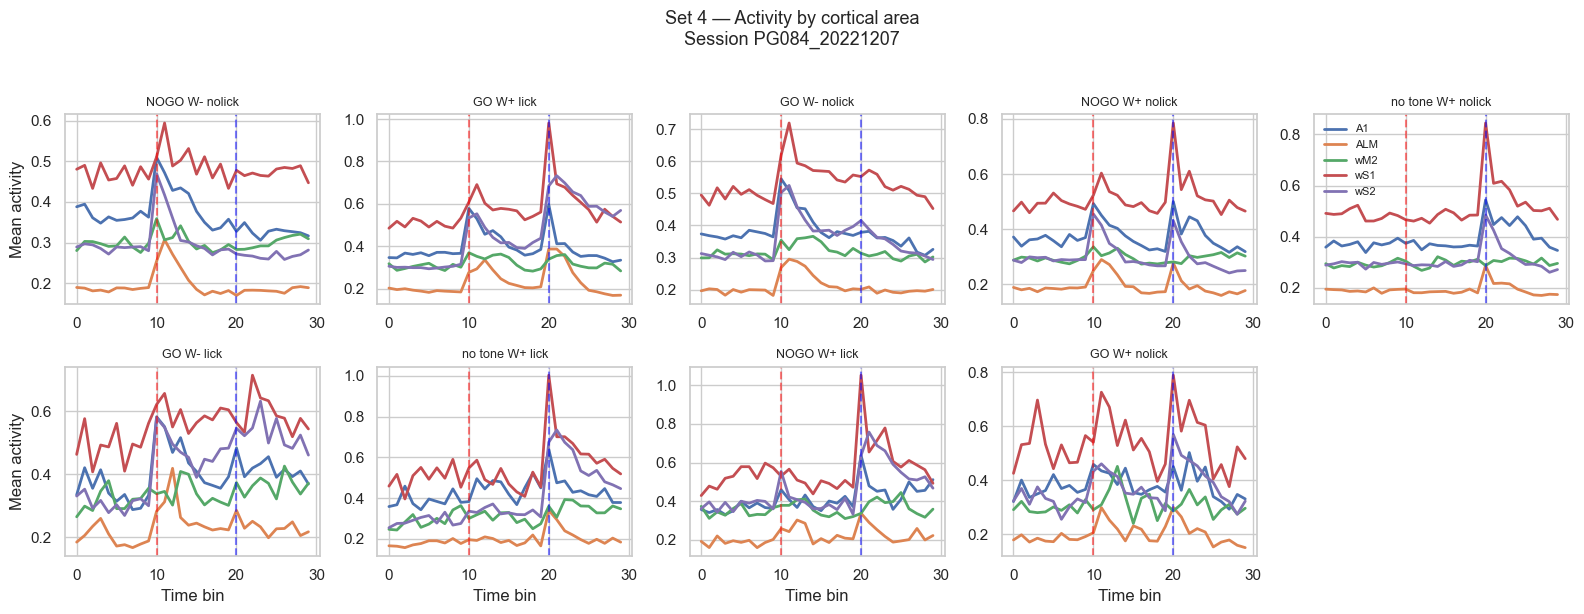

In [ ]:
#Four plot sets (overall, by cell type, by layer, by area) for the biggest session

# Pick the session with the most trials
session_top = train_df['session_id'].value_counts().idxmax()
session_df = train_df[train_df['session_id'] == session_top].copy()

# Top-10 trial types in that session
top_trial_types = (
    session_df['TRIAL_TYPE']
    .value_counts()
    .head(10)
    .index
    .tolist()
)

# Helpers
TIME_BINS = range(30)

def mean_trace(df_block, cols):
    out = []
    for t in TIME_BINS:
        cols_t = [c for c in cols if col_time[c] == t]
        if len(cols_t) == 0:
            out.append(np.nan)
        else:
            out.append(df_block[cols_t].mean(axis=1).mean())
    return out

def plot_grid(title, traces_dict):
    plt.figure(figsize=(16, 6))
    for i, tt in enumerate(top_trial_types, 1):
        plt.subplot(2, 5, i)
        for lbl, trace in traces_dict[tt].items():
            plt.plot(TIME_BINS, trace, label=lbl, linewidth=2)
        plt.axvline(10, color='red', linestyle='--', alpha=0.5)
        plt.axvline(20, color='blue', linestyle='--', alpha=0.5)
        plt.title(tt, fontsize=9)
        if i in (1, 6):
            plt.ylabel('Mean activity')
        if i > 5:
            plt.xlabel('Time bin')
        if i == 5:
            plt.legend(fontsize=8, frameon=False)
        plt.tight_layout()
    plt.suptitle(f"{title}\nSession {session_top}", y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

# Precompute feature groups
col_time = column_df.set_index('column')['time']
features_all = [c for c in feature_cols]  # already excludes metadata
features_by_cell = {ct: column_df.loc[column_df['cell_type'] == ct, 'column'].tolist()
                    for ct in sorted(column_df['cell_type'].unique())}
features_by_layer = {ly: column_df.loc[column_df['layer'] == ly, 'column'].tolist()
                     for ly in sorted(column_df['layer'].unique())}
features_by_area = {ar: column_df.loc[column_df['area'] == ar, 'column'].tolist()
                    for ar in sorted(column_df['area'].unique())}

# 1) Overall (all neurons)
traces_overall = {}
for tt in top_trial_types:
    df_tt = session_df[session_df['TRIAL_TYPE'] == tt]
    traces_overall[tt] = {'all': mean_trace(df_tt, features_all)}
plot_grid("Set 1 — Overall mean activity", traces_overall)

# 2) By cell type (EXC / INH)
traces_cell = {}
for tt in top_trial_types:
    df_tt = session_df[session_df['TRIAL_TYPE'] == tt]
    traces_cell[tt] = {}
    for ct, cols_ct in features_by_cell.items():
        if len(cols_ct):
            traces_cell[tt][ct] = mean_trace(df_tt, cols_ct)
plot_grid("Set 2 — Activity by cell type (EXC / INH)", traces_cell)

# 3) By layer
traces_layer = {}
for tt in top_trial_types:
    df_tt = session_df[session_df['TRIAL_TYPE'] == tt]
    traces_layer[tt] = {}
    for ly, cols_ly in features_by_layer.items():
        if len(cols_ly):
            traces_layer[tt][ly] = mean_trace(df_tt, cols_ly)
plot_grid("Set 3 — Activity by cortical layer", traces_layer)

# 4) By area
traces_area = {}
for tt in top_trial_types:
    df_tt = session_df[session_df['TRIAL_TYPE'] == tt]
    traces_area[tt] = {}
    for ar, cols_ar in features_by_area.items():
        if len(cols_ar):
            traces_area[tt][ar] = mean_trace(df_tt, cols_ar)
plot_grid("Set 4 — Activity by cortical area", traces_area)


Based on these plots, several discriminative patterns could be engineered into features (e.g., windowed AUC, peak height, or ratios across time windows). In the third subplot, W+ trials show a sharp peak in layer L6b around bin 20, whereas W− trials lack this peak and remain noisy. In the second subplot, “no tone” trials display almost no activity near the tone window (bin ≈10), clearly separating them from GO/NOGO conditions.


# 6. Conclusion

Overall, the analysis shows that a well‑regularized linear logistic regression with per‑session z‑score, ANOVA on roughly 400 features, and simple imputation already performs strongly (LOSO ≈0.52, Kaggle ≈0.596), and that XGBoost only brings a modest additional gain (Kaggle ≈0.63); the main unexploited advantage of non‑linear models would have been to design richer engineered features on which they could react better, as discussed in the feature engineering section. Per‑session z‑scoring is essential to reduce session batch effects, zero/mean imputation after normalization is sufficient, ANOVA top‑400 selection is beneficial, and heavier imputers such as kNN for XGBoost add little benefit, while ANOVA confirms that post‑stimulus bins and excitatory units dominate, with time‑locked peaks around tone bin ~10, whisker bin ~20, and the response window (bins 20–30), including an L6b peak for whisker+ around bin 20 and flat activity near bin 10 for no‑tone. Confusion matrices show that clearly distinct trial types such as GO W+ lick are well separated, whereas pairs differing by a single cue are more prone to misclassification, and the decoding hierarchy from section 4.1.4 indicates that lick vs no‑lick is easiest, whisker presence is intermediate, and tone is hardest to predict. Finally, data cluster primarily by session (two sessions per mouse), LOSO across sessions with per‑session z‑score yields accuracies consistent with the Kaggle score, and using leave‑one‑session‑out throughout is necessary to obtain coherent, representative performance estimates that do not rely on session‑specific idiosyncrasies.